In [ ]:
from google.colab import drive

# Mount Google Drive to a new, empty mount point
drive.mount("/content/gdrive")

Mounted at /content/gdrive


In [ ]:
import os

os.makedirs("/content/gdrive", exist_ok=True)

In [ ]:
features_dir = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/02_Features"

print(os.listdir(features_dir))

['lol_v2_train_pairs.csv', 'lol_v2_train_features.csv', 'lol_v2_pseudo_labels.csv']


In [ ]:
BASE_DIR = "/content/gdrive/MyDrive/Adaptive_LowLight_Research"

In [ ]:
import os
import json
import shutil
import time
import random
import sys
import subprocess
from datetime import datetime

BASE_DIR = "/content/drive/MyDrive/Adaptive_LowLight_Research"

folders = [
    "00_Project_Info",

    "01_Datasets/LOL_v2",
    "01_Datasets/LOL",
    "01_Datasets/ExDark",
    "01_Datasets/SID",

    "02_Features",

    "03_Models/ZeroDCE",
    "03_Models/Adaptive_Predictor",
    "03_Models/checkpoints",

    "04_Training",
    "04_Training/graphs",
    "04_Training/checkpoints",

    "05_Validation/LOL",
    "05_Validation/LOL/enhanced_images",
    "05_Validation/LOL/comparisons",
    "05_Validation/LOL/graphs",

    "06_ExDark",
    "06_ExDark/enhanced_images",
    "06_ExDark/comparisons",
    "06_ExDark/graphs",

    "07_SID",
    "07_SID/enhanced_images",
    "07_SID/comparisons",
    "07_SID/graphs",

    "08_Ablation",
    "08_Ablation/images",
    "08_Ablation/graphs",
    "08_Ablation/tables",

    "09_Backbone_Comparison",
    "09_Backbone_Comparison/images",
    "09_Backbone_Comparison/graphs",
    "09_Backbone_Comparison/tables",

    "10_Final_Results",
    "10_Final_Results/figures",
    "10_Final_Results/tables",
    "10_Final_Results/enhanced_images",

    "11_Logs"
]

for folder in folders:
    os.makedirs(
        os.path.join(BASE_DIR, folder),
        exist_ok=True
    )

print("Project created:")
print(BASE_DIR)

Project created:
/content/drive/MyDrive/Adaptive_LowLight_Research


In [ ]:
PATHS = {

    # Main
    "base": BASE_DIR,

    # Datasets
    "lol_v2": os.path.join(
        BASE_DIR,
        "01_Datasets/LOL_v2"
    ),

    "lol": os.path.join(
        BASE_DIR,
        "01_Datasets/LOL"
    ),

    "exdark": os.path.join(
        BASE_DIR,
        "01_Datasets/ExDark"
    ),

    "sid": os.path.join(
        BASE_DIR,
        "01_Datasets/SID"
    ),

    # Features
    "features": os.path.join(
        BASE_DIR,
        "02_Features"
    ),

    # Models
    "zerodce": os.path.join(
        BASE_DIR,
        "03_Models/ZeroDCE"
    ),

    "predictor": os.path.join(
        BASE_DIR,
        "03_Models/Adaptive_Predictor"
    ),

    "checkpoints": os.path.join(
        BASE_DIR,
        "03_Models/checkpoints"
    ),

    # Training
    "training": os.path.join(
        BASE_DIR,
        "04_Training"
    ),

    # Validation
    "validation": os.path.join(
        BASE_DIR,
        "05_Validation/LOL"
    ),

    # ExDark
    "exdark_results": os.path.join(
        BASE_DIR,
        "06_ExDark"
    ),

    # SID
    "sid_results": os.path.join(
        BASE_DIR,
        "07_SID"
    ),

    # Ablation
    "ablation": os.path.join(
        BASE_DIR,
        "08_Ablation"
    ),

    # Backbone
    "backbone": os.path.join(
        BASE_DIR,
        "09_Backbone_Comparison"
    ),

    # Final
    "final": os.path.join(
        BASE_DIR,
        "10_Final_Results"
    ),

    # Logs
    "logs": os.path.join(
        BASE_DIR,
        "11_Logs"
    )
}

print(json.dumps(PATHS, indent=2))

{
  "base": "/content/drive/MyDrive/Adaptive_LowLight_Research",
  "lol_v2": "/content/drive/MyDrive/Adaptive_LowLight_Research/01_Datasets/LOL_v2",
  "lol": "/content/drive/MyDrive/Adaptive_LowLight_Research/01_Datasets/LOL",
  "exdark": "/content/drive/MyDrive/Adaptive_LowLight_Research/01_Datasets/ExDark",
  "sid": "/content/drive/MyDrive/Adaptive_LowLight_Research/01_Datasets/SID",
  "features": "/content/drive/MyDrive/Adaptive_LowLight_Research/02_Features",
  "zerodce": "/content/drive/MyDrive/Adaptive_LowLight_Research/03_Models/ZeroDCE",
  "predictor": "/content/drive/MyDrive/Adaptive_LowLight_Research/03_Models/Adaptive_Predictor",
  "checkpoints": "/content/drive/MyDrive/Adaptive_LowLight_Research/03_Models/checkpoints",
  "training": "/content/drive/MyDrive/Adaptive_LowLight_Research/04_Training",
  "validation": "/content/drive/MyDrive/Adaptive_LowLight_Research/05_Validation/LOL",
  "exdark_results": "/content/drive/MyDrive/Adaptive_LowLight_Research/06_ExDark",
  "sid_res

In [ ]:
config = {
    "project_name": "Adaptive Texture-Aware Low-Light Image Enhancement",

    "training_dataset": "LOL-v2",

    "validation_dataset": "LOL",

    "real_world_dataset": "ExDark",

    "generalization_dataset": "SID",

    "primary_model": "Zero-DCE++",

    "alternative_models": [
        "RetinexNet",
        "PromptIR",
        "RetinexFormer"
    ],

    "features": [
        "Texture",
        "Brightness",
        "Entropy",
        "Edge Density"
    ],

    "adaptive_parameters": [
        "Enhancement Strength",
        "Contrast",
        "Denoising Strength"
    ],

    "evaluation_metrics": [
        "PSNR",
        "SSIM",
        "NIQE",
        "BRISQUE",
        "Detection mAP",
        "Inference Time"
    ]
}

config_path = os.path.join(
    PATHS["base"],
    "00_Project_Info/experiment_config.json"
)

with open(config_path, "w") as f:
    json.dump(
        config,
        f,
        indent=4
    )

print("Configuration saved.")

Configuration saved.


In [ ]:
!pip install -q \
    scikit-image \
    opencv-python \
    pandas \
    matplotlib \
    seaborn \
    tqdm \
    lpips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 4.4 MB/s eta 0:00:00


In [ ]:
import os
import sys
import cv2
import json
import math
import time
import random
import shutil
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from skimage.feature import (
    local_binary_pattern,
    graycomatrix,
    graycoprops
)

from skimage.measure import shannon_entropy

from skimage.metrics import structural_similarity

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Device: cuda


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random seed:", SEED)

Random seed: 42


In [ ]:
environment_path = os.path.join(
    PATHS["logs"],
    "environment.txt"
)

with open(environment_path, "w") as f:

    f.write("ADAPTIVE LOW-LIGHT RESEARCH ENVIRONMENT\n")
    f.write("=" * 60 + "\n\n")

    f.write(
        f"Date: {datetime.now()}\n"
    )

    f.write(
        f"Python: {sys.version}\n\n"
    )

    f.write(
        f"PyTorch: {torch.__version__}\n"
    )

    f.write(
        f"CUDA available: {torch.cuda.is_available()}\n"
    )

    f.write(
        f"CUDA version: {torch.version.cuda}\n"
    )

    if torch.cuda.is_available():

        f.write(
            f"GPU: {torch.cuda.get_device_name(0)}\n"
        )

    f.write("\n\nPIP PACKAGES\n")
    f.write("=" * 60 + "\n")

    try:

        packages = subprocess.check_output(
            ["pip", "freeze"],
            text=True
        )

        f.write(packages)

    except Exception as e:

        f.write(str(e))

print("Environment saved:")
print(environment_path)

Environment saved:
/content/drive/MyDrive/Adaptive_LowLight_Research/11_Logs/environment.txt


In [ ]:
LOG_FILE = os.path.join(
    PATHS["logs"],
    "experiment_log.txt"
)

def log(message):

    timestamp = datetime.now().strftime(
        "%Y-%m-%d %H:%M:%S"
    )

    line = f"[{timestamp}] {message}"

    print(line)

    with open(LOG_FILE, "a") as f:
        f.write(line + "\n")


log("Project initialized.")

[2026-09-27 18:41:24] Project initialized.


## Install Zero-DCE++

In [ ]:
ZERODCE_REPO = "/content/Zero-DCE_extension"

if not os.path.exists(ZERODCE_REPO):

    !git clone https://github.com/Li-Chongyi/Zero-DCE_extension.git /content/Zero-DCE_extension

else:

    print("Zero-DCE++ repository already exists.")

Cloning into '/content/Zero-DCE_extension'...
remote: Enumerating objects: 2140, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 2140 (delta 0), reused 2 (delta 0), pack-reused 2136 (from 1)
Receiving objects: 100% (2140/2140), 100.92 MiB | 15.44 MiB/s, done.
Resolving deltas: 100% (15/15), done.
Updating files: 100% (2078/2078), done.


## Load Zero-DCE++

In [ ]:
ZERO_DCE_DIR = (
    "/content/Zero-DCE_extension/Zero-DCE++"
)

sys.path.insert(
    0,
    ZERO_DCE_DIR
)

import model

print("Zero-DCE++ module imported.")

Zero-DCE++ module imported.


## Load Pretrained Model

In [ ]:
DCE_net = model.enhance_net_nopool(12).to(device)

MODEL_PATH = (
    "/content/Zero-DCE_extension/"
    "Zero-DCE++/snapshots_Zero_DCE++/Epoch99.pth"
)

state_dict = torch.load(
    MODEL_PATH,
    map_location=device
)

DCE_net.load_state_dict(
    state_dict
)

DCE_net.eval()

for param in DCE_net.parameters():
    param.requires_grad = False

print("Zero-DCE++ loaded successfully.")

log("Zero-DCE++ pretrained model loaded.")

Zero-DCE++ loaded successfully.
[2026-09-27 18:41:36] Zero-DCE++ pretrained model loaded.


## Image Loading

In [ ]:
def load_rgb_image(path):

    image = Image.open(
        path
    ).convert("RGB")

    return np.array(image)

## Convert Image to Tensor

In [ ]:
def image_to_tensor(image):

    image_np = (
        image.astype(np.float32)
        / 255.0
    )

    h = (
        image_np.shape[0] // 12
    ) * 12

    w = (
        image_np.shape[1] // 12
    ) * 12

    image_np = image_np[
        :h,
        :w,
        :
    ]

    tensor = (
        torch.from_numpy(image_np)
        .permute(2, 0, 1)
        .unsqueeze(0)
        .to(device)
    )

    return tensor

## Zero-DCE++ Inference

In [ ]:
def run_zerodce(image):

    tensor = image_to_tensor(
        image
    )

    start_time = time.time()

    with torch.no_grad():

        enhanced, curve_maps = DCE_net(
            tensor
        )

    inference_time = (
        time.time() - start_time
    )

    enhanced = torch.clamp(
        enhanced,
        0,
        1
    )

    enhanced_np = (
        enhanced
        .squeeze(0)
        .permute(1, 2, 0)
        .cpu()
        .numpy()
    )

    enhanced_np = (
        np.clip(
            enhanced_np * 255,
            0,
            255
        )
        .astype(np.uint8)
    )

    return (
        enhanced_np,
        curve_maps,
        inference_time
    )

## Texture Feature: LBP

In [ ]:
def calculate_lbp_texture(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    gray = cv2.resize(
        gray,
        (256, 256)
    )

    radius = 1
    points = 8 * radius

    lbp = local_binary_pattern(
        gray,
        points,
        radius,
        method="uniform"
    )

    n_bins = points + 2

    histogram, _ = np.histogram(
        lbp.ravel(),
        bins=n_bins,
        range=(0, n_bins)
    )

    histogram = histogram.astype(
        np.float64
    )

    histogram /= (
        histogram.sum() + 1e-12
    )

    histogram += 1e-12

    lbp_entropy = -np.sum(
        histogram *
        np.log2(histogram)
    )

    return float(
        lbp_entropy /
        np.log2(n_bins)
    )

## GLCM

In [ ]:
def calculate_glcm_features(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    gray = cv2.resize(
        gray,
        (256, 256)
    )

    gray_quantized = (
        gray / 32
    ).astype(np.uint8)

    gray_quantized = np.clip(
        gray_quantized,
        0,
        7
    )

    distances = [1, 2]

    angles = [
        0,
        np.pi / 4,
        np.pi / 2,
        3 * np.pi / 4
    ]

    glcm = graycomatrix(
        gray_quantized,
        distances=distances,
        angles=angles,
        levels=8,
        symmetric=True,
        normed=True
    )

    contrast = graycoprops(
        glcm,
        "contrast"
    ).mean()

    homogeneity = graycoprops(
        glcm,
        "homogeneity"
    ).mean()

    energy = graycoprops(
        glcm,
        "energy"
    ).mean()

    return (
        float(contrast),
        float(homogeneity),
        float(energy)
    )

## Combined Texture

In [ ]:
def calculate_texture(image):

    lbp_score = calculate_lbp_texture(
        image
    )

    (
        glcm_contrast,
        _,
        _
    ) = calculate_glcm_features(
        image
    )

    glcm_score = np.clip(
        glcm_contrast / 49.0,
        0,
        1
    )

    texture = (
        0.5 * lbp_score
        +
        0.5 * glcm_score
    )

    return float(texture)

## Brightness

In [ ]:
def calculate_brightness(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    return float(
        np.mean(gray) / 255.0
    )

## Entropy

In [ ]:
def calculate_entropy(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    return float(
        shannon_entropy(gray)
    )

## Edge Density

In [ ]:
def calculate_edge_density(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    gray_enhanced = clahe.apply(
        gray
    )

    median = np.median(
        gray_enhanced
    )

    lower = int(
        max(
            10,
            0.66 * median
        )
    )

    upper = int(
        max(
            lower + 20,
            1.33 * median
        )
    )

    upper = min(
        upper,
        255
    )

    edges = cv2.Canny(
        gray_enhanced,
        lower,
        upper
    )

    return float(
        np.mean(edges > 0)
    )

## Complete Feature Extraction

In [ ]:
def extract_features(image):

    texture = calculate_texture(
        image
    )

    brightness = calculate_brightness(
        image
    )

    entropy = calculate_entropy(
        image
    )

    edge_density = calculate_edge_density(
        image
    )

    lbp = calculate_lbp_texture(
        image
    )

    (
        glcm_contrast,
        glcm_homogeneity,
        glcm_energy
    ) = calculate_glcm_features(
        image
    )

    return {

        "texture": texture,

        "brightness": brightness,

        "entropy": entropy,

        "edge_density": edge_density,

        "lbp": lbp,

        "glcm_contrast":
            glcm_contrast,

        "glcm_homogeneity":
            glcm_homogeneity,

        "glcm_energy":
            glcm_energy
    }

In [ ]:
# ============================================================
# PART 24 — Open official LOL-v2 dataset repository
# ============================================================

import requests

url = "https://github.com/flyywh/CVPR-2020-Semi-Low-Light"

response = requests.get(url)

print("Status:", response.status_code)
print("Official repository accessible:", response.status_code == 200)

Status: 200
Official repository accessible: True


In [ ]:
# ============================================================
# PART 25 — Clone LOL-v2 dataset repository
# ============================================================

import os

repo_dir = "/content/CVPR-2020-Semi-Low-Light"

if not os.path.exists(repo_dir):
    !git clone https://github.com/flyywh/CVPR-2020-Semi-Low-Light.git /content/CVPR-2020-Semi-Low-Light
else:
    print("Repository already exists.")

print("\nRepository contents:")
!find /content/CVPR-2020-Semi-Low-Light -maxdepth 2 -type f | head -30

Cloning into '/content/CVPR-2020-Semi-Low-Light'...
remote: Enumerating objects: 271, done.
remote: Counting objects: 100% (118/118), done.
remote: Compressing objects: 100% (88/88), done.
remote: Total 271 (delta 51), reused 37 (delta 13), pack-reused 153 (from 1)
Receiving objects: 100% (271/271), 19.27 MiB | 19.03 MiB/s, done.
Resolving deltas: 100% (102/102), done.

Repository contents:
/content/CVPR-2020-Semi-Low-Light/teaser/teaser_DRBN.png
/content/CVPR-2020-Semi-Low-Light/teaser/tmp.txt
/content/CVPR-2020-Semi-Low-Light/README.md
/content/CVPR-2020-Semi-Low-Light/.git/index
/content/CVPR-2020-Semi-Low-Light/.git/config
/content/CVPR-2020-Semi-Low-Light/.git/packed-refs
/content/CVPR-2020-Semi-Low-Light/.git/HEAD
/content/CVPR-2020-Semi-Low-Light/.git/description


In [ ]:
# ============================================================
# PART 26 — Download LOL-v2
# ============================================================

import os
import gdown

download_dir = "/content/LOL_v2_download"
os.makedirs(download_dir, exist_ok=True)

file_id = "1dzuLCk9_gE2bFF222n3-7GVUlSVHpMYC"
output_file = os.path.join(download_dir, "LOL-v2.zip")

print("Downloading LOL-v2...")
print("Destination:", output_file)

gdown.download(
    id=file_id,
    output=output_file,
    quiet=False
)

print("\nDownload completed.")
print("File exists:", os.path.exists(output_file))

if os.path.exists(output_file):
    size_gb = os.path.getsize(output_file) / (1024**3)
    print(f"File size: {size_gb:.2f} GB")

Destination: /content/LOL_v2_download/LOL-v2.zip


Downloading...
From (original): https://drive.google.com/uc?id=1dzuLCk9_gE2bFF222n3-7GVUlSVHpMYC
From (redirected): https://drive.google.com/uc?id=1dzuLCk9_gE2bFF222n3-7GVUlSVHpMYC&confirm=t&uuid=12dd10c9-20d1-4717-9e50-f42f29ce4398
To: /content/LOL_v2_download/LOL-v2.zip
100%|██████████| 1.05G/1.05G [00:04<00:00, 229MB/s]


Download completed.
File exists: True
File size: 0.97 GB


In [ ]:
# ============================================================
# PART 29 — Extract LOL-v2 to Google Drive
# ============================================================

import os
import zipfile
import shutil

zip_path = "/content/LOL_v2_download/LOL-v2.zip"

drive_dataset_dir = PATHS["lol_v2"]

# Remove existing empty directory contents if necessary
os.makedirs(drive_dataset_dir, exist_ok=True)

print("Extracting LOL-v2...")
print("Destination:", drive_dataset_dir)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/lol_v2_temp")

# The ZIP contains a top-level LOL-v2 folder.
source_dir = "/content/lol_v2_temp/LOL-v2"

# Copy contents into our Drive dataset folder
for item in os.listdir(source_dir):
    src = os.path.join(source_dir, item)
    dst = os.path.join(drive_dataset_dir, item)

    if os.path.isdir(src):
        if os.path.exists(dst):
            shutil.rmtree(dst)
        shutil.copytree(src, dst)
    else:
        shutil.copy2(src, dst)

print("\nLOL-v2 successfully copied to Google Drive.")

Extracting LOL-v2...
Destination: /content/drive/MyDrive/Adaptive_LowLight_Research/01_Datasets/LOL_v2

LOL-v2 successfully copied to Google Drive.


In [ ]:
# ============================================================
# PART 30 — Verify LOL-v2
# ============================================================

import os

train_low = os.path.join(
    PATHS["lol_v2"],
    "Real_captured",
    "Train",
    "Low"
)

train_normal = os.path.join(
    PATHS["lol_v2"],
    "Real_captured",
    "Train",
    "Normal"
)

test_low = os.path.join(
    PATHS["lol_v2"],
    "Real_captured",
    "Test",
    "Low"
)

test_normal = os.path.join(
    PATHS["lol_v2"],
    "Real_captured",
    "Test",
    "Normal"
)

for name, path in [
    ("Train Low", train_low),
    ("Train Normal", train_normal),
    ("Test Low", test_low),
    ("Test Normal", test_normal)
]:
    files = [
        f for f in os.listdir(path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print(f"{name:15s}: {len(files)} images")

Train Low      : 689 images
Train Normal   : 689 images
Test Low       : 100 images
Test Normal    : 100 images


In [ ]:
# ============================================================
# PART 31 — Verify Low/Normal Pairing
# ============================================================

import os
import re

def get_image_ids(folder, prefix):
    ids = set()

    for filename in os.listdir(folder):
        if filename.lower().endswith(".png"):
            match = re.search(rf"{prefix}(\d+)", filename.lower())

            if match:
                ids.add(match.group(1))

    return ids


train_low_ids = get_image_ids(train_low, "low")
train_normal_ids = get_image_ids(train_normal, "normal")

test_low_ids = get_image_ids(test_low, "low")
test_normal_ids = get_image_ids(test_normal, "normal")

print("Training pairs")
print("Low images:", len(train_low_ids))
print("Normal images:", len(train_normal_ids))
print("Matched:", len(train_low_ids & train_normal_ids))
print("Missing Low:", len(train_normal_ids - train_low_ids))
print("Missing Normal:", len(train_low_ids - train_normal_ids))

print("\nTesting pairs")
print("Low images:", len(test_low_ids))
print("Normal images:", len(test_normal_ids))
print("Matched:", len(test_low_ids & test_normal_ids))
print("Missing Low:", len(test_normal_ids - test_low_ids))
print("Missing Normal:", len(test_low_ids - test_normal_ids))

Training pairs
Low images: 689
Normal images: 689
Matched: 689
Missing Low: 0
Missing Normal: 0

Testing pairs
Low images: 100
Normal images: 100
Matched: 100
Missing Low: 0
Missing Normal: 0


In [ ]:
# ============================================================
# PART 32 — Create LOL-v2 Training Pair List
# ============================================================

import os
import pandas as pd

train_low_dir = os.path.join(
    PATHS["lol_v2"],
    "Real_captured",
    "Train",
    "Low"
)

train_normal_dir = os.path.join(
    PATHS["lol_v2"],
    "Real_captured",
    "Train",
    "Normal"
)

pairs = []

for filename in sorted(os.listdir(train_low_dir)):

    if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
        continue

    # Example:
    # low00001.png -> normal00001.png
    image_id = filename.replace("low", "").rsplit(".", 1)[0]

    normal_filename = f"normal{image_id}.png"

    low_path = os.path.join(train_low_dir, filename)
    normal_path = os.path.join(train_normal_dir, normal_filename)

    if os.path.exists(normal_path):

        pairs.append({
            "id": image_id,
            "low_path": low_path,
            "normal_path": normal_path
        })

pair_df = pd.DataFrame(pairs)

print("Total training pairs:", len(pair_df))
display(pair_df.head())

Total training pairs: 689


,id,low_path,normal_path
0,00001,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...
1,00002,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...
2,00003,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...
3,00004,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...
4,00005,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...


In [ ]:
# ============================================================
# PART 33 — Save Training Pair List
# ============================================================

pair_list_path = os.path.join(
    PATHS["features"],
    "lol_v2_train_pairs.csv"
)

pair_df.to_csv(pair_list_path, index=False)

print("Pair list saved:")
print(pair_list_path)

Pair list saved:
/content/drive/MyDrive/Adaptive_LowLight_Research/02_Features/lol_v2_train_pairs.csv


Low image: (600, 400)
Normal image: (600, 400)


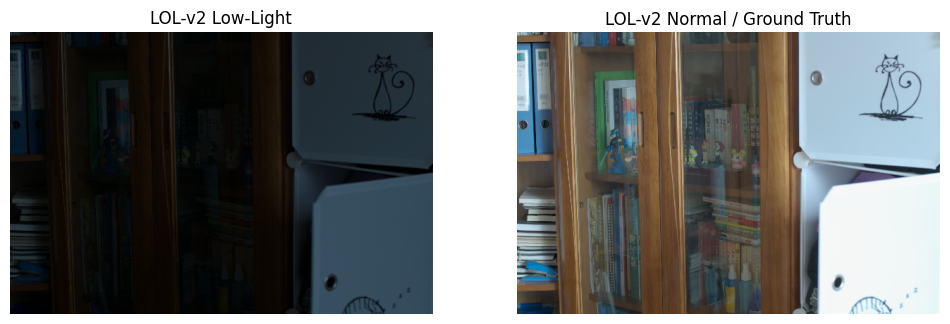

In [ ]:
# ============================================================
# PART 34 — Test One Training Pair
# ============================================================

from PIL import Image
import matplotlib.pyplot as plt

sample = pair_df.iloc[0]

low_img = Image.open(sample["low_path"]).convert("RGB")
normal_img = Image.open(sample["normal_path"]).convert("RGB")

print("Low image:", low_img.size)
print("Normal image:", normal_img.size)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(low_img)
plt.title("LOL-v2 Low-Light")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(normal_img)
plt.title("LOL-v2 Normal / Ground Truth")
plt.axis("off")

plt.show()

In [ ]:
# ============================================================
# PART 35 — Feature Extraction Test
# ============================================================

sample_low = np.array(
    Image.open(sample["low_path"]).convert("RGB")
)

sample_features = extract_features(sample_low)

print("Extracted features:")
for key, value in sample_features.items():
    print(f"{key:20s}: {value:.6f}")

Extracted features:
texture             : 0.468456
brightness          : 0.096625
entropy             : 5.475845
edge_density        : 0.171146
lbp                 : 0.936108
glcm_contrast       : 0.039442
glcm_homogeneity    : 0.981435
glcm_energy         : 0.706217


## Extract Features for All LOL-v2 Training Images

In [ ]:
# ============================================================
# PART 36 — Extract Features for LOL-v2 Training Set
# ============================================================

import time

feature_records = []

start_time = time.time()

for idx, row in pair_df.iterrows():

    image = np.array(
        Image.open(row["low_path"]).convert("RGB")
    )

    features = extract_features(image)

    record = {
        "id": row["id"],
        "low_path": row["low_path"],
        "normal_path": row["normal_path"],
        "texture": features["texture"],
        "brightness": features["brightness"],
        "entropy": features["entropy"],
        "edge_density": features["edge_density"]
    }

    feature_records.append(record)

    if (idx + 1) % 50 == 0:
        print(f"Processed {idx + 1}/{len(pair_df)}")

feature_df = pd.DataFrame(feature_records)

elapsed = time.time() - start_time

print("\nFeature extraction completed.")
print(f"Time: {elapsed/60:.2f} minutes")

display(feature_df.head())

Processed 50/689
Processed 100/689
Processed 150/689
Processed 200/689
Processed 250/689
Processed 300/689
Processed 350/689
Processed 400/689
Processed 450/689
Processed 500/689
Processed 550/689
Processed 600/689
Processed 650/689

Feature extraction completed.
Time: 0.76 minutes


,id,low_path,normal_path,texture,brightness,entropy,edge_density
0,00001,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...,0.468456,0.096625,5.475845,0.171146
1,00002,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...,0.467779,0.096344,5.471874,0.184087
2,00003,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...,0.443164,0.037035,4.047227,0.244550
3,00004,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...,0.443543,0.036968,4.042561,0.243392
4,00005,/content/drive/MyDrive/Adaptive_LowLight_Resea...,/content/drive/MyDrive/Adaptive_LowLight_Resea...,0.478206,0.077998,5.337276,0.226875


In [ ]:
# ============================================================
# PART 37 — Save LOL-v2 Features
# ============================================================

feature_path = os.path.join(
    PATHS["features"],
    "lol_v2_train_features.csv"
)

feature_df.to_csv(feature_path, index=False)

print("Features saved to:")
print(feature_path)

Features saved to:
/content/drive/MyDrive/Adaptive_LowLight_Research/02_Features/lol_v2_train_features.csv


## Create Candidate Parameter Grid

In [ ]:
# ============================================================
# PART 38 — Candidate Adaptive Parameter Grid
# ============================================================

import itertools
import pandas as pd
import numpy as np

strength_values = [0.50, 0.60, 0.70, 0.80, 0.90]
contrast_values = [0.95, 1.00, 1.05, 1.10, 1.15]
denoise_values = [3, 5, 7, 9]

candidate_grid = list(
    itertools.product(
        strength_values,
        contrast_values,
        denoise_values
    )
)

candidate_df = pd.DataFrame(
    candidate_grid,
    columns=[
        "enhancement_strength",
        "contrast",
        "denoise_strength"
    ]
)

print("Total candidate combinations:", len(candidate_df))
display(candidate_df.head(10))

Total candidate combinations: 100


,enhancement_strength,contrast,denoise_strength
0,0.5,0.95,3
1,0.5,0.95,5
2,0.5,0.95,7
3,0.5,0.95,9
4,0.5,1.00,3
5,0.5,1.00,5
6,0.5,1.00,7
7,0.5,1.00,9
8,0.5,1.05,3
9,0.5,1.05,5


## Define Adaptive Processing

In [ ]:
# ============================================================
# PART 39 — Adaptive Processing Function
# ============================================================

def adaptive_process_with_params(
    original,
    zerodce_output,
    enhancement_strength,
    contrast,
    denoise_strength
):

    h = min(
        original.shape[0],
        zerodce_output.shape[0]
    )

    w = min(
        original.shape[1],
        zerodce_output.shape[1]
    )

    original = original[:h, :w]
    zerodce_output = zerodce_output[:h, :w]

    original_f = original.astype(np.float32) / 255.0
    enhanced_f = zerodce_output.astype(np.float32) / 255.0

    # --------------------------------------------------------
    # Adaptive enhancement blending
    # --------------------------------------------------------

    adaptive = (
        (1.0 - enhancement_strength) * original_f
        +
        enhancement_strength * enhanced_f
    )

    adaptive = np.clip(
        adaptive * 255.0,
        0,
        255
    ).astype(np.uint8)

    # --------------------------------------------------------
    # Adaptive contrast
    # --------------------------------------------------------

    lab = cv2.cvtColor(
        adaptive,
        cv2.COLOR_RGB2LAB
    )

    l, a, b = cv2.split(lab)

    l_float = l.astype(np.float32)

    mean_l = np.mean(l_float)

    l_adjusted = (
        mean_l
        +
        contrast * (l_float - mean_l)
    )

    l_adjusted = np.clip(
        l_adjusted,
        0,
        255
    ).astype(np.uint8)

    adaptive = cv2.cvtColor(
        cv2.merge([l_adjusted, a, b]),
        cv2.COLOR_LAB2RGB
    )

    # --------------------------------------------------------
    # Adaptive denoising
    # --------------------------------------------------------

    if denoise_strength <= 4:
        h_value = 3

    elif denoise_strength <= 6:
        h_value = 5

    else:
        h_value = 7

    adaptive = cv2.fastNlMeansDenoisingColored(
        adaptive,
        None,
        h=h_value,
        hColor=h_value,
        templateWindowSize=7,
        searchWindowSize=21
    )

    return adaptive

## Define Evaluation Score

In [ ]:
# ============================================================
# PART 40 — Evaluation Functions
# ============================================================

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity


def calculate_psnr(predicted, target):

    predicted = predicted.astype(np.float32) / 255.0
    target = target.astype(np.float32) / 255.0

    return peak_signal_noise_ratio(
        target,
        predicted,
        data_range=1.0
    )


def calculate_ssim(predicted, target):

    predicted = predicted.astype(np.float32) / 255.0
    target = target.astype(np.float32) / 255.0

    return structural_similarity(
        target,
        predicted,
        channel_axis=2,
        data_range=1.0
    )


def combined_score(psnr, ssim):

    # Normalize PSNR approximately to [0,1]
    psnr_norm = np.clip(
        psnr / 40.0,
        0,
        1
    )

    return (
        0.5 * psnr_norm
        +
        0.5 * ssim
    )

## Test Candidate Search on ONE Image

In [ ]:
# ============================================================
# PART 41 — Prepare Zero-DCE++ Output
# ============================================================

sample = pair_df.iloc[0]

# ------------------------------------------------------------
# Load images
# ------------------------------------------------------------

low_img = np.array(
    Image.open(sample["low_path"]).convert("RGB")
)

gt_img = np.array(
    Image.open(sample["normal_path"]).convert("RGB")
)

print("Low image:", low_img.shape)
print("GT image :", gt_img.shape)

# ------------------------------------------------------------
# Run Zero-DCE++
# ------------------------------------------------------------

print("\nRunning Zero-DCE++...")

zerodce_img, zerodce_tensor, inference_time = run_zerodce(
    low_img
)

print("\nZero-DCE++ completed.")
print("Enhanced image :", zerodce_img.shape)
print("Enhanced dtype :", zerodce_img.dtype)
print("Tensor shape   :", zerodce_tensor.shape)
print("Inference time :", inference_time)

Low image: (400, 600, 3)
GT image : (400, 600, 3)

Running Zero-DCE++...

Zero-DCE++ completed.
Enhanced image : (396, 600, 3)
Enhanced dtype : uint8
Tensor shape   : torch.Size([1, 3, 396, 600])
Inference time : 1.0966453552246094


In [ ]:
# ============================================================
# PART 42 — Match GT and Zero-DCE++ Dimensions
# ============================================================

h = min(
    zerodce_img.shape[0],
    gt_img.shape[0]
)

w = min(
    zerodce_img.shape[1],
    gt_img.shape[1]
)

zerodce_eval = zerodce_img[:h, :w]
gt_eval = gt_img[:h, :w]

print("Zero-DCE++ evaluation shape:", zerodce_eval.shape)
print("GT evaluation shape        :", gt_eval.shape)

Zero-DCE++ evaluation shape: (396, 600, 3)
GT evaluation shape        : (396, 600, 3)


## Test the 100 Candidate Parameters

In [ ]:
# ============================================================
# PART 43 — Search Best Adaptive Parameters
# ============================================================

best_result = None

candidate_results = []

for candidate_index, candidate in candidate_df.iterrows():

    output = adaptive_process_with_params(
        low_img,
        zerodce_img,
        candidate["enhancement_strength"],
        candidate["contrast"],
        candidate["denoise_strength"]
    )

    # Match dimensions
    h = min(
        output.shape[0],
        gt_img.shape[0]
    )

    w = min(
        output.shape[1],
        gt_img.shape[1]
    )

    output_eval = output[:h, :w]
    gt_eval = gt_img[:h, :w]

    # Metrics
    psnr = calculate_psnr(
        output_eval,
        gt_eval
    )

    ssim = calculate_ssim(
        output_eval,
        gt_eval
    )

    score = combined_score(
        psnr,
        ssim
    )

    result = {
        "enhancement_strength":
            float(candidate["enhancement_strength"]),

        "contrast":
            float(candidate["contrast"]),

        "denoise_strength":
            int(candidate["denoise_strength"]),

        "psnr":
            float(psnr),

        "ssim":
            float(ssim),

        "score":
            float(score)
    }

    candidate_results.append(result)

    if (
        best_result is None
        or result["score"] > best_result["score"]
    ):
        best_result = result


candidate_results_df = pd.DataFrame(
    candidate_results
)

print("\nCandidate search completed.")

print("\nBEST PARAMETERS")
print("----------------------------")

for key, value in best_result.items():
    print(f"{key:25s}: {value}")


Candidate search completed.

BEST PARAMETERS
----------------------------
enhancement_strength     : 0.9
contrast                 : 0.95
denoise_strength         : 7
psnr                     : 13.85841967394909
ssim                     : 0.8038029670715332
score                    : 0.5751317294601302


In [ ]:
# ============================================================
# PART 45 — Save First Pseudo-Label
# ============================================================

sample_features = feature_df[
    feature_df["id"] == sample["id"]
].iloc[0]

first_pseudo_label = {
    "id": sample["id"],

    # Input features
    "texture": float(sample_features["texture"]),
    "brightness": float(sample_features["brightness"]),
    "entropy": float(sample_features["entropy"]),
    "edge_density": float(sample_features["edge_density"]),

    # Target adaptive parameters
    "enhancement_strength":
        best_result["enhancement_strength"],

    "contrast":
        best_result["contrast"],

    "denoise_strength":
        best_result["denoise_strength"],

    # Optimization metrics
    "psnr":
        best_result["psnr"],

    "ssim":
        best_result["ssim"],

    "score":
        best_result["score"]
}

first_pseudo_df = pd.DataFrame(
    [first_pseudo_label]
)

display(first_pseudo_df)

,id,texture,brightness,entropy,edge_density,enhancement_strength,contrast,denoise_strength,psnr,ssim,score
0,00001,0.468456,0.096625,5.475845,0.171146,0.9,0.95,7,13.85842,0.803803,0.575132


## Create Persistent Pseudo-Label File

In [ ]:
# ============================================================
# PART 46 — Initialize Pseudo-Label Dataset
# ============================================================

pseudo_label_path = os.path.join(
    PATHS["features"],
    "lol_v2_pseudo_labels.csv"
)

first_pseudo_df.to_csv(
    pseudo_label_path,
    index=False
)

print("Pseudo-label file created:")
print(pseudo_label_path)

Pseudo-label file created:
/content/drive/MyDrive/Adaptive_LowLight_Research/02_Features/lol_v2_pseudo_labels.csv


## Prepare Resume-Safe Batch Processing

In [ ]:
# ============================================================
# PART 47 — Resume-Safe Pseudo-Label Generation Setup
# ============================================================

import os
import pandas as pd
import numpy as np
import time

pseudo_label_path = os.path.join(
    PATHS["features"],
    "lol_v2_pseudo_labels.csv"
)

# ------------------------------------------------------------
# Load existing results if available
# ------------------------------------------------------------

if os.path.exists(pseudo_label_path):

    pseudo_df = pd.read_csv(
        pseudo_label_path
    )

    processed_ids = set(
        pseudo_df["id"].astype(str)
    )

    print(
        f"Existing pseudo-labels: {len(pseudo_df)}"
    )

else:

    pseudo_df = pd.DataFrame()

    processed_ids = set()

    print("No existing pseudo-labels found.")

print(
    f"Remaining images: "
    f"{len(pair_df) - len(processed_ids)}"
)

Existing pseudo-labels: 1
Remaining images: 688


## Full Batch Pseudo-Label Generation

In [ ]:
import os

for root, dirs, files in os.walk("/content/gdrive/MyDrive/Adaptive_LowLight_Research"):
    for file in files:
        if "pseudo" in file.lower() or "lol_v2" in file.lower():
            print(os.path.join(root, file))

/content/gdrive/MyDrive/Adaptive_LowLight_Research/02_Features/lol_v2_train_pairs.csv
/content/gdrive/MyDrive/Adaptive_LowLight_Research/02_Features/lol_v2_train_features.csv
/content/gdrive/MyDrive/Adaptive_LowLight_Research/02_Features/lol_v2_pseudo_labels.csv


In [ ]:
import pandas as pd
import os

pseudo_label_path = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/02_Features/lol_v2_pseudo_labels.csv"

print("File exists:", os.path.exists(pseudo_label_path))

pseudo_df = pd.read_csv(pseudo_label_path)

print("Rows in pseudo-label CSV:", len(pseudo_df))
print("\nColumns:")
print(pseudo_df.columns.tolist())

print("\nFirst 5 rows:")
display(pseudo_df.head())

File exists: True
Rows in pseudo-label CSV: 685

Columns:
['id', 'texture', 'brightness', 'entropy', 'edge_density', 'enhancement_strength', 'contrast', 'denoise_strength', 'psnr', 'ssim', 'score', 'zerodce_inference_time']

First 5 rows:


,id,texture,brightness,entropy,edge_density,enhancement_strength,contrast,denoise_strength,psnr,ssim,score,zerodce_inference_time
0,1,0.468456,0.096625,5.475845,0.171146,0.9,0.95,7,13.858420,0.803803,0.575132,NaN
1,1,0.468456,0.096625,5.475845,0.171146,0.9,0.95,7,13.858420,0.803803,0.575132,0.001947
2,2,0.467779,0.096344,5.471874,0.184087,0.9,0.95,7,15.294891,0.859147,0.620759,0.003490
3,3,0.443164,0.037035,4.047227,0.244550,0.9,0.95,7,8.977793,0.358112,0.291278,0.002015
4,4,0.443543,0.036968,4.042561,0.243392,0.9,0.95,7,9.238673,0.363342,0.297155,0.002194


In [ ]:
duplicates = pseudo_df[
    pseudo_df["id"].duplicated(keep=False)
].sort_values("id")

print(duplicates)

     id   texture  brightness   entropy  edge_density  enhancement_strength  \
0     1  0.468456    0.096625  5.475845      0.171146                   0.9   
1     1  0.468456    0.096625  5.475845      0.171146                   0.9   
204   1  0.468456    0.096625  5.475845      0.171146                   0.9   

     contrast  denoise_strength      psnr      ssim     score  \
0        0.95                 7  13.85842  0.803803  0.575132   
1        0.95                 7  13.85842  0.803803  0.575132   
204      0.95                 7  13.85842  0.803803  0.575132   

     zerodce_inference_time  
0                       NaN  
1                  0.001947  
204                0.001916  


In [ ]:
print("Total training pairs:", len(pair_df))
print("Unique processed IDs:", len(processed_ids))
print("Remaining:", len(pair_df) - len(processed_ids))

Total training pairs: 689
Unique processed IDs: 1
Remaining: 688


In [ ]:
pseudo_label_path = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/02_Features/lol_v2_pseudo_labels.csv"

pseudo_df = pd.read_csv(pseudo_label_path)

processed_ids = set(
    pseudo_df["id"].astype(str)
)

print("Already processed:", len(processed_ids))
print("Total training pairs:", len(pair_df))
print("Remaining:", len(pair_df) - len(processed_ids))

Already processed: 683
Total training pairs: 689
Remaining: 6


In [ ]:
# ============================================================
# PART 48 — Generate Pseudo-Labels for LOL-v2
# Resume-Safe Version
# ID-Normalized Version
# Processes ONLY remaining images
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from PIL import Image


# ============================================================
# 1. LOAD EXISTING PSEUDO-LABEL RESULTS
# ============================================================

if os.path.exists(pseudo_label_path):

    pseudo_df = pd.read_csv(
        pseudo_label_path
    )

else:

    pseudo_df = pd.DataFrame()


# ============================================================
# 2. NORMALIZE IDs
# ============================================================
#
# pair_df IDs:
#     00001
#     00002
#     00003
#
# pseudo_df IDs:
#     1
#     2
#     3
#
# We convert both to:
#     1
#     2
#     3
#
# so they can be compared correctly.
# ============================================================

if len(pseudo_df) > 0:

    pseudo_df["normalized_id"] = (
        pd.to_numeric(
            pseudo_df["id"],
            errors="coerce"
        )
        .astype("Int64")
        .astype(str)
    )

    processed_ids = set(
        pseudo_df["normalized_id"]
    )

else:

    processed_ids = set()


# Normalize pair_df IDs

pair_df["normalized_id"] = (
    pd.to_numeric(
        pair_df["id"],
        errors="coerce"
    )
    .astype("Int64")
    .astype(str)
)


# ============================================================
# 3. PRINT CURRENT STATUS
# ============================================================

print("====================================")
print("PSEUDO-LABEL GENERATION")
print("====================================")

print(
    "Already processed:",
    len(processed_ids)
)

print(
    "Total training pairs:",
    len(pair_df)
)


# ============================================================
# 4. CREATE ONLY REMAINING DATASET
# ============================================================

remaining_df = pair_df[
    ~pair_df["normalized_id"].isin(
        processed_ids
    )
].copy()

remaining_df.reset_index(
    drop=True,
    inplace=True
)


print(
    "Remaining to process:",
    len(remaining_df)
)

print("====================================")


# ============================================================
# 5. SAFETY CHECK
# ============================================================

expected_remaining = (
    len(pair_df) - len(processed_ids)
)

if len(remaining_df) != expected_remaining:

    print(
        "WARNING: Remaining count does not match "
        "expected count."
    )

else:

    print(
        "ID matching check: OK"
    )


# ============================================================
# 6. START PROCESSING
# ============================================================

start_total = time.time()


for count, (_, row) in enumerate(
    remaining_df.iterrows(),
    start=1
):

    # --------------------------------------------------------
    # Use normalized ID
    # Example:
    # 00001 -> 1
    # --------------------------------------------------------

    image_id = str(
        row["normalized_id"]
    )


    print(
        f"\n[{count}/{len(remaining_df)}] "
        f"Processing ID: {image_id}"
    )


    start_image = time.time()


    try:

        # ====================================================
        # LOAD LOW-LIGHT IMAGE
        # ====================================================

        low_img = np.array(
            Image.open(
                row["low_path"]
            ).convert("RGB")
        )


        # ====================================================
        # LOAD GROUND-TRUTH IMAGE
        # ====================================================

        gt_img = np.array(
            Image.open(
                row["normal_path"]
            ).convert("RGB")
        )


        # ====================================================
        # GET PRECOMPUTED FEATURES
        # ====================================================

        feature_matches = feature_df[
            feature_df["id"].astype(str).str.lstrip("0")
            == image_id
        ]


        # ----------------------------------------------------
        # Safety check
        # ----------------------------------------------------

        if len(feature_matches) == 0:

            # Try numeric comparison if string comparison
            # does not find the feature row.

            feature_matches = feature_df[
                pd.to_numeric(
                    feature_df["id"],
                    errors="coerce"
                ) == int(image_id)
            ]


        if len(feature_matches) == 0:

            raise ValueError(
                f"No feature row found for ID {image_id}"
            )


        feature_row = (
            feature_matches.iloc[0]
        )


        # ====================================================
        # RUN ZERO-DCE++
        # ====================================================

        zerodce_img, _, inference_time = run_zerodce(
            low_img
        )


        # ====================================================
        # SEARCH CANDIDATE PARAMETERS
        # ====================================================

        best_result = None


        for _, candidate in candidate_df.iterrows():

            output = adaptive_process_with_params(
                low_img,
                zerodce_img,
                candidate[
                    "enhancement_strength"
                ],
                candidate[
                    "contrast"
                ],
                candidate[
                    "denoise_strength"
                ]
            )


            # =================================================
            # MATCH IMAGE DIMENSIONS
            # =================================================

            h = min(
                output.shape[0],
                gt_img.shape[0]
            )

            w = min(
                output.shape[1],
                gt_img.shape[1]
            )


            output_eval = (
                output[:h, :w]
            )

            gt_eval = (
                gt_img[:h, :w]
            )


            # =================================================
            # CALCULATE PSNR
            # =================================================

            psnr = calculate_psnr(
                output_eval,
                gt_eval
            )


            # =================================================
            # CALCULATE SSIM
            # =================================================

            ssim = calculate_ssim(
                output_eval,
                gt_eval
            )


            # =================================================
            # COMBINED SCORE
            # =================================================

            score = combined_score(
                psnr,
                ssim
            )


            # =================================================
            # KEEP BEST RESULT
            # =================================================

            if (
                best_result is None
                or score > best_result["score"]
            ):

                best_result = {

                    "enhancement_strength":
                        float(
                            candidate[
                                "enhancement_strength"
                            ]
                        ),

                    "contrast":
                        float(
                            candidate[
                                "contrast"
                            ]
                        ),

                    "denoise_strength":
                        int(
                            candidate[
                                "denoise_strength"
                            ]
                        ),

                    "psnr":
                        float(psnr),

                    "ssim":
                        float(ssim),

                    "score":
                        float(score)
                }


        # ====================================================
        # CREATE PSEUDO-LABEL RESULT
        # ====================================================

        result = {

            "id":
                image_id,

            "texture":
                float(
                    feature_row["texture"]
                ),

            "brightness":
                float(
                    feature_row["brightness"]
                ),

            "entropy":
                float(
                    feature_row["entropy"]
                ),

            "edge_density":
                float(
                    feature_row["edge_density"]
                ),

            "enhancement_strength":
                best_result[
                    "enhancement_strength"
                ],

            "contrast":
                best_result[
                    "contrast"
                ],

            "denoise_strength":
                best_result[
                    "denoise_strength"
                ],

            "psnr":
                best_result[
                    "psnr"
                ],

            "ssim":
                best_result[
                    "ssim"
                ],

            "score":
                best_result[
                    "score"
                ],

            "zerodce_inference_time":
                float(
                    inference_time
                )
        }


        # ====================================================
        # APPEND RESULT
        # ====================================================

        pseudo_df = pd.concat(
            [
                pseudo_df.drop(
                    columns=["normalized_id"],
                    errors="ignore"
                ),

                pd.DataFrame(
                    [result]
                )
            ],
            ignore_index=True
        )


        # ====================================================
        # SAVE IMMEDIATELY
        # ====================================================
        #
        # This makes the process resume-safe.
        # If Colab disconnects, all completed images remain
        # saved in the CSV.
        # ====================================================

        pseudo_df.to_csv(
            pseudo_label_path,
            index=False
        )


        # Add to processed IDs

        processed_ids.add(
            image_id
        )


        # ====================================================
        # TIMING
        # ====================================================

        elapsed_image = (
            time.time()
            - start_image
        )


        # ====================================================
        # PRINT RESULT
        # ====================================================

        print(
            f"Best: "
            f"S={best_result['enhancement_strength']:.2f}, "
            f"C={best_result['contrast']:.2f}, "
            f"N={best_result['denoise_strength']}"
        )


        print(
            f"PSNR="
            f"{best_result['psnr']:.3f}, "
            f"SSIM="
            f"{best_result['ssim']:.3f}"
        )


        print(
            f"Score="
            f"{best_result['score']:.3f}"
        )


        print(
            f"Time: "
            f"{elapsed_image:.2f} sec"
        )


        print(
            f"Total saved: "
            f"{len(pseudo_df)} / "
            f"{len(pair_df)}"
        )


        print(
            f"Remaining: "
            f"{len(remaining_df) - count}"
        )


    # ========================================================
    # ERROR HANDLING
    # ========================================================

    except Exception as e:

        print(
            f"ERROR processing "
            f"{image_id}: {e}"
        )

        continue


# ============================================================
# 7. FINAL SUMMARY
# ============================================================

total_elapsed = (
    time.time()
    - start_total
)


# Reload final CSV to make sure the saved file is current

final_df = pd.read_csv(
    pseudo_label_path
)


final_unique_ids = set(
    pd.to_numeric(
        final_df["id"],
        errors="coerce"
    )
    .dropna()
    .astype(int)
    .astype(str)
)


print("\n====================================")
print("PSEUDO-LABEL GENERATION COMPLETED")
print("====================================")


print(
    "CSV rows:",
    len(final_df)
)


print(
    "Unique processed IDs:",
    len(final_unique_ids)
)


print(
    "Total training pairs:",
    len(pair_df)
)


print(
    "Remaining:",
    len(pair_df)
    - len(final_unique_ids)
)


print(
    f"Total time: "
    f"{total_elapsed / 60:.2f} minutes"
)


print(
    "Saved to:",
    pseudo_label_path
)

PSEUDO-LABEL GENERATION
Already processed: 683
Total training pairs: 689
Remaining to process: 6
ID matching check: OK

[1/6] Processing ID: 684
Best: S=0.90, C=0.95, N=7
PSNR=13.587, SSIM=0.658
Score=0.499
Time: 81.16 sec
Total saved: 686 / 689
Remaining: 5

[2/6] Processing ID: 685
Best: S=0.90, C=0.95, N=7
PSNR=13.636, SSIM=0.640
Score=0.491
Time: 82.70 sec
Total saved: 687 / 689
Remaining: 4

[3/6] Processing ID: 686
Best: S=0.90, C=0.95, N=7
PSNR=10.539, SSIM=0.550
Score=0.407
Time: 80.60 sec
Total saved: 688 / 689
Remaining: 3

[4/6] Processing ID: 687
Best: S=0.90, C=0.95, N=7
PSNR=10.318, SSIM=0.526
Score=0.392
Time: 82.63 sec
Total saved: 689 / 689
Remaining: 2

[5/6] Processing ID: 688
Best: S=0.90, C=0.95, N=7
PSNR=11.402, SSIM=0.577
Score=0.431
Time: 80.90 sec
Total saved: 690 / 689
Remaining: 1

[6/6] Processing ID: 689
Best: S=0.90, C=0.95, N=7
PSNR=11.090, SSIM=0.551
Score=0.414
Time: 82.31 sec
Total saved: 691 / 689
Remaining: 0

PSEUDO-LABEL GENERATION COMPLETED
CSV ro

In [ ]:
# ============================================================
# PART 51 — Clean Pseudo-Labels
# ============================================================

import pandas as pd
import os

pseudo_label_path = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/"
    "02_Features/lol_v2_pseudo_labels.csv"
)

pseudo_df = pd.read_csv(pseudo_label_path)

print("Before cleaning:")
print("Rows:", len(pseudo_df))
print("Unique IDs:", pseudo_df["id"].nunique())

# ------------------------------------------------------------
# Find duplicate IDs
# ------------------------------------------------------------

duplicates = pseudo_df[
    pseudo_df["id"].duplicated(keep=False)
].sort_values("id")

print("\nDuplicate rows:")
display(duplicates)

# ------------------------------------------------------------
# Remove duplicate IDs
# Keep the last saved result for each ID
# ------------------------------------------------------------

pseudo_df = pseudo_df.drop_duplicates(
    subset=["id"],
    keep="last"
).reset_index(drop=True)

# ------------------------------------------------------------
# Save cleaned dataset
# ------------------------------------------------------------

pseudo_df.to_csv(
    pseudo_label_path,
    index=False
)

print("\nAfter cleaning:")
print("Rows:", len(pseudo_df))
print("Unique IDs:", pseudo_df["id"].nunique())

print("\nSaved cleaned pseudo-labels to:")
print(pseudo_label_path)

Before cleaning:
Rows: 691
Unique IDs: 689

Duplicate rows:


,id,texture,brightness,entropy,edge_density,enhancement_strength,contrast,denoise_strength,psnr,ssim,score,zerodce_inference_time
0,1,0.468456,0.096625,5.475845,0.171146,0.9,0.95,7,13.85842,0.803803,0.575132,NaN
1,1,0.468456,0.096625,5.475845,0.171146,0.9,0.95,7,13.85842,0.803803,0.575132,0.001947
204,1,0.468456,0.096625,5.475845,0.171146,0.9,0.95,7,13.85842,0.803803,0.575132,0.001916



After cleaning:
Rows: 689
Unique IDs: 689

Saved cleaned pseudo-labels to:
/content/gdrive/MyDrive/Adaptive_LowLight_Research/02_Features/lol_v2_pseudo_labels.csv


In [ ]:
# ============================================================
# PART 52 — Verify Complete Pseudo-Label Dataset
# ============================================================

print("Shape:", pseudo_df.shape)

print("\nMissing values:")
print(pseudo_df.isnull().sum())

print("\nFeature statistics:")
display(
    pseudo_df[
        [
            "texture",
            "brightness",
            "entropy",
            "edge_density"
        ]
    ].describe()
)

print("\nTarget statistics:")
display(
    pseudo_df[
        [
            "enhancement_strength",
            "contrast",
            "denoise_strength"
        ]
    ].describe()
)

Shape: (689, 12)

Missing values:
id                        0
texture                   0
brightness                0
entropy                   0
edge_density              0
enhancement_strength      0
contrast                  0
denoise_strength          0
psnr                      0
ssim                      0
score                     0
zerodce_inference_time    0
dtype: int64

Feature statistics:


,texture,brightness,entropy,edge_density
count,689.000000,689.000000,689.000000,689.000000
mean,0.452676,0.063060,4.793972,0.242299
std,0.021157,0.043790,0.882276,0.097297
min,0.218171,0.001315,1.057887,0.010329
25%,0.447224,0.033873,4.202868,0.167004
50%,0.455331,0.056027,4.948769,0.236813
75%,0.465060,0.076205,5.284593,0.362408
max,0.487244,0.323826,7.319653,0.372025



Target statistics:


,enhancement_strength,contrast,denoise_strength
count,689.000000,689.000000,689.000000
mean,0.848186,1.009216,6.538462
std,0.119594,0.078216,1.152116
min,0.500000,0.950000,3.000000
25%,0.900000,0.950000,7.000000
50%,0.900000,1.000000,7.000000
75%,0.900000,1.000000,7.000000
max,0.900000,1.150000,7.000000


In [ ]:
# ============================================================
# PART 54 — Detailed Target Distribution
# ============================================================

print("=" * 60)
print("ENHANCEMENT STRENGTH")
print("=" * 60)

strength_dist = (
    pseudo_df["enhancement_strength"]
    .value_counts()
    .sort_index()
)

display(strength_dist)

print("\n" + "=" * 60)
print("CONTRAST")
print("=" * 60)

contrast_dist = (
    pseudo_df["contrast"]
    .value_counts()
    .sort_index()
)

display(contrast_dist)

print("\n" + "=" * 60)
print("DENOISING")
print("=" * 60)

denoise_dist = (
    pseudo_df["denoise_strength"]
    .value_counts()
    .sort_index()
)

display(denoise_dist)

ENHANCEMENT STRENGTH


,count
enhancement_strength,
0.5,53
0.6,23
0.7,19
0.8,38
0.9,556



CONTRAST


,count
contrast,
0.95,335
1.00,197
1.05,2
1.10,5
1.15,150



DENOISING


,count
denoise_strength,
3,53
5,53
7,583


In [ ]:
# ============================================================
# PART 55 — Feature / Target Correlation
# ============================================================

feature_columns = [
    "texture",
    "brightness",
    "entropy",
    "edge_density"
]

target_columns = [
    "enhancement_strength",
    "contrast",
    "denoise_strength"
]

correlation_columns = (
    feature_columns +
    target_columns
)

correlation_matrix = pseudo_df[
    correlation_columns
].corr()

print("Feature / Target Correlation Matrix:")

display(
    correlation_matrix.loc[
        feature_columns,
        target_columns
    ]
)

Feature / Target Correlation Matrix:


,enhancement_strength,contrast,denoise_strength
texture,-0.040233,0.044075,-0.129922
brightness,-0.385149,0.446543,-0.383563
entropy,-0.382154,0.413627,-0.245990
edge_density,-0.392363,0.457903,0.338175


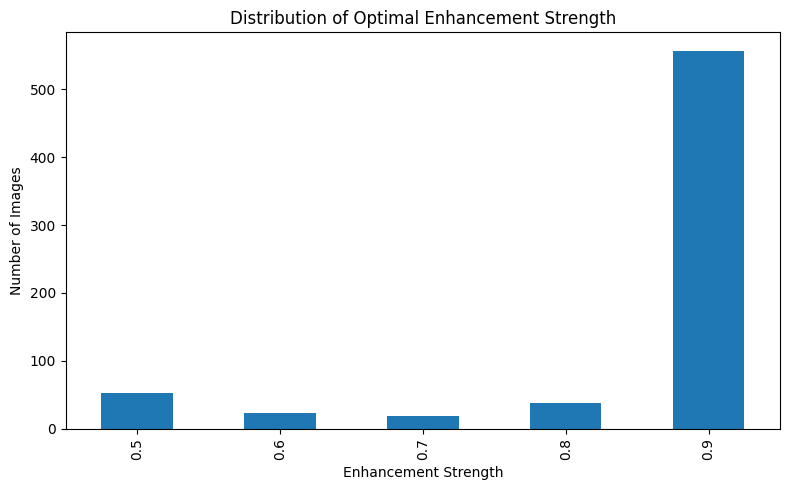

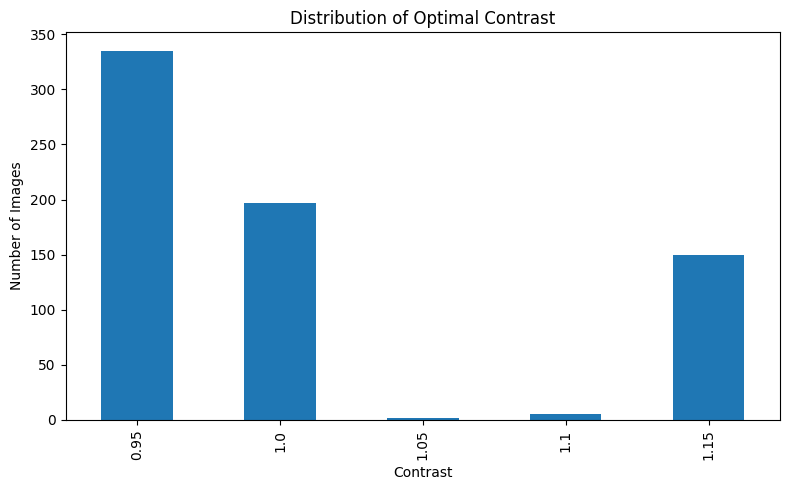

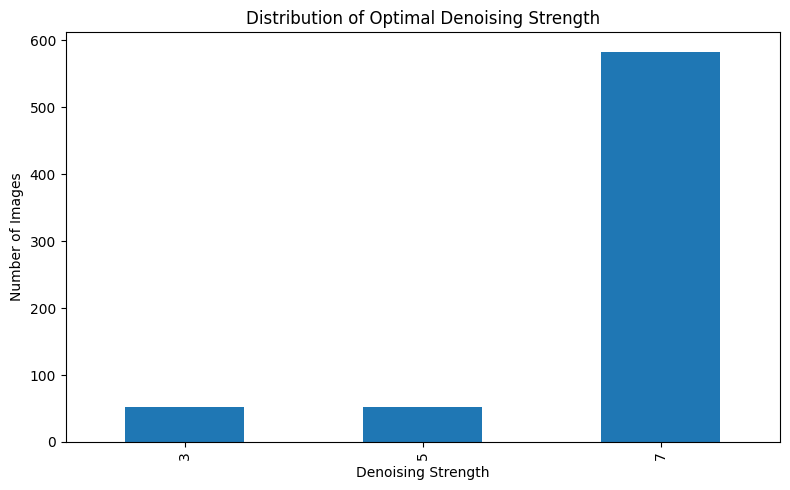

In [ ]:
# ============================================================
# PART 56 — Target Distribution Graphs
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Enhancement strength
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

pseudo_df["enhancement_strength"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Enhancement Strength")
plt.ylabel("Number of Images")
plt.title("Distribution of Optimal Enhancement Strength")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Contrast
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

pseudo_df["contrast"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Contrast")
plt.ylabel("Number of Images")
plt.title("Distribution of Optimal Contrast")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Denoising
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

pseudo_df["denoise_strength"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Denoising Strength")
plt.ylabel("Number of Images")
plt.title("Distribution of Optimal Denoising Strength")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# PART 57 — Majority-Class Baseline
# ============================================================

import pandas as pd
import numpy as np

pseudo_label_path = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/"
    "02_Features/lol_v2_pseudo_labels.csv"
)

pseudo_df = pd.read_csv(pseudo_label_path)

print("Total samples:", len(pseudo_df))

# ------------------------------------------------------------
# Majority labels
# ------------------------------------------------------------

majority_strength = (
    pseudo_df["enhancement_strength"]
    .mode()[0]
)

majority_contrast = (
    pseudo_df["contrast"]
    .mode()[0]
)

majority_denoise = (
    pseudo_df["denoise_strength"]
    .mode()[0]
)

print("\nMajority targets:")
print("Strength :", majority_strength)
print("Contrast :", majority_contrast)
print("Denoise  :", majority_denoise)

Total samples: 689

Majority targets:
Strength : 0.9
Contrast : 0.95
Denoise  : 7


In [ ]:
# ============================================================
# PART 58 — Majority Baseline Accuracy
# ============================================================

import numpy as np

# Majority-class baseline
strength_baseline_acc = (
    pseudo_df["enhancement_strength"]
    .value_counts(normalize=True)
    .max()
)

contrast_baseline_acc = (
    pseudo_df["contrast"]
    .value_counts(normalize=True)
    .max()
)

denoise_baseline_acc = (
    pseudo_df["denoise_strength"]
    .value_counts(normalize=True)
    .max()
)

print("Majority Baseline")
print("============================")

print(
    f"Strength accuracy : "
    f"{strength_baseline_acc:.4f} "
    f"({strength_baseline_acc*100:.2f}%)"
)

print(
    f"Contrast accuracy : "
    f"{contrast_baseline_acc:.4f} "
    f"({contrast_baseline_acc*100:.2f}%)"
)

print(
    f"Denoise accuracy  : "
    f"{denoise_baseline_acc:.4f} "
    f"({denoise_baseline_acc*100:.2f}%)"
)

Majority Baseline
Strength accuracy : 0.8070 (80.70%)
Contrast accuracy : 0.4862 (48.62%)
Denoise accuracy  : 0.8462 (84.62%)


In [ ]:
# ============================================================
# PART 59 — Convert Parameters to Classification Labels
# ============================================================

strength_classes = [0.5, 0.6, 0.7, 0.8, 0.9]
contrast_classes = [0.95, 1.00, 1.05, 1.10, 1.15]
denoise_classes = [3, 5, 7]

strength_to_class = {
    value: index
    for index, value in enumerate(strength_classes)
}

contrast_to_class = {
    value: index
    for index, value in enumerate(contrast_classes)
}

denoise_to_class = {
    value: index
    for index, value in enumerate(denoise_classes)
}

pseudo_df["strength_class"] = (
    pseudo_df["enhancement_strength"]
    .map(strength_to_class)
)

pseudo_df["contrast_class"] = (
    pseudo_df["contrast"]
    .map(contrast_to_class)
)

pseudo_df["denoise_class"] = (
    pseudo_df["denoise_strength"]
    .map(denoise_to_class)
)

print(
    pseudo_df[
        [
            "enhancement_strength",
            "strength_class",
            "contrast",
            "contrast_class",
            "denoise_strength",
            "denoise_class"
        ]
    ].head(10)
)

   enhancement_strength  strength_class  contrast  contrast_class  \
0                   0.9               4      0.95               0   
1                   0.9               4      0.95               0   
2                   0.9               4      0.95               0   
3                   0.9               4      1.00               1   
4                   0.9               4      1.00               1   
5                   0.9               4      1.00               1   
6                   0.9               4      1.00               1   
7                   0.9               4      0.95               0   
8                   0.9               4      0.95               0   
9                   0.9               4      1.00               1   

   denoise_strength  denoise_class  
0                 7              2  
1                 7              2  
2                 7              2  
3                 3              0  
4                 3              0  
5                 

In [ ]:
# ============================================================
# PART 60 — Prepare Input Features
# ============================================================

feature_columns = [
    "texture",
    "brightness",
    "entropy",
    "edge_density"
]

X = pseudo_df[
    feature_columns
].values.astype(np.float32)

y_strength = pseudo_df[
    "strength_class"
].values.astype(np.int64)

y_contrast = pseudo_df[
    "contrast_class"
].values.astype(np.int64)

y_denoise = pseudo_df[
    "denoise_class"
].values.astype(np.int64)

print("X:", X.shape)
print("Strength:", y_strength.shape)
print("Contrast:", y_contrast.shape)
print("Denoise:", y_denoise.shape)

X: (689, 4)
Strength: (689,)
Contrast: (689,)
Denoise: (689,)


In [ ]:
# ============================================================
# PART 61 — Stratified Train / Validation Split
# ============================================================

from sklearn.model_selection import train_test_split

# Combine target classes for stratification
combined_labels = (
    y_strength.astype(str)
    + "_"
    + y_contrast.astype(str)
    + "_"
    + y_denoise.astype(str)
)

# Check rare combinations
label_counts = pd.Series(
    combined_labels
).value_counts()

print("Number of target combinations:", len(label_counts))

print("\nCombination counts:")
display(label_counts.head(15))

Number of target combinations: 31

Combination counts:


,count
4_0_2,282
4_1_2,133
4_4_2,57
4_1_1,26
0_4_2,24
4_1_0,22
3_4_2,19
1_4_2,16
2_4_2,16
4_0_1,16


In [ ]:
X_train, X_val, ys_train, ys_val, yc_train, yc_val, yd_train, yd_val = train_test_split(
    X,
    y_strength,
    y_contrast,
    y_denoise,
    test_size=0.20,
    random_state=42,
    stratify=y_strength
)

print("Training:", len(X_train))
print("Validation:", len(X_val))

Training: 551
Validation: 138


In [ ]:
# ============================================================
# PART 62 — Normalize Features
# ============================================================

from sklearn.preprocessing import StandardScaler

feature_scaler = StandardScaler()

X_train_scaled = feature_scaler.fit_transform(
    X_train
).astype(np.float32)

X_val_scaled = feature_scaler.transform(
    X_val
).astype(np.float32)

print("Feature normalization completed.")

Feature normalization completed.


In [ ]:
# ============================================================
# PART 63 — Calculate Class Weights
# ============================================================

from sklearn.utils.class_weight import compute_class_weight

strength_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(strength_classes)),
    y=ys_train
)

contrast_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(contrast_classes)),
    y=yc_train
)

denoise_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(denoise_classes)),
    y=yd_train
)

print("Strength weights:")
print(strength_weights)

print("\nContrast weights:")
print(contrast_weights)

print("\nDenoise weights:")
print(denoise_weights)

Strength weights:
[2.62380952 5.8        7.34666667 3.67333333 0.24764045]

Contrast weights:
[  0.41119403   0.70641026 110.2         27.55         0.90327869]

Denoise weights:
[4.4796748  4.70940171 0.38995046]


In [ ]:
# ============================================================
# PART 64 — Multi-Head Adaptive Predictor
# ============================================================

import torch
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


class AdaptivePredictor(nn.Module):

    def __init__(self):
        super().__init__()

        # Shared feature representation
        self.backbone = nn.Sequential(

            nn.Linear(4, 32),
            nn.ReLU(),

            nn.Linear(32, 64),
            nn.ReLU(),

            nn.Dropout(0.10),

            nn.Linear(64, 32),
            nn.ReLU()
        )

        # Enhancement strength: 5 classes
        self.strength_head = nn.Linear(
            32,
            5
        )

        # Contrast: 5 classes
        self.contrast_head = nn.Linear(
            32,
            5
        )

        # Denoising: 3 classes
        self.denoise_head = nn.Linear(
            32,
            3
        )

    def forward(self, x):

        features = self.backbone(x)

        strength_logits = self.strength_head(
            features
        )

        contrast_logits = self.contrast_head(
            features
        )

        denoise_logits = self.denoise_head(
            features
        )

        return (
            strength_logits,
            contrast_logits,
            denoise_logits
        )


model = AdaptivePredictor().to(device)

print(model)

Device: cuda
AdaptivePredictor(
  (backbone): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.1, inplace=False)
    (5): Linear(in_features=64, out_features=32, bias=True)
    (6): ReLU()
  )
  (strength_head): Linear(in_features=32, out_features=5, bias=True)
  (contrast_head): Linear(in_features=32, out_features=5, bias=True)
  (denoise_head): Linear(in_features=32, out_features=3, bias=True)
)


In [ ]:
# ============================================================
# PART 65 — Create DataLoaders
# ============================================================

from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

ys_train_tensor = torch.tensor(
    ys_train,
    dtype=torch.long
)

yc_train_tensor = torch.tensor(
    yc_train,
    dtype=torch.long
)

yd_train_tensor = torch.tensor(
    yd_train,
    dtype=torch.long
)

ys_val_tensor = torch.tensor(
    ys_val,
    dtype=torch.long
)

yc_val_tensor = torch.tensor(
    yc_val,
    dtype=torch.long
)

yd_val_tensor = torch.tensor(
    yd_val,
    dtype=torch.long
)

train_dataset = TensorDataset(
    X_train_tensor,
    ys_train_tensor,
    yc_train_tensor,
    yd_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    ys_val_tensor,
    yc_val_tensor,
    yd_val_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 18
Validation batches: 5


In [ ]:
# ============================================================
# PART 66 — Weighted Loss Functions
# ============================================================

strength_weights_tensor = torch.tensor(
    strength_weights,
    dtype=torch.float32,
    device=device
)

contrast_weights_tensor = torch.tensor(
    contrast_weights,
    dtype=torch.float32,
    device=device
)

denoise_weights_tensor = torch.tensor(
    denoise_weights,
    dtype=torch.float32,
    device=device
)

strength_criterion = nn.CrossEntropyLoss(
    weight=strength_weights_tensor
)

contrast_criterion = nn.CrossEntropyLoss(
    weight=contrast_weights_tensor
)

denoise_criterion = nn.CrossEntropyLoss(
    weight=denoise_weights_tensor
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Weighted loss functions created.")

Weighted loss functions created.


## Train the adaptive predictor

In [ ]:
# ============================================================
# PART 67 — Train Adaptive Predictor
# ============================================================

import torch
import numpy as np

num_epochs = 150

train_losses = []

val_losses = []

train_strength_acc = []
train_contrast_acc = []
train_denoise_acc = []

val_strength_acc = []
val_contrast_acc = []
val_denoise_acc = []

best_val_loss = float("inf")

print("Starting training...")
print("=" * 60)

for epoch in range(num_epochs):

    # ========================================================
    # TRAINING
    # ========================================================

    model.train()

    running_loss = 0.0

    correct_strength = 0
    correct_contrast = 0
    correct_denoise = 0
    total_samples = 0

    for (
        batch_X,
        batch_strength,
        batch_contrast,
        batch_denoise
    ) in train_loader:

        batch_X = batch_X.to(device)
        batch_strength = batch_strength.to(device)
        batch_contrast = batch_contrast.to(device)
        batch_denoise = batch_denoise.to(device)

        optimizer.zero_grad()

        # Forward pass
        strength_logits, contrast_logits, denoise_logits = model(
            batch_X
        )

        # Individual losses
        loss_strength = strength_criterion(
            strength_logits,
            batch_strength
        )

        loss_contrast = contrast_criterion(
            contrast_logits,
            batch_contrast
        )

        loss_denoise = denoise_criterion(
            denoise_logits,
            batch_denoise
        )

        # Total loss
        loss = (
            loss_strength
            + loss_contrast
            + loss_denoise
        )

        # Backpropagation
        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * batch_X.size(0)
        )

        # Predictions
        pred_strength = torch.argmax(
            strength_logits,
            dim=1
        )

        pred_contrast = torch.argmax(
            contrast_logits,
            dim=1
        )

        pred_denoise = torch.argmax(
            denoise_logits,
            dim=1
        )

        correct_strength += (
            (pred_strength == batch_strength)
            .sum()
            .item()
        )

        correct_contrast += (
            (pred_contrast == batch_contrast)
            .sum()
            .item()
        )

        correct_denoise += (
            (pred_denoise == batch_denoise)
            .sum()
            .item()
        )

        total_samples += batch_X.size(0)

    epoch_train_loss = (
        running_loss / total_samples
    )

    epoch_train_strength_acc = (
        correct_strength / total_samples
    )

    epoch_train_contrast_acc = (
        correct_contrast / total_samples
    )

    epoch_train_denoise_acc = (
        correct_denoise / total_samples
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_running_loss = 0.0

    val_correct_strength = 0
    val_correct_contrast = 0
    val_correct_denoise = 0

    val_total = 0

    with torch.no_grad():

        for (
            batch_X,
            batch_strength,
            batch_contrast,
            batch_denoise
        ) in val_loader:

            batch_X = batch_X.to(device)
            batch_strength = batch_strength.to(device)
            batch_contrast = batch_contrast.to(device)
            batch_denoise = batch_denoise.to(device)

            strength_logits, contrast_logits, denoise_logits = model(
                batch_X
            )

            loss_strength = strength_criterion(
                strength_logits,
                batch_strength
            )

            loss_contrast = contrast_criterion(
                contrast_logits,
                batch_contrast
            )

            loss_denoise = denoise_criterion(
                denoise_logits,
                batch_denoise
            )

            loss = (
                loss_strength
                + loss_contrast
                + loss_denoise
            )

            val_running_loss += (
                loss.item() * batch_X.size(0)
            )

            pred_strength = torch.argmax(
                strength_logits,
                dim=1
            )

            pred_contrast = torch.argmax(
                contrast_logits,
                dim=1
            )

            pred_denoise = torch.argmax(
                denoise_logits,
                dim=1
            )

            val_correct_strength += (
                (pred_strength == batch_strength)
                .sum()
                .item()
            )

            val_correct_contrast += (
                (pred_contrast == batch_contrast)
                .sum()
                .item()
            )

            val_correct_denoise += (
                (pred_denoise == batch_denoise)
                .sum()
                .item()
            )

            val_total += batch_X.size(0)

    epoch_val_loss = (
        val_running_loss / val_total
    )

    epoch_val_strength_acc = (
        val_correct_strength / val_total
    )

    epoch_val_contrast_acc = (
        val_correct_contrast / val_total
    )

    epoch_val_denoise_acc = (
        val_correct_denoise / val_total
    )

    # ========================================================
    # SAVE HISTORY
    # ========================================================

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_strength_acc.append(
        epoch_train_strength_acc
    )

    train_contrast_acc.append(
        epoch_train_contrast_acc
    )

    train_denoise_acc.append(
        epoch_train_denoise_acc
    )

    val_strength_acc.append(
        epoch_val_strength_acc
    )

    val_contrast_acc.append(
        epoch_val_contrast_acc
    )

    val_denoise_acc.append(
        epoch_val_denoise_acc
    )

    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "scaler": feature_scaler,
                "strength_classes": strength_classes,
                "contrast_classes": contrast_classes,
                "denoise_classes": denoise_classes,
                "best_val_loss": best_val_loss
            },
            "/content/gdrive/MyDrive/"
            "Adaptive_LowLight_Research/"
            "03_Models/"
            "Adaptive_Predictor/"
            "best_adaptive_predictor.pth"
        )

    # ========================================================
    # PRINT PROGRESS
    # ========================================================

    if (
        epoch == 0
        or (epoch + 1) % 10 == 0
    ):

        print(
            f"Epoch [{epoch+1:03d}/{num_epochs}] | "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f} | "
            f"Val S: {epoch_val_strength_acc:.3f} | "
            f"Val C: {epoch_val_contrast_acc:.3f} | "
            f"Val D: {epoch_val_denoise_acc:.3f}"
        )

print("=" * 60)
print("TRAINING COMPLETED")
print(f"Best validation loss: {best_val_loss:.4f}")

Starting training...
Epoch [001/150] | Train Loss: 4.2873 | Val Loss: 4.2757 | Val S: 0.804 | Val C: 0.413 | Val D: 0.514
Epoch [010/150] | Train Loss: 2.8929 | Val Loss: 3.3552 | Val S: 0.812 | Val C: 0.551 | Val D: 0.630
Epoch [020/150] | Train Loss: 2.6608 | Val Loss: 3.2469 | Val S: 0.812 | Val C: 0.616 | Val D: 0.652
Epoch [030/150] | Train Loss: 2.4931 | Val Loss: 3.3329 | Val S: 0.797 | Val C: 0.638 | Val D: 0.674
Epoch [040/150] | Train Loss: 2.3766 | Val Loss: 3.3556 | Val S: 0.797 | Val C: 0.623 | Val D: 0.667
Epoch [050/150] | Train Loss: 2.3081 | Val Loss: 3.3763 | Val S: 0.797 | Val C: 0.681 | Val D: 0.638
Epoch [060/150] | Train Loss: 2.1998 | Val Loss: 3.5272 | Val S: 0.797 | Val C: 0.688 | Val D: 0.659
Epoch [070/150] | Train Loss: 2.1553 | Val Loss: 3.5750 | Val S: 0.775 | Val C: 0.717 | Val D: 0.659
Epoch [080/150] | Train Loss: 2.0938 | Val Loss: 3.6168 | Val S: 0.790 | Val C: 0.710 | Val D: 0.696
Epoch [090/150] | Train Loss: 2.0725 | Val Loss: 3.7361 | Val S: 0.804

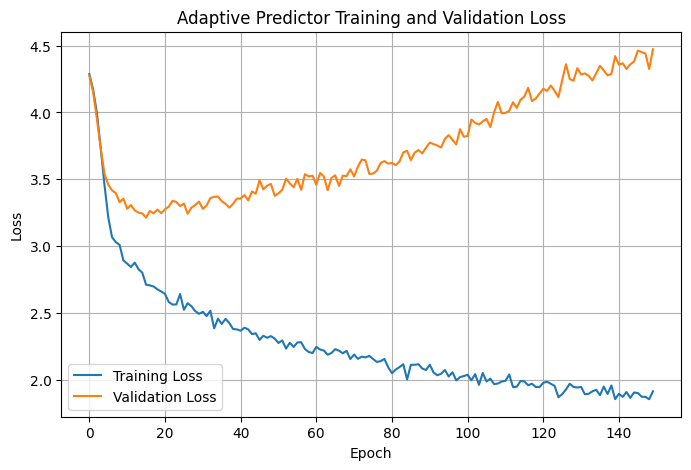

In [ ]:
# ============================================================
# PART 68 — Loss Curve
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Adaptive Predictor Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

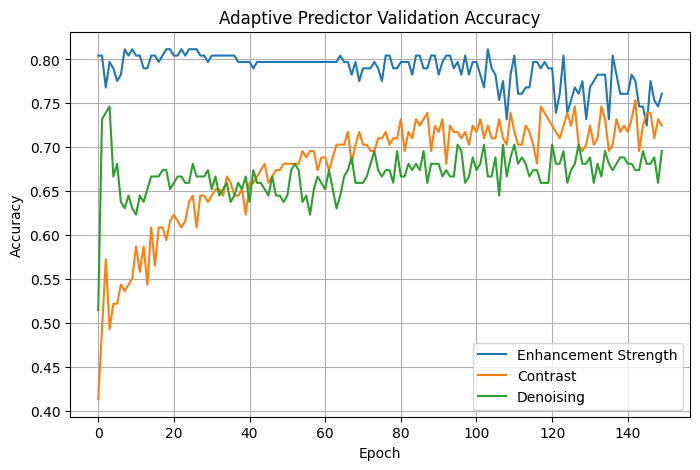

In [ ]:
# ============================================================
# PART 69 — Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    val_strength_acc,
    label="Enhancement Strength"
)

plt.plot(
    val_contrast_acc,
    label="Contrast"
)

plt.plot(
    val_denoise_acc,
    label="Denoising"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Adaptive Predictor Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# PART 70 — Load Best Adaptive Predictor
# ============================================================

checkpoint_path = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/"
    "03_Models/"
    "Adaptive_Predictor/"
    "best_adaptive_predictor.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best checkpoint loaded successfully.")
print(
    f"Best validation loss: "
    f"{checkpoint['best_val_loss']:.4f}"
)

Best checkpoint loaded successfully.
Best validation loss: 3.2131


In [ ]:
# ============================================================
# PART 71 — Generate Validation Predictions
# ============================================================

all_true_strength = []
all_pred_strength = []

all_true_contrast = []
all_pred_contrast = []

all_true_denoise = []
all_pred_denoise = []

with torch.no_grad():

    for (
        batch_X,
        batch_strength,
        batch_contrast,
        batch_denoise
    ) in val_loader:

        batch_X = batch_X.to(device)

        strength_logits, contrast_logits, denoise_logits = model(
            batch_X
        )

        pred_strength = torch.argmax(
            strength_logits,
            dim=1
        ).cpu().numpy()

        pred_contrast = torch.argmax(
            contrast_logits,
            dim=1
        ).cpu().numpy()

        pred_denoise = torch.argmax(
            denoise_logits,
            dim=1
        ).cpu().numpy()

        all_true_strength.extend(
            batch_strength.numpy()
        )

        all_pred_strength.extend(
            pred_strength
        )

        all_true_contrast.extend(
            batch_contrast.numpy()
        )

        all_pred_contrast.extend(
            pred_contrast
        )

        all_true_denoise.extend(
            batch_denoise.numpy()
        )

        all_pred_denoise.extend(
            pred_denoise
        )

print("Validation predictions generated.")

Validation predictions generated.


In [ ]:
# ============================================================
# PART 72 — Classification Report
# ============================================================

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score
)

print("=" * 70)
print("ENHANCEMENT STRENGTH")
print("=" * 70)

print(
    classification_report(
        all_true_strength,
        all_pred_strength,
        labels=np.arange(len(strength_classes)),
        target_names=[
            str(x) for x in strength_classes
        ],
        zero_division=0
    )
)

print("=" * 70)
print("CONTRAST")
print("=" * 70)

print(
    classification_report(
        all_true_contrast,
        all_pred_contrast,
        labels=np.arange(len(contrast_classes)),
        target_names=[
            str(x) for x in contrast_classes
        ],
        zero_division=0
    )
)

print("=" * 70)
print("DENOISING")
print("=" * 70)

print(
    classification_report(
        all_true_denoise,
        all_pred_denoise,
        labels=np.arange(len(denoise_classes)),
        target_names=[
            str(x) for x in denoise_classes
        ],
        zero_division=0
    )
)

ENHANCEMENT STRENGTH
              precision    recall  f1-score   support

         0.5       0.50      0.73      0.59        11
         0.6       0.20      0.50      0.29         4
         0.7       0.00      0.00      0.00         4
         0.8       0.17      0.25      0.20         8
         0.9       0.99      0.89      0.94       111

    accuracy                           0.80       138
   macro avg       0.37      0.47      0.40       138
weighted avg       0.85      0.80      0.82       138

CONTRAST
              precision    recall  f1-score   support

        0.95       0.63      0.64      0.64        67
         1.0       0.44      0.34      0.38        41
        1.05       0.00      0.00      0.00         1
         1.1       0.00      0.00      0.00         1
        1.15       0.64      0.75      0.69        28

    accuracy                           0.57       138
   macro avg       0.34      0.35      0.34       138
weighted avg       0.57      0.57      0.56    

In [ ]:
# ============================================================
# PART 73 — Accuracy and Macro-F1
# ============================================================

results = {
    "Strength": {
        "Accuracy": accuracy_score(
            all_true_strength,
            all_pred_strength
        ),
        "Macro-F1": f1_score(
            all_true_strength,
            all_pred_strength,
            average="macro",
            zero_division=0
        ),
        "Majority Baseline": strength_baseline_acc
    },

    "Contrast": {
        "Accuracy": accuracy_score(
            all_true_contrast,
            all_pred_contrast
        ),
        "Macro-F1": f1_score(
            all_true_contrast,
            all_pred_contrast,
            average="macro",
            zero_division=0
        ),
        "Majority Baseline": contrast_baseline_acc
    },

    "Denoise": {
        "Accuracy": accuracy_score(
            all_true_denoise,
            all_pred_denoise
        ),
        "Macro-F1": f1_score(
            all_true_denoise,
            all_pred_denoise,
            average="macro",
            zero_division=0
        ),
        "Majority Baseline": denoise_baseline_acc
    }
}

results_df = pd.DataFrame(results).T

print(results_df.round(4))

          Accuracy  Macro-F1  Majority Baseline
Strength    0.8043    0.4033             0.8070
Contrast    0.5652    0.3418             0.4862
Denoise     0.6667    0.5659             0.8462


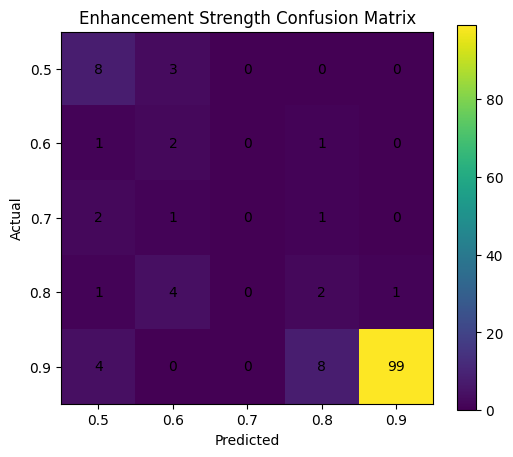

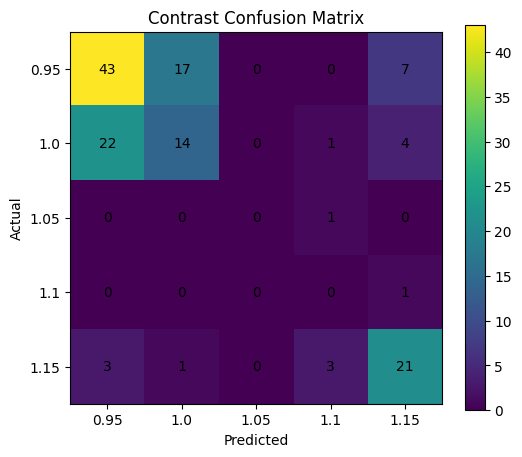

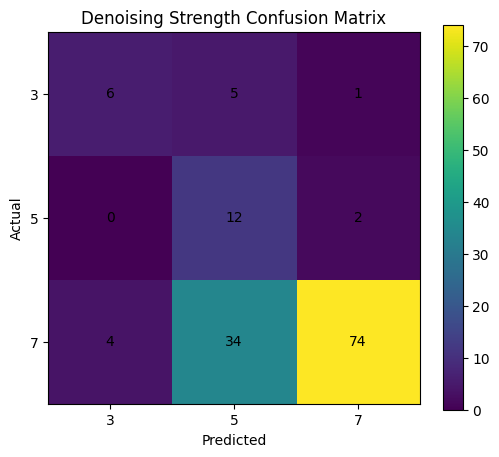

In [ ]:
# ============================================================
# PART 74 — Confusion Matrices
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Strength
# ------------------------------------------------------------

cm_strength = confusion_matrix(
    all_true_strength,
    all_pred_strength,
    labels=np.arange(len(strength_classes))
)

plt.figure(figsize=(6, 5))

plt.imshow(cm_strength)

plt.xticks(
    range(len(strength_classes)),
    strength_classes
)

plt.yticks(
    range(len(strength_classes)),
    strength_classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Enhancement Strength Confusion Matrix")

for i in range(cm_strength.shape[0]):
    for j in range(cm_strength.shape[1]):
        plt.text(
            j,
            i,
            cm_strength[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()


# ------------------------------------------------------------
# Contrast
# ------------------------------------------------------------

cm_contrast = confusion_matrix(
    all_true_contrast,
    all_pred_contrast,
    labels=np.arange(len(contrast_classes))
)

plt.figure(figsize=(6, 5))

plt.imshow(cm_contrast)

plt.xticks(
    range(len(contrast_classes)),
    contrast_classes
)

plt.yticks(
    range(len(contrast_classes)),
    contrast_classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Contrast Confusion Matrix")

for i in range(cm_contrast.shape[0]):
    for j in range(cm_contrast.shape[1]):
        plt.text(
            j,
            i,
            cm_contrast[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()


# ------------------------------------------------------------
# Denoise
# ------------------------------------------------------------

cm_denoise = confusion_matrix(
    all_true_denoise,
    all_pred_denoise,
    labels=np.arange(len(denoise_classes))
)

plt.figure(figsize=(6, 5))

plt.imshow(cm_denoise)

plt.xticks(
    range(len(denoise_classes)),
    denoise_classes
)

plt.yticks(
    range(len(denoise_classes)),
    denoise_classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Denoising Strength Confusion Matrix")

for i in range(cm_denoise.shape[0]):
    for j in range(cm_denoise.shape[1]):
        plt.text(
            j,
            i,
            cm_denoise[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

In [ ]:
# ============================================================
# PART 75 — Predicted Parameter Distribution
# ============================================================

print("=" * 60)
print("PREDICTED STRENGTH DISTRIBUTION")
print("=" * 60)

pred_strength_values = [
    strength_classes[i]
    for i in all_pred_strength
]

print(
    pd.Series(pred_strength_values)
    .value_counts()
    .sort_index()
)

print("\n" + "=" * 60)
print("PREDICTED CONTRAST DISTRIBUTION")
print("=" * 60)

pred_contrast_values = [
    contrast_classes[i]
    for i in all_pred_contrast
]

print(
    pd.Series(pred_contrast_values)
    .value_counts()
    .sort_index()
)

print("\n" + "=" * 60)
print("PREDICTED DENOISE DISTRIBUTION")
print("=" * 60)

pred_denoise_values = [
    denoise_classes[i]
    for i in all_pred_denoise
]

print(
    pd.Series(pred_denoise_values)
    .value_counts()
    .sort_index()
)

PREDICTED STRENGTH DISTRIBUTION
0.5     16
0.6     10
0.8     12
0.9    100
Name: count, dtype: int64

PREDICTED CONTRAST DISTRIBUTION
0.95    68
1.00    32
1.10     5
1.15    33
Name: count, dtype: int64

PREDICTED DENOISE DISTRIBUTION
3    10
5    51
7    77
Name: count, dtype: int64


In [ ]:
# ============================================================
# PART 78 — Regression Adaptive Predictor
# ============================================================

import torch
import torch.nn as nn

class AdaptiveRegressionPredictor(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),

            nn.Linear(32, 64),
            nn.ReLU(),

            nn.Dropout(0.10),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 3)
        )

    def forward(self, x):
        return self.network(x)


reg_model = AdaptiveRegressionPredictor().to(device)

print(reg_model)

AdaptiveRegressionPredictor(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.1, inplace=False)
    (5): Linear(in_features=64, out_features=32, bias=True)
    (6): ReLU()
    (7): Linear(in_features=32, out_features=3, bias=True)
  )
)


In [ ]:
# ============================================================
# PART 79 — Regression Targets
# ============================================================

# Use the original numerical parameter values

yr_strength = pseudo_df[
    "enhancement_strength"
].values.astype(np.float32)

yr_contrast = pseudo_df[
    "contrast"
].values.astype(np.float32)

yr_denoise = pseudo_df[
    "denoise_strength"
].values.astype(np.float32)

# Same train/validation indices using the same random state
indices = np.arange(len(pseudo_df))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=pseudo_df["enhancement_strength"]
)

Xr_train = X[train_idx]
Xr_val = X[val_idx]

Yr_train = np.column_stack([
    yr_strength[train_idx],
    yr_contrast[train_idx],
    yr_denoise[train_idx]
])

Yr_val = np.column_stack([
    yr_strength[val_idx],
    yr_contrast[val_idx],
    yr_denoise[val_idx]
])

# Normalize input features
reg_scaler = StandardScaler()

Xr_train_scaled = reg_scaler.fit_transform(
    Xr_train
).astype(np.float32)

Xr_val_scaled = reg_scaler.transform(
    Xr_val
).astype(np.float32)

print("Training:", Xr_train_scaled.shape)
print("Validation:", Xr_val_scaled.shape)
print("Targets:", Yr_train.shape)

Training: (551, 4)
Validation: (138, 4)
Targets: (551, 3)


In [ ]:
# ============================================================
# PART 80 — Normalize Regression Targets
# ============================================================

target_scaler = StandardScaler()

Yr_train_scaled = target_scaler.fit_transform(
    Yr_train
).astype(np.float32)

Yr_val_scaled = target_scaler.transform(
    Yr_val
).astype(np.float32)

print("Target normalization completed.")

Target normalization completed.


In [ ]:
# ============================================================
# PART 81 — Regression DataLoader
# ============================================================

from torch.utils.data import TensorDataset, DataLoader

Xr_train_tensor = torch.tensor(
    Xr_train_scaled,
    dtype=torch.float32
)

Yr_train_tensor = torch.tensor(
    Yr_train_scaled,
    dtype=torch.float32
)

Xr_val_tensor = torch.tensor(
    Xr_val_scaled,
    dtype=torch.float32
)

Yr_val_tensor = torch.tensor(
    Yr_val_scaled,
    dtype=torch.float32
)

reg_train_dataset = TensorDataset(
    Xr_train_tensor,
    Yr_train_tensor
)

reg_val_dataset = TensorDataset(
    Xr_val_tensor,
    Yr_val_tensor
)

reg_train_loader = DataLoader(
    reg_train_dataset,
    batch_size=32,
    shuffle=True
)

reg_val_loader = DataLoader(
    reg_val_dataset,
    batch_size=32,
    shuffle=False
)

print("Regression DataLoaders ready.")

Regression DataLoaders ready.


In [ ]:
# ============================================================
# PART 82 — Train Regression Predictor
# ============================================================

reg_criterion = nn.MSELoss()

reg_optimizer = torch.optim.Adam(
    reg_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

reg_epochs = 100

reg_train_losses = []
reg_val_losses = []

best_reg_val_loss = float("inf")

print("Starting regression training...")
print("=" * 60)

for epoch in range(reg_epochs):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    reg_model.train()

    train_loss = 0.0
    train_count = 0

    for batch_X, batch_y in reg_train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        reg_optimizer.zero_grad()

        predictions = reg_model(batch_X)

        loss = reg_criterion(
            predictions,
            batch_y
        )

        loss.backward()

        reg_optimizer.step()

        train_loss += (
            loss.item() * batch_X.size(0)
        )

        train_count += batch_X.size(0)

    train_loss /= train_count

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    reg_model.eval()

    val_loss = 0.0
    val_count = 0

    with torch.no_grad():

        for batch_X, batch_y in reg_val_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = reg_model(batch_X)

            loss = reg_criterion(
                predictions,
                batch_y
            )

            val_loss += (
                loss.item() * batch_X.size(0)
            )

            val_count += batch_X.size(0)

    val_loss /= val_count

    reg_train_losses.append(train_loss)
    reg_val_losses.append(val_loss)

    # --------------------------------------------------------
    # SAVE BEST
    # --------------------------------------------------------

    if val_loss < best_reg_val_loss:

        best_reg_val_loss = val_loss

        torch.save(
            {
                "model_state_dict": reg_model.state_dict(),
                "feature_scaler": reg_scaler,
                "target_scaler": target_scaler,
                "best_val_loss": best_reg_val_loss
            },
            "/content/gdrive/MyDrive/"
            "Adaptive_LowLight_Research/"
            "03_Models/"
            "Adaptive_Predictor/"
            "best_regression_predictor.pth"
        )

    if (
        epoch == 0
        or (epoch + 1) % 10 == 0
    ):

        print(
            f"Epoch [{epoch+1:03d}/{reg_epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

print("=" * 60)
print("REGRESSION TRAINING COMPLETED")
print(
    f"Best validation loss: "
    f"{best_reg_val_loss:.4f}"
)

Starting regression training...
Epoch [001/100] | Train Loss: 0.9838 | Val Loss: 0.9589
Epoch [010/100] | Train Loss: 0.5873 | Val Loss: 0.5525
Epoch [020/100] | Train Loss: 0.5196 | Val Loss: 0.4940
Epoch [030/100] | Train Loss: 0.4786 | Val Loss: 0.4508
Epoch [040/100] | Train Loss: 0.4438 | Val Loss: 0.4314
Epoch [050/100] | Train Loss: 0.4198 | Val Loss: 0.4134
Epoch [060/100] | Train Loss: 0.4013 | Val Loss: 0.4137
Epoch [070/100] | Train Loss: 0.3717 | Val Loss: 0.3991
Epoch [080/100] | Train Loss: 0.3573 | Val Loss: 0.3970
Epoch [090/100] | Train Loss: 0.3513 | Val Loss: 0.3973
Epoch [100/100] | Train Loss: 0.3414 | Val Loss: 0.4017
REGRESSION TRAINING COMPLETED
Best validation loss: 0.3944


In [ ]:
# ============================================================
# PART 83 — Load Best Regression Model
# ============================================================

reg_checkpoint_path = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/"
    "03_Models/"
    "Adaptive_Predictor/"
    "best_regression_predictor.pth"
)

reg_checkpoint = torch.load(
    reg_checkpoint_path,
    map_location=device,
    weights_only=False
)

reg_model.load_state_dict(
    reg_checkpoint["model_state_dict"]
)

reg_scaler = reg_checkpoint["feature_scaler"]
target_scaler = reg_checkpoint["target_scaler"]

reg_model.eval()

print("Best regression checkpoint loaded.")
print(
    f"Best validation loss: "
    f"{reg_checkpoint['best_val_loss']:.4f}"
)

Best regression checkpoint loaded.
Best validation loss: 0.3944


In [ ]:
# ============================================================
# PART 84 — Generate Regression Predictions
# ============================================================

reg_predictions_scaled = []

with torch.no_grad():

    for batch_X, batch_y in reg_val_loader:

        batch_X = batch_X.to(device)

        predictions = reg_model(batch_X)

        reg_predictions_scaled.append(
            predictions.cpu().numpy()
        )

reg_predictions_scaled = np.concatenate(
    reg_predictions_scaled,
    axis=0
)

# Convert back to original parameter units
reg_predictions = target_scaler.inverse_transform(
    reg_predictions_scaled
)

print("Predictions generated.")
print("Shape:", reg_predictions.shape)

print("\nFirst 10 predictions:")
print(reg_predictions[:10])

Predictions generated.
Shape: (138, 3)

First 10 predictions:
[[0.9004751  0.9718115  7.0027146 ]
 [0.8979641  0.9672471  7.0301824 ]
 [0.8972792  0.95568204 6.693491  ]
 [0.89968556 0.9569525  6.2733703 ]
 [0.8999089  0.96831906 7.011495  ]
 [0.8916063  1.0071036  4.937188  ]
 [0.89796424 0.9715891  6.6870637 ]
 [0.9031187  1.0187303  4.741614  ]
 [0.8940798  0.97283936 6.9300284 ]
 [0.8984959  0.9652432  6.4450965 ]]


In [ ]:
# ============================================================
# PART 85 — Regression Evaluation
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Ground truth in original units
reg_true = Yr_val

parameter_names = [
    "Enhancement Strength",
    "Contrast",
    "Denoise Strength"
]

for i, name in enumerate(parameter_names):

    mae = mean_absolute_error(
        reg_true[:, i],
        reg_predictions[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            reg_true[:, i],
            reg_predictions[:, i]
        )
    )

    print(f"\n{name}")
    print("-" * 40)
    print(f"MAE  : {mae:.6f}")
    print(f"RMSE : {rmse:.6f}")


Enhancement Strength
----------------------------------------
MAE  : 0.032825
RMSE : 0.068566

Contrast
----------------------------------------
MAE  : 0.026230
RMSE : 0.039529

Denoise Strength
----------------------------------------
MAE  : 0.462305
RMSE : 0.877080


In [ ]:
# ============================================================
# PART 86 — Prediction Range
# ============================================================

for i, name in enumerate(parameter_names):

    print(f"\n{name}")

    print(
        "True range      :",
        reg_true[:, i].min(),
        "to",
        reg_true[:, i].max()
    )

    print(
        "Predicted range :",
        reg_predictions[:, i].min(),
        "to",
        reg_predictions[:, i].max()
    )


Enhancement Strength
True range      : 0.5 to 0.9
Predicted range : 0.57022965 to 0.9067952

Contrast
True range      : 0.95 to 1.15
Predicted range : 0.9459327 to 1.1794993

Denoise Strength
True range      : 3.0 to 7.0
Predicted range : 2.7054687 to 7.130071


In [ ]:
# ============================================================
# PART 87 — Convert Predictions to Candidate Parameters
# ============================================================

def nearest_value(value, candidates):
    candidates = np.array(candidates)
    index = np.argmin(
        np.abs(candidates - value)
    )
    return candidates[index]


pred_strength_final = np.array([
    nearest_value(
        x,
        strength_classes
    )
    for x in reg_predictions[:, 0]
])

pred_contrast_final = np.array([
    nearest_value(
        x,
        contrast_classes
    )
    for x in reg_predictions[:, 1]
])

pred_denoise_final = np.array([
    nearest_value(
        x,
        denoise_classes
    )
    for x in reg_predictions[:, 2]
])

print("Final mapped predictions:")

print("\nStrength:")
print(
    pd.Series(
        pred_strength_final
    ).value_counts().sort_index()
)

print("\nContrast:")
print(
    pd.Series(
        pred_contrast_final
    ).value_counts().sort_index()
)

print("\nDenoise:")
print(
    pd.Series(
        pred_denoise_final
    ).value_counts().sort_index()
)

Final mapped predictions:

Strength:
0.6     13
0.7     11
0.8      3
0.9    111
Name: count, dtype: int64

Contrast:
0.95    67
1.00    38
1.05     7
1.10     7
1.15    19
Name: count, dtype: int64

Denoise:
3      5
5     15
7    118
Name: count, dtype: int64


In [ ]:
# ============================================================
# PART 88 — Continuous Prediction Statistics
# ============================================================

prediction_df = pd.DataFrame(
    reg_predictions,
    columns=[
        "pred_strength",
        "pred_contrast",
        "pred_denoise"
    ]
)

print(
    prediction_df.describe().round(4)
)

       pred_strength  pred_contrast  pred_denoise
count       138.0000       138.0000      138.0000
mean          0.8513         1.0084        6.4829
std           0.0962         0.0666        0.8706
min           0.5702         0.9459        2.7055
25%           0.8804         0.9646        6.4913
50%           0.8964         0.9760        6.7878
75%           0.8996         1.0174        6.9641
max           0.9068         1.1795        7.1301


In [ ]:
print("\nUnique continuous predictions:")

print(
    "Strength:",
    prediction_df["pred_strength"].nunique()
)

print(
    "Contrast:",
    prediction_df["pred_contrast"].nunique()
)

print(
    "Denoise:",
    prediction_df["pred_denoise"].nunique()
)


Unique continuous predictions:
Strength: 138
Contrast: 138
Denoise: 138


In [ ]:
# ============================================================
# PART 89 — Final Adaptive Parameter Predictor
# ============================================================

def predict_adaptive_parameters(image):

    # --------------------------------------------------------
    # 1. Extract image features
    # --------------------------------------------------------

    features = extract_features(image)

    feature_vector = np.array([
        features["texture"],
        features["brightness"],
        features["entropy"],
        features["edge_density"]
    ], dtype=np.float32).reshape(1, -1)

    # --------------------------------------------------------
    # 2. Normalize features
    # --------------------------------------------------------

    feature_vector_scaled = reg_scaler.transform(
        feature_vector
    ).astype(np.float32)

    feature_tensor = torch.tensor(
        feature_vector_scaled,
        dtype=torch.float32
    ).to(device)

    # --------------------------------------------------------
    # 3. Predict parameters
    # --------------------------------------------------------

    reg_model.eval()

    with torch.no_grad():

        prediction_scaled = reg_model(
            feature_tensor
        ).cpu().numpy()

    prediction = target_scaler.inverse_transform(
        prediction_scaled
    )[0]

    # --------------------------------------------------------
    # 4. Map to valid candidate parameters
    # --------------------------------------------------------

    strength = nearest_value(
        prediction[0],
        strength_classes
    )

    contrast = nearest_value(
        prediction[1],
        contrast_classes
    )

    denoise = nearest_value(
        prediction[2],
        denoise_classes
    )

    return {
        "enhancement_strength": float(strength),
        "contrast": float(contrast),
        "denoise_strength": int(denoise),

        # Keep continuous predictions for analysis
        "predicted_strength_continuous": float(
            prediction[0]
        ),

        "predicted_contrast_continuous": float(
            prediction[1]
        ),

        "predicted_denoise_continuous": float(
            prediction[2]
        ),

        # Features
        "texture": float(features["texture"]),
        "brightness": float(features["brightness"]),
        "entropy": float(features["entropy"]),
        "edge_density": float(features["edge_density"])
    }

In [ ]:
# ============================================================
# PART 90 — Load One LOL-v2 Test Image
# ============================================================

import os
import glob
import cv2
import numpy as np

lol_test_low_dir = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/"
    "01_Datasets/"
    "LOL_v2/"
    "Real_captured/"
    "Test/"
    "Low"
)

# Find test images
test_image_files = sorted(
    glob.glob(
        os.path.join(
            lol_test_low_dir,
            "*"
        )
    )
)

print(
    "Found test images:",
    len(test_image_files)
)

if len(test_image_files) == 0:
    raise FileNotFoundError(
        f"No images found in:\n{lol_test_low_dir}"
    )

test_low_path = test_image_files[0]

print(
    "Testing image:",
    test_low_path
)

# Read image
test_image = cv2.imread(
    test_low_path
)

if test_image is None:
    raise ValueError(
        f"Could not read image:\n{test_low_path}"
    )

# OpenCV BGR → RGB
test_image = cv2.cvtColor(
    test_image,
    cv2.COLOR_BGR2RGB
)

print(
    "Image shape:",
    test_image.shape
)

print(
    "Image dtype:",
    test_image.dtype
)

Found test images: 100
Testing image: /content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/LOL_v2/Real_captured/Test/Low/low00690.png
Image shape: (400, 600, 3)
Image dtype: uint8


In [ ]:
# ============================================================
# PART 91 — Predict Adaptive Parameters
# ============================================================

adaptive_params = predict_adaptive_parameters(
    test_image
)

print("Adaptive Prediction")
print("=" * 50)

for key, value in adaptive_params.items():
    print(
        f"{key}: {value}"
    )

Adaptive Prediction
enhancement_strength: 0.9
contrast: 0.95
denoise_strength: 7
predicted_strength_continuous: 0.8970316648483276
predicted_contrast_continuous: 0.967587947845459
predicted_denoise_continuous: 6.816805839538574
texture: 0.4648483130763629
brightness: 0.057771944444444445
entropy: 4.948081136347105
edge_density: 0.2184125


In [ ]:
# ============================================================
# PART 92 — Define Complete Adaptive Zero-DCE++ Pipeline
# ============================================================

def adaptive_zero_dce_pipeline(image):

    # --------------------------------------------------------
    # Step 1 — Predict adaptive parameters
    # --------------------------------------------------------

    params = predict_adaptive_parameters(image)

    # --------------------------------------------------------
    # Step 2 — Run Zero-DCE++
    # --------------------------------------------------------

    zerodce_output, zerodce_tensor, inference_time = (
        run_zerodce(image)
    )

    # --------------------------------------------------------
    # Step 3 — Apply adaptive post-processing
    # --------------------------------------------------------

    enhanced = adaptive_process_with_params(
        original=image,
        zerodce_output=zerodce_output,
        enhancement_strength=params[
            "enhancement_strength"
        ],
        contrast=params[
            "contrast"
        ],
        denoise_strength=params[
            "denoise_strength"
        ]
    )

    return (
        enhanced,
        params,
        inference_time
    )


print("Adaptive Zero-DCE++ pipeline defined successfully.")

Adaptive Zero-DCE++ pipeline defined successfully.


In [ ]:
# ============================================================
# PART 93 — Run Complete Adaptive Pipeline
# ============================================================

adaptive_output, params, inference_time = (
    adaptive_zero_dce_pipeline(
        test_image
    )
)

print("Adaptive pipeline completed successfully.")

print("\nSelected Parameters")
print("=" * 40)

print(
    f"Strength : "
    f"{params['enhancement_strength']}"
)

print(
    f"Contrast : "
    f"{params['contrast']}"
)

print(
    f"Denoise  : "
    f"{params['denoise_strength']}"
)

print(
    f"\nContinuous Strength : "
    f"{params['predicted_strength_continuous']:.4f}"
)

print(
    f"Continuous Contrast : "
    f"{params['predicted_contrast_continuous']:.4f}"
)

print(
    f"Continuous Denoise  : "
    f"{params['predicted_denoise_continuous']:.4f}"
)

print(
    f"\nZero-DCE++ inference time: "
    f"{inference_time:.4f} sec"
)

print(
    "Input shape :",
    test_image.shape
)

print(
    "Output shape:",
    adaptive_output.shape
)

Adaptive pipeline completed successfully.

Selected Parameters
Strength : 0.9
Contrast : 0.95
Denoise  : 7

Continuous Strength : 0.8970
Continuous Contrast : 0.9676
Continuous Denoise  : 6.8168

Zero-DCE++ inference time: 0.0120 sec
Input shape : (400, 600, 3)
Output shape: (396, 600, 3)


In [ ]:
# ============================================================
# PART 94 — Prepare LOL-v2 Test Pairs
# ============================================================

import os
import glob
import cv2
import numpy as np
import pandas as pd

lol_test_low_dir = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/"
    "01_Datasets/"
    "LOL_v2/"
    "Real_captured/"
    "Test/"
    "Low"
)

lol_test_normal_dir = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/"
    "01_Datasets/"
    "LOL_v2/"
    "Real_captured/"
    "Test/"
    "Normal"
)

low_files = sorted(
    glob.glob(
        os.path.join(
            lol_test_low_dir,
            "*"
        )
    )
)

normal_files = sorted(
    glob.glob(
        os.path.join(
            lol_test_normal_dir,
            "*"
        )
    )
)

print("Low-light images :", len(low_files))
print("Normal images    :", len(normal_files))

Low-light images : 100
Normal images    : 100


In [ ]:
# ============================================================
# PART 95 — Inspect LOL-v2 Test Filenames
# ============================================================

import os
import glob

low_files = sorted(
    glob.glob(
        os.path.join(
            lol_test_low_dir,
            "*"
        )
    )
)

normal_files = sorted(
    glob.glob(
        os.path.join(
            lol_test_normal_dir,
            "*"
        )
    )
)

print("Low images:", len(low_files))
print("Normal images:", len(normal_files))

print("\n--- LOW filenames ---")

for path in low_files[:10]:
    print(os.path.basename(path))

print("\n--- NORMAL filenames ---")

for path in normal_files[:10]:
    print(os.path.basename(path))

Low images: 100
Normal images: 100

--- LOW filenames ---
low00690.png
low00691.png
low00692.png
low00693.png
low00694.png
low00695.png
low00696.png
low00697.png
low00698.png
low00699.png

--- NORMAL filenames ---
normal00690.png
normal00691.png
normal00692.png
normal00693.png
normal00694.png
normal00695.png
normal00696.png
normal00697.png
normal00698.png
normal00699.png


In [ ]:
# ============================================================
# PART 95 — Correct LOL-v2 Test Pair Matching
# ============================================================

import os
import glob

low_files = sorted(
    glob.glob(
        os.path.join(
            lol_test_low_dir,
            "*.png"
        )
    )
)

normal_files = sorted(
    glob.glob(
        os.path.join(
            lol_test_normal_dir,
            "*.png"
        )
    )
)

# Create dictionaries using the numeric ID
low_dict = {}

for path in low_files:

    filename = os.path.basename(path)

    # low00690.png -> 00690
    image_id = filename.replace(
        "low",
        "",
        1
    ).replace(
        ".png",
        ""
    )

    low_dict[image_id] = path


normal_dict = {}

for path in normal_files:

    filename = os.path.basename(path)

    # normal00690.png -> 00690
    image_id = filename.replace(
        "normal",
        "",
        1
    ).replace(
        ".png",
        ""
    )

    normal_dict[image_id] = path


# Find common IDs
common_ids = sorted(
    set(low_dict.keys())
    &
    set(normal_dict.keys())
)

print("Low images:", len(low_dict))
print("Normal images:", len(normal_dict))
print("Matched pairs:", len(common_ids))


if len(common_ids) == 0:
    raise RuntimeError(
        "No matching image IDs found."
    )


# Create paired dataset
test_pairs = []

for image_id in common_ids:

    test_pairs.append(
        (
            low_dict[image_id],
            normal_dict[image_id],
            image_id
        )
    )


print("\nFirst 10 matched pairs:")

for low_path, normal_path, image_id in test_pairs[:10]:

    print(
        f"{image_id}: "
        f"{os.path.basename(low_path)} "
        f"<-> "
        f"{os.path.basename(normal_path)}"
    )

Low images: 100
Normal images: 100
Matched pairs: 100

First 10 matched pairs:
00690: low00690.png <-> normal00690.png
00691: low00691.png <-> normal00691.png
00692: low00692.png <-> normal00692.png
00693: low00693.png <-> normal00693.png
00694: low00694.png <-> normal00694.png
00695: low00695.png <-> normal00695.png
00696: low00696.png <-> normal00696.png
00697: low00697.png <-> normal00697.png
00698: low00698.png <-> normal00698.png
00699: low00699.png <-> normal00699.png


In [ ]:
# ============================================================
# PART 96 — Create Evaluation Directories
# ============================================================

validation_root = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/"
    "05_Validation/LOL"
)

adaptive_dir = os.path.join(
    validation_root,
    "enhanced_images",
    "Adaptive"
)

standard_dir = os.path.join(
    validation_root,
    "enhanced_images",
    "Standard_ZeroDCE"
)

comparison_dir = os.path.join(
    validation_root,
    "comparisons"
)

graphs_dir = os.path.join(
    validation_root,
    "graphs"
)

os.makedirs(
    adaptive_dir,
    exist_ok=True
)

os.makedirs(
    standard_dir,
    exist_ok=True
)

os.makedirs(
    comparison_dir,
    exist_ok=True
)

os.makedirs(
    graphs_dir,
    exist_ok=True
)

print("Evaluation directories ready.")

Evaluation directories ready.


In [ ]:
# ============================================================
# PART 97 — Standard vs Adaptive Evaluation Function
# ============================================================

def evaluate_single_image(
    low_path,
    normal_path,
    image_name
):

    # --------------------------------------------------------
    # Load low-light image
    # --------------------------------------------------------

    low_bgr = cv2.imread(
        low_path
    )

    if low_bgr is None:
        raise ValueError(
            f"Could not read: {low_path}"
        )

    low_rgb = cv2.cvtColor(
        low_bgr,
        cv2.COLOR_BGR2RGB
    )

    # --------------------------------------------------------
    # Load ground truth / normal image
    # --------------------------------------------------------

    normal_bgr = cv2.imread(
        normal_path
    )

    if normal_bgr is None:
        raise ValueError(
            f"Could not read: {normal_path}"
        )

    normal_rgb = cv2.cvtColor(
        normal_bgr,
        cv2.COLOR_BGR2RGB
    )

    # --------------------------------------------------------
    # Standard Zero-DCE++
    # --------------------------------------------------------

    standard_output, _, standard_time = (
        run_zerodce(low_rgb)
    )

    # --------------------------------------------------------
    # Adaptive Zero-DCE++
    # --------------------------------------------------------

    adaptive_output, adaptive_params, adaptive_time = (
        adaptive_zero_dce_pipeline(
            low_rgb
        )
    )

    # --------------------------------------------------------
    # Match dimensions
    # --------------------------------------------------------

    h = min(
        normal_rgb.shape[0],
        standard_output.shape[0],
        adaptive_output.shape[0]
    )

    w = min(
        normal_rgb.shape[1],
        standard_output.shape[1],
        adaptive_output.shape[1]
    )

    normal_rgb = normal_rgb[
        :h,
        :w
    ]

    standard_output = standard_output[
        :h,
        :w
    ]

    adaptive_output = adaptive_output[
        :h,
        :w
    ]

    # --------------------------------------------------------
    # Return everything
    # --------------------------------------------------------

    return {
        "name": image_name,

        "low": low_rgb,
        "normal": normal_rgb,

        "standard": standard_output,
        "adaptive": adaptive_output,

        "standard_time": standard_time,
        "adaptive_time": adaptive_time,

        "strength": adaptive_params[
            "enhancement_strength"
        ],

        "contrast": adaptive_params[
            "contrast"
        ],

        "denoise": adaptive_params[
            "denoise_strength"
        ],

        "texture": adaptive_params[
            "texture"
        ],

        "brightness": adaptive_params[
            "brightness"
        ],

        "entropy": adaptive_params[
            "entropy"
        ],

        "edge_density": adaptive_params[
            "edge_density"
        ]
    }


print("Evaluation function created.")

Evaluation function created.


In [ ]:
# ============================================================
# PART 98 — Test One Evaluation Pair
# ============================================================

sample_result = evaluate_single_image(
    test_pairs[0][0],
    test_pairs[0][1],
    test_pairs[0][2]
)

print("Evaluation successful.")

print("\nImage:", sample_result["name"])

print(
    "Standard time:",
    sample_result["standard_time"]
)

print(
    "Adaptive time:",
    sample_result["adaptive_time"]
)

print(
    "\nAdaptive parameters:"
)

print(
    "Strength:",
    sample_result["strength"]
)

print(
    "Contrast:",
    sample_result["contrast"]
)

print(
    "Denoise:",
    sample_result["denoise"]
)

print(
    "\nShapes:"
)

print(
    "Low:",
    sample_result["low"].shape
)

print(
    "Normal:",
    sample_result["normal"].shape
)

print(
    "Standard:",
    sample_result["standard"].shape
)

print(
    "Adaptive:",
    sample_result["adaptive"].shape
)

Evaluation successful.

Image: 00690
Standard time: 0.003312826156616211
Adaptive time: 0.002953767776489258

Adaptive parameters:
Strength: 0.9
Contrast: 0.95
Denoise: 7

Shapes:
Low: (400, 600, 3)
Normal: (396, 600, 3)
Standard: (396, 600, 3)
Adaptive: (396, 600, 3)


In [ ]:
# ============================================================
# PART 99 — PSNR and SSIM Functions
# ============================================================

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

def calculate_psnr_ssim(
    prediction,
    ground_truth
):

    # Ensure same dimensions
    h = min(
        prediction.shape[0],
        ground_truth.shape[0]
    )

    w = min(
        prediction.shape[1],
        ground_truth.shape[1]
    )

    prediction = prediction[
        :h,
        :w
    ]

    ground_truth = ground_truth[
        :h,
        :w
    ]

    psnr = peak_signal_noise_ratio(
        ground_truth,
        prediction,
        data_range=255
    )

    ssim = structural_similarity(
        ground_truth,
        prediction,
        channel_axis=2,
        data_range=255
    )

    return float(psnr), float(ssim)


print("PSNR/SSIM functions ready.")

PSNR/SSIM functions ready.


In [ ]:
# ============================================================
# PART 100 — Test PSNR / SSIM
# ============================================================

standard_psnr, standard_ssim = calculate_psnr_ssim(
    sample_result["standard"],
    sample_result["normal"]
)

adaptive_psnr, adaptive_ssim = calculate_psnr_ssim(
    sample_result["adaptive"],
    sample_result["normal"]
)

print("=" * 60)
print("IMAGE:", sample_result["name"])
print("=" * 60)

print("\nStandard Zero-DCE++")
print(
    f"PSNR: {standard_psnr:.4f}"
)
print(
    f"SSIM: {standard_ssim:.4f}"
)

print("\nAdaptive Zero-DCE++")
print(
    f"PSNR: {adaptive_psnr:.4f}"
)
print(
    f"SSIM: {adaptive_ssim:.4f}"
)

IMAGE: 00690

Standard Zero-DCE++
PSNR: 15.8065
SSIM: 0.5495

Adaptive Zero-DCE++
PSNR: 14.5495
SSIM: 0.6752


In [ ]:
# ============================================================
# PART 101 — Full LOL-v2 Evaluation
# ============================================================

import time

results = []

total_images = len(test_pairs)

print("=" * 70)
print("STARTING FULL LOL-v2 EVALUATION")
print("=" * 70)

start_total = time.time()

for index, (
    low_path,
    normal_path,
    image_id
) in enumerate(test_pairs, start=1):

    print(
        f"\n[{index}/{total_images}] "
        f"Processing {image_id}"
    )

    try:

        # ----------------------------------------------------
        # Evaluate image
        # ----------------------------------------------------

        result = evaluate_single_image(
            low_path,
            normal_path,
            image_id
        )

        # ----------------------------------------------------
        # Calculate PSNR / SSIM
        # ----------------------------------------------------

        standard_psnr, standard_ssim = (
            calculate_psnr_ssim(
                result["standard"],
                result["normal"]
            )
        )

        adaptive_psnr, adaptive_ssim = (
            calculate_psnr_ssim(
                result["adaptive"],
                result["normal"]
            )
        )

        # ----------------------------------------------------
        # Save Standard output
        # ----------------------------------------------------

        standard_bgr = cv2.cvtColor(
            result["standard"],
            cv2.COLOR_RGB2BGR
        )

        cv2.imwrite(
            os.path.join(
                standard_dir,
                f"{image_id}.png"
            ),
            standard_bgr
        )

        # ----------------------------------------------------
        # Save Adaptive output
        # ----------------------------------------------------

        adaptive_bgr = cv2.cvtColor(
            result["adaptive"],
            cv2.COLOR_RGB2BGR
        )

        cv2.imwrite(
            os.path.join(
                adaptive_dir,
                f"{image_id}.png"
            ),
            adaptive_bgr
        )

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        results.append({

            "image_id": image_id,

            # Quality
            "standard_psnr": standard_psnr,
            "standard_ssim": standard_ssim,

            "adaptive_psnr": adaptive_psnr,
            "adaptive_ssim": adaptive_ssim,

            # Features
            "texture": result["texture"],
            "brightness": result["brightness"],
            "entropy": result["entropy"],
            "edge_density": result["edge_density"],

            # Adaptive parameters
            "enhancement_strength": result[
                "strength"
            ],

            "contrast": result[
                "contrast"
            ],

            "denoise_strength": result[
                "denoise"
            ],

            # Timing
            "standard_time": result[
                "standard_time"
            ],

            "adaptive_time": result[
                "adaptive_time"
            ]
        })

        print(
            f"  Standard → "
            f"PSNR={standard_psnr:.3f}, "
            f"SSIM={standard_ssim:.3f}"
        )

        print(
            f"  Adaptive → "
            f"PSNR={adaptive_psnr:.3f}, "
            f"SSIM={adaptive_ssim:.3f}"
        )

        print(
            f"  Params → "
            f"S={result['strength']}, "
            f"C={result['contrast']}, "
            f"D={result['denoise']}"
        )

    except Exception as e:

        print(
            f"  ERROR: {e}"
        )

        results.append({

            "image_id": image_id,
            "error": str(e)
        })


total_time = time.time() - start_total

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("FULL EVALUATION COMPLETED")
print("=" * 70)

print(
    f"Total time: "
    f"{total_time / 60:.2f} minutes"
)

print(
    f"Successful images: "
    f"{results_df['standard_psnr'].notna().sum()}"
)

print(
    f"Failed images: "
    f"{results_df['standard_psnr'].isna().sum()}"
)

STARTING FULL LOL-v2 EVALUATION

[1/100] Processing 00690
  Standard → PSNR=15.806, SSIM=0.549
  Adaptive → PSNR=14.550, SSIM=0.675
  Params → S=0.9, C=0.95, D=7

[2/100] Processing 00691
  Standard → PSNR=15.720, SSIM=0.513
  Adaptive → PSNR=14.502, SSIM=0.650
  Params → S=0.9, C=0.95, D=7

[3/100] Processing 00692
  Standard → PSNR=14.125, SSIM=0.572
  Adaptive → PSNR=13.090, SSIM=0.635
  Params → S=0.9, C=0.95, D=7

[4/100] Processing 00693
  Standard → PSNR=14.360, SSIM=0.596
  Adaptive → PSNR=13.269, SSIM=0.654
  Params → S=0.9, C=0.95, D=7

[5/100] Processing 00694
  Standard → PSNR=13.892, SSIM=0.570
  Adaptive → PSNR=12.799, SSIM=0.633
  Params → S=0.9, C=0.95, D=7

[6/100] Processing 00695
  Standard → PSNR=13.888, SSIM=0.569
  Adaptive → PSNR=12.794, SSIM=0.633
  Params → S=0.9, C=0.95, D=7

[7/100] Processing 00696
  Standard → PSNR=12.558, SSIM=0.375
  Adaptive → PSNR=11.842, SSIM=0.449
  Params → S=0.9, C=0.95, D=7

[8/100] Processing 00697
  Standard → PSNR=12.544, SSIM=0

In [ ]:
# ============================================================
# PART 102 — Save LOL-v2 Evaluation Results
# ============================================================

results_csv_path = os.path.join(
    validation_root,
    "LOL_v2_adaptive_vs_standard_results.csv"
)

results_df.to_csv(
    results_csv_path,
    index=False
)

print(
    "Results saved to:"
)

print(
    results_csv_path
)

print(
    "\nCSV shape:",
    results_df.shape
)

Results saved to:
/content/gdrive/MyDrive/Adaptive_LowLight_Research/05_Validation/LOL/LOL_v2_adaptive_vs_standard_results.csv

CSV shape: (100, 14)


In [ ]:
# ============================================================
# PART 103 — Overall LOL-v2 Results
# ============================================================

valid_results = results_df[
    results_df["standard_psnr"].notna()
].copy()

print("=" * 70)
print("LOL-v2 OVERALL RESULTS")
print("=" * 70)

print("\nStandard Zero-DCE++")

print(
    f"Mean PSNR : "
    f"{valid_results['standard_psnr'].mean():.4f}"
)

print(
    f"Mean SSIM : "
    f"{valid_results['standard_ssim'].mean():.4f}"
)

print(
    f"Mean Time : "
    f"{valid_results['standard_time'].mean():.4f} sec"
)

print("\nAdaptive Zero-DCE++")

print(
    f"Mean PSNR : "
    f"{valid_results['adaptive_psnr'].mean():.4f}"
)

print(
    f"Mean SSIM : "
    f"{valid_results['adaptive_ssim'].mean():.4f}"
)

print(
    f"Mean Time : "
    f"{valid_results['adaptive_time'].mean():.4f} sec"
)

LOL-v2 OVERALL RESULTS

Standard Zero-DCE++
Mean PSNR : 18.4425
Mean SSIM : 0.5866
Mean Time : 0.0022 sec

Adaptive Zero-DCE++
Mean PSNR : 18.0439
Mean SSIM : 0.6900
Mean Time : 0.0020 sec


In [ ]:
# ============================================================
# PART 103B — Adaptive Improvement
# ============================================================

psnr_difference = (
    valid_results["adaptive_psnr"]
    -
    valid_results["standard_psnr"]
)

ssim_difference = (
    valid_results["adaptive_ssim"]
    -
    valid_results["standard_ssim"]
)

print("=" * 70)
print("ADAPTIVE - STANDARD")
print("=" * 70)

print(
    f"Mean PSNR difference : "
    f"{psnr_difference.mean():+.4f} dB"
)

print(
    f"Mean SSIM difference : "
    f"{ssim_difference.mean():+.4f}"
)

print(
    f"Images with higher PSNR : "
    f"{(psnr_difference > 0).sum()}/"
    f"{len(valid_results)}"
)

print(
    f"Images with higher SSIM : "
    f"{(ssim_difference > 0).sum()}/"
    f"{len(valid_results)}"
)

ADAPTIVE - STANDARD
Mean PSNR difference : -0.3986 dB
Mean SSIM difference : +0.1034
Images with higher PSNR : 21/100
Images with higher SSIM : 94/100


In [ ]:
# ============================================================
# PART 104 — Per-Image Adaptive Improvement Analysis
# ============================================================

analysis_df = valid_results.copy()

analysis_df["psnr_diff"] = (
    analysis_df["adaptive_psnr"]
    -
    analysis_df["standard_psnr"]
)

analysis_df["ssim_diff"] = (
    analysis_df["adaptive_ssim"]
    -
    analysis_df["standard_ssim"]
)

print("=" * 70)
print("PSNR IMPROVEMENT")
print("=" * 70)

print(
    analysis_df[
        [
            "image_id",
            "psnr_diff",
            "ssim_diff",
            "texture",
            "brightness",
            "entropy",
            "edge_density",
            "enhancement_strength",
            "contrast",
            "denoise_strength"
        ]
    ]
    .sort_values(
        "psnr_diff",
        ascending=False
    )
    .head(10)
)

PSNR IMPROVEMENT
   image_id  psnr_diff  ssim_diff   texture  brightness   entropy  \
36    00726   5.758182  -0.006807  0.484423    0.085390  4.993585   
39    00729   5.117818   0.118764  0.469066    0.142452  5.807142   
37    00727   5.095740   0.005569  0.484209    0.083492  5.022128   
40    00730   4.913944   0.119036  0.468548    0.141348  5.830031   
38    00728   4.237658   0.012589  0.484059    0.083267  5.022118   
73    00763   4.164348   0.283667  0.449089    0.052161  3.965503   
32    00722   3.123792   0.038180  0.488731    0.073366  5.300379   
33    00723   3.030752   0.038450  0.488900    0.073323  5.304579   
82    00772   2.353799   0.166663  0.477614    0.058725  4.957080   
81    00771   1.889187   0.138623  0.477350    0.058784  4.952471   

    edge_density  enhancement_strength  contrast  denoise_strength  
36      0.361171                   0.8      1.10                 7  
39      0.139233                   0.7      1.10                 3  
37      0.361075

In [ ]:
# ============================================================
# PART 104C — Best SSIM Cases
# ============================================================

print("=" * 70)
print("BEST SSIM CASES")
print("=" * 70)

print(
    analysis_df[
        [
            "image_id",
            "psnr_diff",
            "ssim_diff",
            "texture",
            "brightness",
            "entropy",
            "edge_density",
            "enhancement_strength",
            "contrast",
            "denoise_strength"
        ]
    ]
    .sort_values(
        "ssim_diff",
        ascending=False
    )
    .head(10)
)

BEST SSIM CASES
   image_id  psnr_diff  ssim_diff   texture  brightness   entropy  \
73    00763   4.164348   0.283667  0.449089    0.052161  3.965503   
74    00764   1.336201   0.269966  0.448002    0.047635  4.006925   
60    00750  -1.258909   0.226980  0.463518    0.044917  4.493313   
89    00779  -0.358981   0.226158  0.455493    0.041642  4.513393   
62    00752  -1.463070   0.225879  0.454159    0.039378  4.418858   
90    00780  -0.516942   0.224694  0.454605    0.041226  4.499634   
63    00753  -0.331503   0.219902  0.464839    0.041777  4.282167   
59    00749  -1.318153   0.219688  0.463799    0.049468  4.512994   
64    00754  -0.372002   0.218785  0.464511    0.041395  4.272654   
61    00751  -1.173161   0.208650  0.453985    0.037265  4.380615   

    edge_density  enhancement_strength  contrast  denoise_strength  
73      0.308021                   0.9      1.00                 7  
74      0.304892                   0.9      0.95                 7  
60      0.279921 

In [ ]:
print("=" * 70)
print("PARAMETER-WISE ANALYSIS")
print("=" * 70)

for col in ["enhancement_strength", "contrast", "denoise_strength"]:

    print(f"\n{'-' * 60}")
    print(f"{col}")
    print(f"{'-' * 60}")

    grouped = (
        analysis_df
        .groupby(col)
        .agg(
            count=("image_id", "count"),
            mean_psnr_diff=("psnr_diff", "mean"),
            mean_ssim_diff=("ssim_diff", "mean"),
            psnr_better=("psnr_diff", lambda x: (x > 0).sum()),
            ssim_better=("ssim_diff", lambda x: (x > 0).sum())
        )
        .reset_index()
    )

    print(grouped.to_string(index=False))

PARAMETER-WISE ANALYSIS

------------------------------------------------------------
enhancement_strength
------------------------------------------------------------
 enhancement_strength  count  mean_psnr_diff  mean_ssim_diff  psnr_better  ssim_better
                  0.7      2        5.015881        0.118900            2            2
                  0.8     11        0.624665        0.049450            7           10
                  0.9     87       -0.652426        0.109862           12           82

------------------------------------------------------------
contrast
------------------------------------------------------------
 contrast  count  mean_psnr_diff  mean_ssim_diff  psnr_better  ssim_better
     0.95     48       -0.890144        0.122800            3           45
     1.00     35       -0.658730        0.102952            6           33
     1.05      9        0.292980        0.053140            5            9
     1.10      8        2.910963        0.045464    

In [ ]:
print("=" * 70)
print("FEATURE → SELECTED PARAMETER ANALYSIS")
print("=" * 70)

features = [
    "texture",
    "brightness",
    "entropy",
    "edge_density"
]

parameters = [
    "enhancement_strength",
    "contrast",
    "denoise_strength"
]

for feature in features:

    print(f"\n{feature.upper()}")

    temp = (
        analysis_df
        .groupby(parameter if False else parameters[0])[feature]
        .mean()
    )

FEATURE → SELECTED PARAMETER ANALYSIS

TEXTURE

BRIGHTNESS

ENTROPY

EDGE_DENSITY


In [ ]:
for parameter in parameters:

    print("\n" + "=" * 60)
    print(f"{parameter}")
    print("=" * 60)

    for feature in features:

        grouped = (
            analysis_df
            .groupby(parameter)[feature]
            .mean()
            .round(4)
        )

        print(f"\n{feature}:")
        print(grouped)


enhancement_strength

texture:
enhancement_strength
0.7    0.4688
0.8    0.4764
0.9    0.4627
Name: texture, dtype: float64

brightness:
enhancement_strength
0.7    0.1419
0.8    0.0940
0.9    0.0502
Name: brightness, dtype: float64

entropy:
enhancement_strength
0.7    5.8186
0.8    5.4239
0.9    4.6013
Name: entropy, dtype: float64

edge_density:
enhancement_strength
0.7    0.1398
0.8    0.2851
0.9    0.2527
Name: edge_density, dtype: float64

contrast

texture:
contrast
0.95    0.4593
1.00    0.4645
1.05    0.4787
1.10    0.4772
Name: texture, dtype: float64

brightness:
contrast
0.95    0.0421
1.00    0.0598
1.05    0.0770
1.10    0.1100
Name: brightness, dtype: float64

entropy:
contrast
0.95    4.5550
1.00    4.6142
1.05    5.2424
1.10    5.5366
Name: entropy, dtype: float64

edge_density:
contrast
0.95    0.2590
1.00    0.2347
1.05    0.2953
1.10    0.2613
Name: edge_density, dtype: float64

denoise_strength

texture:
denoise_strength
3    0.4697
5    0.4738
7    0.4624
Name: t

In [ ]:
print("=" * 70)
print("PARAMETER-WISE ANALYSIS")
print("=" * 70)

parameters = [
    "enhancement_strength",
    "contrast",
    "denoise_strength"
]

for parameter in parameters:

    print("\n" + "-" * 70)
    print(parameter.upper())
    print("-" * 70)

    grouped = (
        analysis_df
        .groupby(parameter)
        .agg(
            count=("image_id", "count"),
            mean_psnr_diff=("psnr_diff", "mean"),
            mean_ssim_diff=("ssim_diff", "mean"),
            psnr_better=("psnr_diff", lambda x: (x > 0).sum()),
            ssim_better=("ssim_diff", lambda x: (x > 0).sum())
        )
        .reset_index()
    )

    print(grouped.to_string(index=False))

PARAMETER-WISE ANALYSIS

----------------------------------------------------------------------
ENHANCEMENT_STRENGTH
----------------------------------------------------------------------
 enhancement_strength  count  mean_psnr_diff  mean_ssim_diff  psnr_better  ssim_better
                  0.7      2        5.015881        0.118900            2            2
                  0.8     11        0.624665        0.049450            7           10
                  0.9     87       -0.652426        0.109862           12           82

----------------------------------------------------------------------
CONTRAST
----------------------------------------------------------------------
 contrast  count  mean_psnr_diff  mean_ssim_diff  psnr_better  ssim_better
     0.95     48       -0.890144        0.122800            3           45
     1.00     35       -0.658730        0.102952            6           33
     1.05      9        0.292980        0.053140            5            9
     1.10   

In [ ]:
print("=" * 70)
print("FEATURE → SELECTED PARAMETER ANALYSIS")
print("=" * 70)

features = [
    "texture",
    "brightness",
    "entropy",
    "edge_density"
]

parameters = [
    "enhancement_strength",
    "contrast",
    "denoise_strength"
]

for parameter in parameters:

    print("\n" + "=" * 70)
    print(f"{parameter.upper()}")
    print("=" * 70)

    for feature in features:

        grouped = (
            analysis_df
            .groupby(parameter)[feature]
            .mean()
            .round(4)
        )

        print(f"\n{feature}:")
        print(grouped)

FEATURE → SELECTED PARAMETER ANALYSIS

ENHANCEMENT_STRENGTH

texture:
enhancement_strength
0.7    0.4688
0.8    0.4764
0.9    0.4627
Name: texture, dtype: float64

brightness:
enhancement_strength
0.7    0.1419
0.8    0.0940
0.9    0.0502
Name: brightness, dtype: float64

entropy:
enhancement_strength
0.7    5.8186
0.8    5.4239
0.9    4.6013
Name: entropy, dtype: float64

edge_density:
enhancement_strength
0.7    0.1398
0.8    0.2851
0.9    0.2527
Name: edge_density, dtype: float64

CONTRAST

texture:
contrast
0.95    0.4593
1.00    0.4645
1.05    0.4787
1.10    0.4772
Name: texture, dtype: float64

brightness:
contrast
0.95    0.0421
1.00    0.0598
1.05    0.0770
1.10    0.1100
Name: brightness, dtype: float64

entropy:
contrast
0.95    4.5550
1.00    4.6142
1.05    5.2424
1.10    5.5366
Name: entropy, dtype: float64

edge_density:
contrast
0.95    0.2590
1.00    0.2347
1.05    0.2953
1.10    0.2613
Name: edge_density, dtype: float64

DENOISE_STRENGTH

texture:
denoise_strength
3    

In [ ]:
print("=" * 70)
print("FEATURE ↔ PREDICTED PARAMETER CORRELATIONS")
print("=" * 70)

features = [
    "texture",
    "brightness",
    "entropy",
    "edge_density"
]

parameters = [
    "enhancement_strength",
    "contrast",
    "denoise_strength"
]

corr = analysis_df[features + parameters].corr()

print(corr.loc[features, parameters].round(4))

FEATURE ↔ PREDICTED PARAMETER CORRELATIONS
              enhancement_strength  contrast  denoise_strength
texture                    -0.2970    0.5047           -0.2631
brightness                 -0.6004    0.6244           -0.7677
entropy                    -0.4667    0.4381           -0.5188
edge_density                0.0439    0.0422            0.6351


In [ ]:
!pip install -q pyiqa

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 7.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 66.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 84.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.5/99.5 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5

In [ ]:
import torch
import pyiqa

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

niqe_metric = pyiqa.create_metric("niqe", device=device)
brisque_metric = pyiqa.create_metric("brisque", device=device)

print("NIQE and BRISQUE metrics loaded.")

Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 26.4MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth



100%|██████████| 112k/112k [00:00<00:00, 287kB/s]

NIQE and BRISQUE metrics loaded.


In [ ]:
import os

ADAPTIVE_DIR = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/05_Validation/LOL/enhanced_images/Adaptive"
STANDARD_DIR = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/05_Validation/LOL/enhanced_images/Standard_ZeroDCE"

print("=" * 70)
print("ADAPTIVE DIRECTORY")
print("=" * 70)

adaptive_files = sorted(os.listdir(ADAPTIVE_DIR))

print("Number of files:", len(adaptive_files))
print("First 20 files:")

for f in adaptive_files[:20]:
    print(f)

print("\n" + "=" * 70)
print("STANDARD DIRECTORY")
print("=" * 70)

standard_files = sorted(os.listdir(STANDARD_DIR))

print("Number of files:", len(standard_files))
print("First 20 files:")

for f in standard_files[:20]:
    print(f)

ADAPTIVE DIRECTORY
Number of files: 100
First 20 files:
00690.png
00691.png
00692.png
00693.png
00694.png
00695.png
00696.png
00697.png
00698.png
00699.png
00700.png
00701.png
00702.png
00703.png
00704.png
00705.png
00706.png
00707.png
00708.png
00709.png

STANDARD DIRECTORY
Number of files: 100
First 20 files:
00690.png
00691.png
00692.png
00693.png
00694.png
00695.png
00696.png
00697.png
00698.png
00699.png
00700.png
00701.png
00702.png
00703.png
00704.png
00705.png
00706.png
00707.png
00708.png
00709.png


In [ ]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

LOW_DIR = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/LOL_v2/Real_captured/Test/Low"

ADAPTIVE_DIR = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/05_Validation/LOL/enhanced_images/Adaptive"

STANDARD_DIR = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/05_Validation/LOL/enhanced_images/Standard_ZeroDCE"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_for_iqa(path):
    img = cv2.imread(path)

    if img is None:
        raise ValueError(f"Could not read image: {path}")

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    tensor = torch.from_numpy(
        img.astype(np.float32) / 255.0
    ).permute(2, 0, 1).unsqueeze(0)

    return tensor.to(device)


results_niqe = []

low_files = sorted([
    f for f in os.listdir(LOW_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

print("Total low-light images:", len(low_files))

for filename in tqdm(low_files):

    image_id = filename.replace("low", "").split(".")[0]

    low_path = os.path.join(LOW_DIR, filename)

    # IMPORTANT:
    # Adaptive and Standard files use only 00690.png format
    result_filename = f"{image_id}.png"

    adaptive_path = os.path.join(
        ADAPTIVE_DIR,
        result_filename
    )

    standard_path = os.path.join(
        STANDARD_DIR,
        result_filename
    )

    if not os.path.exists(adaptive_path):
        print("Missing adaptive:", result_filename)
        continue

    if not os.path.exists(standard_path):
        print("Missing standard:", result_filename)
        continue

    low_tensor = load_for_iqa(low_path)
    standard_tensor = load_for_iqa(standard_path)
    adaptive_tensor = load_for_iqa(adaptive_path)

    with torch.no_grad():

        low_niqe = float(
            niqe_metric(low_tensor).item()
        )

        standard_niqe = float(
            niqe_metric(standard_tensor).item()
        )

        adaptive_niqe = float(
            niqe_metric(adaptive_tensor).item()
        )

        low_brisque = float(
            brisque_metric(low_tensor).item()
        )

        standard_brisque = float(
            brisque_metric(standard_tensor).item()
        )

        adaptive_brisque = float(
            brisque_metric(adaptive_tensor).item()
        )

    results_niqe.append({
        "image_id": image_id,

        "low_niqe": low_niqe,
        "standard_niqe": standard_niqe,
        "adaptive_niqe": adaptive_niqe,

        "low_brisque": low_brisque,
        "standard_brisque": standard_brisque,
        "adaptive_brisque": adaptive_brisque
    })


niqe_df = pd.DataFrame(results_niqe)

print("\n" + "=" * 70)
print("NIQE / BRISQUE EVALUATION COMPLETED")
print("=" * 70)

print("Images evaluated:", len(niqe_df))

display(niqe_df.head())

Total low-light images: 100


  0%|          | 0/100 [00:00<?, ?it/s]


NIQE / BRISQUE EVALUATION COMPLETED
Images evaluated: 100


,image_id,low_niqe,standard_niqe,adaptive_niqe,low_brisque,standard_brisque,adaptive_brisque
0,00690,7.088064,8.791359,6.938477,12.728943,31.444641,17.885193
1,00691,7.053164,8.612476,6.871699,11.596619,30.758728,16.508240
2,00692,6.146215,8.785868,5.723203,17.934265,36.164490,22.972473
3,00693,6.310411,8.615738,5.581505,18.423767,35.642029,23.609314
4,00694,5.948525,8.025613,6.107713,21.202454,38.208191,28.016785


In [ ]:
print("=" * 70)
print("NIQE / BRISQUE RESULTS")
print("=" * 70)

summary = pd.DataFrame({
    "Method": [
        "Original Low-Light",
        "Standard Zero-DCE++",
        "Adaptive Zero-DCE++"
    ],

    "Mean NIQE": [
        niqe_df["low_niqe"].mean(),
        niqe_df["standard_niqe"].mean(),
        niqe_df["adaptive_niqe"].mean()
    ],

    "Mean BRISQUE": [
        niqe_df["low_brisque"].mean(),
        niqe_df["standard_brisque"].mean(),
        niqe_df["adaptive_brisque"].mean()
    ]
})

print(summary.round(4).to_string(index=False))

NIQE / BRISQUE RESULTS
             Method  Mean NIQE  Mean BRISQUE
 Original Low-Light     6.7912       15.8528
Standard Zero-DCE++     8.0455       34.2771
Adaptive Zero-DCE++     6.2424       20.6660


In [ ]:
adaptive_niqe_diff = (
    niqe_df["adaptive_niqe"] -
    niqe_df["standard_niqe"]
)

adaptive_brisque_diff = (
    niqe_df["adaptive_brisque"] -
    niqe_df["standard_brisque"]
)

print("\n" + "=" * 70)
print("ADAPTIVE - STANDARD")
print("=" * 70)

print(
    "Mean NIQE difference:",
    round(adaptive_niqe_diff.mean(), 4)
)

print(
    "Mean BRISQUE difference:",
    round(adaptive_brisque_diff.mean(), 4)
)

print(
    "Images with better NIQE:",
    int((adaptive_niqe_diff < 0).sum()),
    "/",
    len(niqe_df)
)

print(
    "Images with better BRISQUE:",
    int((adaptive_brisque_diff < 0).sum()),
    "/",
    len(niqe_df)
)


ADAPTIVE - STANDARD
Mean NIQE difference: -1.8031
Mean BRISQUE difference: -13.6111
Images with better NIQE: 94 / 100
Images with better BRISQUE: 82 / 100


In [ ]:
import os

EXDARK_DIR = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/ExDark"

os.makedirs(EXDARK_DIR, exist_ok=True)

print("ExDark directory:")
print(EXDARK_DIR)

ExDark directory:
/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/ExDark


In [ ]:
!wget -O "/content/ExDark.zip" \
"https://drive.usercontent.google.com/download?id=1BHmPgu8EsHoFDDkMGLVoXIlCth2dW6Yx&export=download&confirm=t"

--2026-09-27 19:45:54--  https://drive.usercontent.google.com/download?id=1BHmPgu8EsHoFDDkMGLVoXIlCth2dW6Yx&export=download&confirm=t
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 74.125.200.132, 2404:6800:4003:c00::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|74.125.200.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1492131597 (1.4G) [application/octet-stream]
Saving to: ‘/content/ExDark.zip’

/content/ExDark.zip 100%[===================>]   1.39G  96.8MB/s    in 19s     

2026-09-27 19:46:15 (73.7 MB/s) - ‘/content/ExDark.zip’ saved [1492131597/1492131597]



In [ ]:
import os

size_gb = os.path.getsize("/content/ExDark.zip") / (1024**3)

print(f"Downloaded size: {size_gb:.2f} GB")

Downloaded size: 1.39 GB


In [ ]:
!unzip -q "/content/ExDark.zip" -d "{EXDARK_DIR}"

In [ ]:
import os

print("=" * 70)
print("EXDARK STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(EXDARK_DIR):

    level = root.replace(EXDARK_DIR, "").count(os.sep)

    if level > 2:
        continue

    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for f in files[:5]:
        print(f"{indent}  {f}")

EXDARK STRUCTURE
ExDark/
  ExDark/
    Cat/
      2015_03514.jpg
      2015_03272.jpg
      2015_03266.jpg
      2015_03500.jpg
      2015_03528.jpg
    Car/
      2015_02636.jpg
      2015_02811.jpg
      2015_02805.jpg
      2015_02839.jpg
      2015_02408.jpg
    Cup/
      2015_04910.png
      2015_04509.jpg
      2015_04521.jpg
      2015_04535.jpg
      2015_04737.png
    Dog/
      2015_05165.jpg
      2015_05603.jpg
      2015_05617.jpg
      2015_05171.jpg
      2015_05159.jpg
    Boat/
      2015_01303.jpg
      2015_01164.JPEG
      2015_00747.jpg
      2015_00753.jpg
      2015_00960.jpg
    Chair/
      2015_04247.jpg
      2015_04253.jpg
      2015_04284.jpg
      2015_04290.jpg
      2015_04079.jpg
    Bus/
      2015_02178.jpg
      2015_02150.jpg
      2015_02144.jpg
      2015_02193.jpg
      2015_02187.jpg
    Motorbike/
      2015_05818.jpg
      2015_05824.jpg
      2015_05830.jpg
      2015_06108.jpg
      2015_06134.jpg
    Table/
      2015_07014.jpg
      2015_

In [ ]:
import os

EXDARK_DIR = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/ExDark"

print("=" * 70)
print("SEARCHING FOR EXDARK ANNOTATIONS")
print("=" * 70)

for root, dirs, files in os.walk(EXDARK_DIR):

    # Ignore macOS metadata
    dirs[:] = [d for d in dirs if d != "__MACOSX"]

    for file in files:
        filename = file.lower()

        if (
            "anno" in filename
            or "ground" in filename
            or filename.endswith(".txt")
            or filename.endswith(".xml")
        ):
            print(os.path.join(root, file))

SEARCHING FOR EXDARK ANNOTATIONS


In [ ]:
!wget -O "/content/ExDark_Annno.zip" \
"https://drive.usercontent.google.com/download?id=1P3iO3UYn7KoBi5jiUkogJq96N6maZS1i&export=download&confirm=t"

--2026-09-27 19:52:07--  https://drive.usercontent.google.com/download?id=1P3iO3UYn7KoBi5jiUkogJq96N6maZS1i&export=download&confirm=t
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 74.125.200.132, 2404:6800:4003:c00::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|74.125.200.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5080194 (4.8M) [application/octet-stream]
Saving to: ‘/content/ExDark_Annno.zip’

/content/ExDark_Ann 100%[===================>]   4.84M  19.8MB/s    in 0.2s    

2026-09-27 19:52:34 (19.8 MB/s) - ‘/content/ExDark_Annno.zip’ saved [5080194/5080194]



In [ ]:
import os

path = "/content/ExDark_Annno.zip"

if os.path.exists(path):
    size_mb = os.path.getsize(path) / (1024**2)
    print(f"Annotation ZIP size: {size_mb:.2f} MB")
else:
    print("Download failed.")

Annotation ZIP size: 4.84 MB


In [ ]:
!unzip -q "/content/ExDark_Annno.zip" -d "/content/ExDark_Annotations"

In [ ]:
import os

ANNOTATION_DIR = "/content/ExDark_Annotations"

print("=" * 70)
print("ANNOTATION STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(ANNOTATION_DIR):

    level = root.replace(ANNOTATION_DIR, "").count(os.sep)

    if level > 3:
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for f in files[:10]:
        print(f"{indent}  {f}")

ANNOTATION STRUCTURE
ExDark_Annotations/
  ExDark_Annno/
    Chair/
      2015_04226.jpg.txt
      2015_04165.JPEG.txt
      2015_03875.jpg.txt
      2015_04047.jpg.txt
      2015_04201.jpg.txt
      2015_03929.jpg.txt
      2015_04114.jpg.txt
      2015_04145.jpg.txt
      2015_04293.JPEG.txt
      2015_04378.png.txt
    Bus/
      2015_02175.jpg.txt
      2015_02115.jpg.txt
      2015_02383.jpg.txt
      2015_02230.jpg.txt
      2015_01922.jpg.txt
      2015_01996.jpg.txt
      2015_02129.jpg.txt
      2015_01982.jpg.txt
      2015_01998.jpg.txt
      2015_02273.jpg.txt
    Cup/
      2015_04774.jpg.txt
      2015_04633.jpg.txt
      2015_04438.jpg.txt
      2015_04885.jpg.txt
      2015_04675.jpg.txt
      2015_04674.jpg.txt
      2015_04811.jpg.txt
      2015_04566.jpg.txt
      2015_04941.jpg.txt
      2015_04570.jpg.txt
    Table/
      2015_06953.jpg.txt
      2015_06913.jpg.txt
      2015_07324.png.txt
      2015_07343.png.txt
      2015_06907.jpg.txt
      2015_07001.jpg.txt
 

In [ ]:
import os
import glob

ANNOTATION_DIR = "/content/ExDark_Annotations/ExDark_Annno"

annotation_files = []

for root, dirs, files in os.walk(ANNOTATION_DIR):
    for file in files:
        if file.endswith(".txt") and not file.startswith("._"):
            annotation_files.append(
                os.path.join(root, file)
            )

annotation_files = sorted(annotation_files)

print("Total annotation files:", len(annotation_files))

# Show first annotation
sample_file = annotation_files[0]

print("\nSample annotation:")
print(sample_file)
print("-" * 70)

with open(sample_file, "r") as f:
    print(f.read())

Total annotation files: 7363

Sample annotation:
/content/ExDark_Annotations/ExDark_Annno/Bicycle/2015_00001.png.txt
----------------------------------------------------------------------
% bbGt version=3
Bicycle 204 28 271 193 0 0 0 0 0 0 0



In [ ]:
import os

ANNOTATION_DIR = "/content/ExDark_Annotations/ExDark_Annno"

annotation_files = []

for root, dirs, files in os.walk(ANNOTATION_DIR):
    for file in files:
        if file.endswith(".txt") and not file.startswith("._"):
            annotation_files.append(
                os.path.join(root, file)
            )

annotation_files = sorted(annotation_files)

print("Total annotation files:", len(annotation_files))

sample_file = annotation_files[0]

print("\nSample annotation:")
print(sample_file)
print("-" * 70)

with open(sample_file, "r") as f:
    print(f.read())

Total annotation files: 7363

Sample annotation:
/content/ExDark_Annotations/ExDark_Annno/Bicycle/2015_00001.png.txt
----------------------------------------------------------------------
% bbGt version=3
Bicycle 204 28 271 193 0 0 0 0 0 0 0



In [ ]:
import os

BASE = "/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/ExDark"

print("=" * 70)
print("SEARCHING FOR EXDARK IMAGE FOLDERS")
print("=" * 70)

target_classes = {
    "Bicycle", "Boat", "Bottle", "Bus",
    "Car", "Cat", "Chair", "Cup",
    "Dog", "Motorbike", "People", "Table"
}

found = []

for root, dirs, files in os.walk(BASE):

    folder_names = set(dirs)

    matched = target_classes.intersection(folder_names)

    if len(matched) >= 10:
        found.append((root, sorted(matched)))

for root, matched in found:
    print("\nImage root:")
    print(root)
    print("Classes found:", len(matched))
    print(matched)

SEARCHING FOR EXDARK IMAGE FOLDERS

Image root:
/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/ExDark/ExDark
Classes found: 12
['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']

Image root:
/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/ExDark/__MACOSX/ExDark
Classes found: 12
['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']


In [ ]:
import os
import glob
import random
import pandas as pd

EXDARK_IMAGE_ROOT = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/01_Datasets/ExDark/ExDark/ExDark"
)

EXDARK_ANNOTATION_ROOT = (
    "/content/ExDark_Annotations/ExDark_Annno"
)

print("Image root exists:",
      os.path.exists(EXDARK_IMAGE_ROOT))

print("Annotation root exists:",
      os.path.exists(EXDARK_ANNOTATION_ROOT))

Image root exists: False
Annotation root exists: True


In [ ]:
import os
import pandas as pd

EXDARK_IMAGE_ROOT = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/01_Datasets/ExDark/ExDark"
)

EXDARK_ANNOTATION_ROOT = (
    "/content/ExDark_Annotations/ExDark_Annno"
)

image_extensions = {
    ".jpg", ".jpeg", ".png",
    ".JPG", ".JPEG", ".PNG"
}

pairs = []

for class_name in sorted(os.listdir(EXDARK_IMAGE_ROOT)):

    class_dir = os.path.join(
        EXDARK_IMAGE_ROOT,
        class_name
    )

    if not os.path.isdir(class_dir):
        continue

    for image_name in os.listdir(class_dir):

        ext = os.path.splitext(image_name)[1]

        if ext not in image_extensions:
            continue

        image_path = os.path.join(
            class_dir,
            image_name
        )

        annotation_path = os.path.join(
            EXDARK_ANNOTATION_ROOT,
            class_name,
            image_name + ".txt"
        )

        if os.path.exists(annotation_path):

            pairs.append({
                "class": class_name,
                "image_name": image_name,
                "image_path": image_path,
                "annotation_path": annotation_path
            })

pairs_df = pd.DataFrame(pairs)

print("=" * 70)
print("EXDARK DATASET PAIRING")
print("=" * 70)

print("Valid image/annotation pairs:", len(pairs_df))

print("\nImages per class:")
print(
    pairs_df["class"]
    .value_counts()
    .sort_index()
)

EXDARK DATASET PAIRING
Valid image/annotation pairs: 7362

Images per class:
class
Bicycle      651
Boat         679
Bottle       547
Bus          527
Car          638
Cat          735
Chair        648
Cup          519
Dog          801
Motorbike    503
People       609
Table        505
Name: count, dtype: int64


In [ ]:
import random

random.seed(42)

classes = sorted(pairs_df["class"].unique())

samples_per_class = 40

evaluation_parts = []

for class_name in classes:

    class_df = pairs_df[
        pairs_df["class"] == class_name
    ]

    n = min(samples_per_class, len(class_df))

    evaluation_parts.append(
        class_df.sample(
            n=n,
            random_state=42
        )
    )

exdark_eval_df = pd.concat(
    evaluation_parts,
    ignore_index=True
)

print("=" * 70)
print("EXDARK EVALUATION SET")
print("=" * 70)

print("Total images:", len(exdark_eval_df))

print("\nClass distribution:")
print(
    exdark_eval_df["class"]
    .value_counts()
    .sort_index()
)

EXDARK EVALUATION SET
Total images: 480

Class distribution:
class
Bicycle      40
Boat         40
Bottle       40
Bus          40
Car          40
Cat          40
Chair        40
Cup          40
Dog          40
Motorbike    40
People       40
Table        40
Name: count, dtype: int64


In [ ]:
import os
import pandas as pd

EXDARK_IMAGE_ROOT = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/01_Datasets/ExDark/ExDark"
)

EXDARK_ANNOTATION_ROOT = (
    "/content/ExDark_Annotations/ExDark_Annno"
)

image_extensions = {
    ".jpg", ".jpeg", ".png",
    ".JPG", ".JPEG", ".PNG"
}

pairs = []

for class_name in sorted(os.listdir(EXDARK_IMAGE_ROOT)):

    class_dir = os.path.join(EXDARK_IMAGE_ROOT, class_name)

    if not os.path.isdir(class_dir):
        continue

    for image_name in os.listdir(class_dir):

        if os.path.splitext(image_name)[1] not in image_extensions:
            continue

        image_path = os.path.join(class_dir, image_name)

        annotation_path = os.path.join(
            EXDARK_ANNOTATION_ROOT,
            class_name,
            image_name + ".txt"
        )

        if os.path.exists(annotation_path):
            pairs.append({
                "class": class_name,
                "image_name": image_name,
                "image_path": image_path,
                "annotation_path": annotation_path
            })

pairs_df = pd.DataFrame(pairs)

print("=" * 70)
print("EXDARK DATASET PAIRING")
print("=" * 70)

print("Valid image/annotation pairs:", len(pairs_df))

print("\nImages per class:")
print(pairs_df["class"].value_counts().sort_index())

EXDARK DATASET PAIRING
Valid image/annotation pairs: 7362

Images per class:
class
Bicycle      651
Boat         679
Bottle       547
Bus          527
Car          638
Cat          735
Chair        648
Cup          519
Dog          801
Motorbike    503
People       609
Table        505
Name: count, dtype: int64


In [ ]:
import random

random.seed(42)

classes = sorted(pairs_df["class"].unique())

samples_per_class = 40

evaluation_parts = []

for class_name in classes:

    class_df = pairs_df[pairs_df["class"] == class_name]

    n = min(samples_per_class, len(class_df))

    evaluation_parts.append(
        class_df.sample(
            n=n,
            random_state=42
        )
    )

exdark_eval_df = pd.concat(
    evaluation_parts,
    ignore_index=True
)

print("=" * 70)
print("EXDARK EVALUATION SET")
print("=" * 70)

print("Total images:", len(exdark_eval_df))

print("\nClass distribution:")
print(
    exdark_eval_df["class"]
    .value_counts()
    .sort_index()
)

EXDARK EVALUATION SET
Total images: 480

Class distribution:
class
Bicycle      40
Boat         40
Bottle       40
Bus          40
Car          40
Cat          40
Chair        40
Cup          40
Dog          40
Motorbike    40
People       40
Table        40
Name: count, dtype: int64


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 5.7 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

detector = YOLO("yolo11n.pt")

print("YOLO detector loaded successfully.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO detector loaded successfully.


In [ ]:
EXDARK_CLASSES = [
    "Bicycle",
    "Boat",
    "Bottle",
    "Bus",
    "Car",
    "Cat",
    "Chair",
    "Cup",
    "Dog",
    "Motorbike",
    "People",
    "Table"
]

CLASS_TO_ID = {
    name: idx
    for idx, name in enumerate(EXDARK_CLASSES)
}

print(CLASS_TO_ID)

{'Bicycle': 0, 'Boat': 1, 'Bottle': 2, 'Bus': 3, 'Car': 4, 'Cat': 5, 'Chair': 6, 'Cup': 7, 'Dog': 8, 'Motorbike': 9, 'People': 10, 'Table': 11}


In [ ]:
print("=" * 70)
print("YOLO CLASS NAMES")
print("=" * 70)

for class_id, class_name in detector.names.items():
    print(class_id, ":", class_name)

YOLO CLASS NAMES
0 : person
1 : bicycle
2 : car
3 : motorcycle
4 : airplane
5 : bus
6 : train
7 : truck
8 : boat
9 : traffic light
10 : fire hydrant
11 : stop sign
12 : parking meter
13 : bench
14 : bird
15 : cat
16 : dog
17 : horse
18 : sheep
19 : cow
20 : elephant
21 : bear
22 : zebra
23 : giraffe
24 : backpack
25 : umbrella
26 : handbag
27 : tie
28 : suitcase
29 : frisbee
30 : skis
31 : snowboard
32 : sports ball
33 : kite
34 : baseball bat
35 : baseball glove
36 : skateboard
37 : surfboard
38 : tennis racket
39 : bottle
40 : wine glass
41 : cup
42 : fork
43 : knife
44 : spoon
45 : bowl
46 : banana
47 : apple
48 : sandwich
49 : orange
50 : broccoli
51 : carrot
52 : hot dog
53 : pizza
54 : donut
55 : cake
56 : chair
57 : couch
58 : potted plant
59 : bed
60 : dining table
61 : toilet
62 : tv
63 : laptop
64 : mouse
65 : remote
66 : keyboard
67 : cell phone
68 : microwave
69 : oven
70 : toaster
71 : sink
72 : refrigerator
73 : book
74 : clock
75 : vase
76 : scissors
77 : teddy bear
78 :

In [ ]:
EXDARK_TO_YOLO = {
    "People": 0,
    "Bicycle": 1,
    "Car": 2,
    "Motorbike": 3,
    "Bus": 5,
    "Boat": 8,
    "Cat": 15,
    "Dog": 16,
    "Bottle": 39,
    "Cup": 41,
    "Chair": 56,
    "Table": 60
}

print("=" * 70)
print("EXDARK → YOLO CLASS MAPPING")
print("=" * 70)

for exdark_class, yolo_id in EXDARK_TO_YOLO.items():
    print(
        f"{exdark_class:12s} → "
        f"{yolo_id:2d} ({detector.names[yolo_id]})"
    )

EXDARK → YOLO CLASS MAPPING
People       →  0 (person)
Bicycle      →  1 (bicycle)
Car          →  2 (car)
Motorbike    →  3 (motorcycle)
Bus          →  5 (bus)
Boat         →  8 (boat)
Cat          → 15 (cat)
Dog          → 16 (dog)
Bottle       → 39 (bottle)
Cup          → 41 (cup)
Chair        → 56 (chair)
Table        → 60 (dining table)


In [ ]:
def read_exdark_annotation(annotation_path):

    annotations = []

    with open(annotation_path, "r") as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            if line.startswith("%"):
                continue

            parts = line.split()

            if len(parts) < 5:
                continue

            class_name = parts[0]

            x = float(parts[1])
            y = float(parts[2])
            width = float(parts[3])
            height = float(parts[4])

            if class_name not in EXDARK_TO_YOLO:
                continue

            annotations.append({
                "class_name": class_name,
                "class_id": EXDARK_TO_YOLO[class_name],
                "x1": x,
                "y1": y,
                "x2": x + width,
                "y2": y + height
            })

    return annotations

In [ ]:
sample_annotation = exdark_eval_df.iloc[0]["annotation_path"]

gt = read_exdark_annotation(sample_annotation)

print("Annotation:")
print(sample_annotation)

print("\nParsed ground truth:")
for obj in gt:
    print(obj)

Annotation:
/content/ExDark_Annotations/ExDark_Annno/Bicycle/2015_00400.jpg.txt

Parsed ground truth:
{'class_name': 'Bicycle', 'class_id': 1, 'x1': 514.0, 'y1': 207.0, 'x2': 609.0, 'y2': 265.0}
{'class_name': 'People', 'class_id': 0, 'x1': 224.0, 'y1': 191.0, 'x2': 241.0, 'y2': 227.0}
{'class_name': 'People', 'class_id': 0, 'x1': 472.0, 'y1': 159.0, 'x2': 566.0, 'y2': 395.0}
{'class_name': 'Car', 'class_id': 2, 'x1': 254.0, 'y1': 192.0, 'x2': 322.0, 'y2': 246.0}
{'class_name': 'Car', 'class_id': 2, 'x1': 133.0, 'y1': 193.0, 'x2': 178.0, 'y2': 220.0}
{'class_name': 'Bus', 'class_id': 5, 'x1': 5.0, 'y1': 166.0, 'x2': 133.0, 'y2': 233.0}


In [ ]:
import cv2
import os

sample_row = exdark_eval_df.iloc[0]

sample_image_path = sample_row["image_path"]

print("Image:")
print(sample_image_path)

image = cv2.imread(sample_image_path)

print("\nImage shape:", image.shape)

results = detector(
    sample_image_path,
    verbose=False
)

result = results[0]

print("\nDetections:", len(result.boxes))

for i in range(len(result.boxes)):

    cls_id = int(result.boxes.cls[i].item())
    confidence = float(result.boxes.conf[i].item())

    x1, y1, x2, y2 = (
        result.boxes.xyxy[i]
        .cpu()
        .numpy()
    )

    print(
        f"class={cls_id} "
        f"({detector.names[cls_id]}) "
        f"confidence={confidence:.3f} "
        f"box=({x1:.1f},{y1:.1f},{x2:.1f},{y2:.1f})"
    )

Image:
/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/ExDark/ExDark/Bicycle/2015_00400.jpg

Image shape: (480, 640, 3)

Detections: 6
class=0 (person) confidence=0.721 box=(474.4,194.7,551.7,389.0)
class=1 (bicycle) confidence=0.696 box=(534.1,212.8,600.8,266.9)
class=2 (car) confidence=0.692 box=(252.8,194.4,322.2,244.1)
class=0 (person) confidence=0.641 box=(224.3,188.1,237.7,226.7)
class=7 (truck) confidence=0.287 box=(0.0,171.9,129.3,230.0)
class=9 (traffic light) confidence=0.276 box=(494.6,77.3,507.7,137.5)


In [ ]:
VALID_YOLO_CLASSES = set(
    EXDARK_TO_YOLO.values()
)

filtered_detections = []

for i in range(len(result.boxes)):

    cls_id = int(result.boxes.cls[i].item())

    if cls_id not in VALID_YOLO_CLASSES:
        continue

    confidence = float(
        result.boxes.conf[i].item()
    )

    x1, y1, x2, y2 = (
        result.boxes.xyxy[i]
        .cpu()
        .numpy()
    )

    filtered_detections.append({
        "class_id": cls_id,
        "confidence": confidence,
        "x1": float(x1),
        "y1": float(y1),
        "x2": float(x2),
        "y2": float(y2)
    })

print("Filtered detections:", len(filtered_detections))

for detection in filtered_detections:
    print(detection)

Filtered detections: 4
{'class_id': 0, 'confidence': 0.7207022309303284, 'x1': 474.4071350097656, 'y1': 194.72134399414062, 'x2': 551.7259521484375, 'y2': 389.0088195800781}
{'class_id': 1, 'confidence': 0.6957330703735352, 'x1': 534.0958251953125, 'y1': 212.75216674804688, 'x2': 600.7684326171875, 'y2': 266.8716735839844}
{'class_id': 2, 'confidence': 0.6916623115539551, 'x1': 252.7689971923828, 'y1': 194.40847778320312, 'x2': 322.17779541015625, 'y2': 244.08627319335938}
{'class_id': 0, 'confidence': 0.6410080194473267, 'x1': 224.30331420898438, 'y1': 188.14016723632812, 'x2': 237.72933959960938, 'y2': 226.66641235351562}


In [ ]:
import numpy as np

def calculate_iou(box1, box2):
    """
    box format:
    [x1, y1, x2, y2]
    """

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection_width = max(0.0, x2 - x1)
    intersection_height = max(0.0, y2 - y1)

    intersection = (
        intersection_width *
        intersection_height
    )

    area1 = max(
        0.0,
        box1[2] - box1[0]
    ) * max(
        0.0,
        box1[3] - box1[1]
    )

    area2 = max(
        0.0,
        box2[2] - box2[0]
    ) * max(
        0.0,
        box2[3] - box2[1]
    )

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union

In [ ]:
def get_ground_truth(annotation_path):

    annotations = []

    with open(annotation_path, "r") as f:

        for line in f:

            line = line.strip()

            if not line or line.startswith("%"):
                continue

            parts = line.split()

            if len(parts) < 5:
                continue

            class_name = parts[0]

            if class_name not in EXDARK_TO_YOLO:
                continue

            x = float(parts[1])
            y = float(parts[2])
            width = float(parts[3])
            height = float(parts[4])

            annotations.append({
                "class_id": EXDARK_TO_YOLO[class_name],
                "box": [
                    x,
                    y,
                    x + width,
                    y + height
                ]
            })

    return annotations

In [ ]:
VALID_YOLO_CLASSES = set(
    EXDARK_TO_YOLO.values()
)

def get_predictions(image_path, conf=0.25):

    results = detector(
        image_path,
        conf=conf,
        verbose=False
    )

    result = results[0]

    predictions = []

    for i in range(len(result.boxes)):

        class_id = int(
            result.boxes.cls[i].item()
        )

        if class_id not in VALID_YOLO_CLASSES:
            continue

        confidence = float(
            result.boxes.conf[i].item()
        )

        box = (
            result.boxes.xyxy[i]
            .cpu()
            .numpy()
            .tolist()
        )

        predictions.append({
            "class_id": class_id,
            "confidence": confidence,
            "box": box
        })

    return predictions

In [ ]:
gt_test = get_ground_truth(
    sample_row["annotation_path"]
)

pred_test = get_predictions(
    sample_row["image_path"]
)

print("Ground truth objects:", len(gt_test))
print("Predictions:", len(pred_test))

print("\nIoU matches:")

for pred in pred_test:

    best_iou = 0.0
    best_gt = None

    for gt in gt_test:

        if pred["class_id"] != gt["class_id"]:
            continue

        iou = calculate_iou(
            pred["box"],
            gt["box"]
        )

        if iou > best_iou:
            best_iou = iou
            best_gt = gt

    print(
        f"class={detector.names[pred['class_id']]} "
        f"confidence={pred['confidence']:.3f} "
        f"best IoU={best_iou:.3f}"
    )

Ground truth objects: 6
Predictions: 4

IoU matches:
class=person confidence=0.721 best IoU=0.677
class=bicycle confidence=0.696 best IoU=0.618
class=car confidence=0.692 best IoU=0.903
class=person confidence=0.641 best IoU=0.736


In [ ]:
import os

EXDARK_RESULT_ROOT = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/06_ExDark"
)

EXDARK_ADAPTIVE_DIR = os.path.join(
    EXDARK_RESULT_ROOT,
    "enhanced_images",
    "Adaptive"
)

EXDARK_STANDARD_DIR = os.path.join(
    EXDARK_RESULT_ROOT,
    "enhanced_images",
    "Standard_ZeroDCE"
)

os.makedirs(EXDARK_ADAPTIVE_DIR, exist_ok=True)
os.makedirs(EXDARK_STANDARD_DIR, exist_ok=True)

print("Adaptive:", EXDARK_ADAPTIVE_DIR)
print("Standard:", EXDARK_STANDARD_DIR)

Adaptive: /content/gdrive/MyDrive/Adaptive_LowLight_Research/06_ExDark/enhanced_images/Adaptive
Standard: /content/gdrive/MyDrive/Adaptive_LowLight_Research/06_ExDark/enhanced_images/Standard_ZeroDCE


In [ ]:
import cv2
import numpy as np
from tqdm.auto import tqdm

processed = 0
skipped = 0

for _, row in tqdm(
    exdark_eval_df.iterrows(),
    total=len(exdark_eval_df)
):

    image_path = row["image_path"]
    image_name = row["image_name"]

    # Output filenames
    adaptive_path = os.path.join(
        EXDARK_ADAPTIVE_DIR,
        image_name
    )

    standard_path = os.path.join(
        EXDARK_STANDARD_DIR,
        image_name
    )

    # Skip if both already exist
    if (
        os.path.exists(adaptive_path)
        and os.path.exists(standard_path)
    ):
        processed += 1
        continue

    # --------------------------------------------------
    # Load image
    # --------------------------------------------------

    bgr = cv2.imread(image_path)

    if bgr is None:
        print("Could not read:", image_path)
        skipped += 1
        continue

    original = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    # --------------------------------------------------
    # Zero-DCE++
    # --------------------------------------------------

    zerodce_output, _, _ = run_zerodce(
        original
    )

    # --------------------------------------------------
    # Standard Zero-DCE++
    # --------------------------------------------------

    standard = zerodce_output

    # Match dimensions
    h = min(
        original.shape[0],
        standard.shape[0]
    )

    w = min(
        original.shape[1],
        standard.shape[1]
    )

    standard = standard[:h, :w]

    # --------------------------------------------------
    # Adaptive Zero-DCE++
    # --------------------------------------------------

    params = predict_adaptive_parameters(
        original
    )

    adaptive = adaptive_process_with_params(
        original=original,
        zerodce_output=zerodce_output,
        enhancement_strength=params["enhancement_strength"],
        contrast=params["contrast"],
        denoise_strength=params["denoise_strength"]
    )

    # --------------------------------------------------
    # Save
    # --------------------------------------------------

    standard_bgr = cv2.cvtColor(
        standard,
        cv2.COLOR_RGB2BGR
    )

    adaptive_bgr = cv2.cvtColor(
        adaptive,
        cv2.COLOR_RGB2BGR
    )

    cv2.imwrite(
        standard_path,
        standard_bgr
    )

    cv2.imwrite(
        adaptive_path,
        adaptive_bgr
    )

    processed += 1

print("\n" + "=" * 70)
print("EXDARK ENHANCEMENT COMPLETED")
print("=" * 70)

print("Processed:", processed)
print("Skipped:", skipped)

  0%|          | 0/480 [00:00<?, ?it/s]


EXDARK ENHANCEMENT COMPLETED
Processed: 480
Skipped: 0


In [ ]:
adaptive_files = [
    f for f in os.listdir(EXDARK_ADAPTIVE_DIR)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

standard_files = [
    f for f in os.listdir(EXDARK_STANDARD_DIR)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

print("=" * 70)
print("OUTPUT VERIFICATION")
print("=" * 70)

print("Expected:", len(exdark_eval_df))
print("Adaptive:", len(adaptive_files))
print("Standard:", len(standard_files))

print("\nMissing adaptive:",
      len(exdark_eval_df) - len(adaptive_files))

print("Missing standard:",
      len(exdark_eval_df) - len(standard_files))

OUTPUT VERIFICATION
Expected: 480
Adaptive: 480
Standard: 480

Missing adaptive: 0
Missing standard: 0


In [ ]:
import cv2
import os

sample = exdark_eval_df.iloc[0]

original_path = sample["image_path"]

standard_path = os.path.join(
    EXDARK_STANDARD_DIR,
    sample["image_name"]
)

adaptive_path = os.path.join(
    EXDARK_ADAPTIVE_DIR,
    sample["image_name"]
)

test_images = {
    "Original": original_path,
    "Standard": standard_path,
    "Adaptive": adaptive_path
}

print("=" * 70)
print("ONE-IMAGE DETECTION TEST")
print("=" * 70)

for method, path in test_images.items():

    results = detector(
        path,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    valid = []

    for i in range(len(result.boxes)):

        class_id = int(
            result.boxes.cls[i].item()
        )

        if class_id not in VALID_YOLO_CLASSES:
            continue

        confidence = float(
            result.boxes.conf[i].item()
        )

        valid.append({
            "class": detector.names[class_id],
            "confidence": round(confidence, 3)
        })

    print(f"\n{method}")
    print("Detections:", len(valid))

    for d in valid:
        print(
            f"  {d['class']:12s} "
            f"{d['confidence']:.3f}"
        )

ONE-IMAGE DETECTION TEST

Original
Detections: 4
  person       0.721
  bicycle      0.696
  car          0.692
  person       0.641

Standard
Detections: 5
  person       0.754
  car          0.633
  bicycle      0.602
  person       0.563
  car          0.300

Adaptive
Detections: 5
  person       0.798
  car          0.698
  person       0.598
  bicycle      0.401
  car          0.264


In [ ]:
from tqdm.auto import tqdm
import pandas as pd

methods = {
    "Original": lambda row: row["image_path"],

    "Standard": lambda row: os.path.join(
        EXDARK_STANDARD_DIR,
        row["image_name"]
    ),

    "Adaptive": lambda row: os.path.join(
        EXDARK_ADAPTIVE_DIR,
        row["image_name"]
    )
}

all_predictions = []

for _, row in tqdm(
    exdark_eval_df.iterrows(),
    total=len(exdark_eval_df),
    desc="Running YOLO"
):

    image_id = row["image_name"]

    for method, path_function in methods.items():

        image_path = path_function(row)

        results = detector(
            image_path,
            conf=0.25,
            verbose=False
        )

        result = results[0]

        predictions = []

        for i in range(len(result.boxes)):

            class_id = int(
                result.boxes.cls[i].item()
            )

            if class_id not in VALID_YOLO_CLASSES:
                continue

            confidence = float(
                result.boxes.conf[i].item()
            )

            box = (
                result.boxes.xyxy[i]
                .cpu()
                .numpy()
                .tolist()
            )

            predictions.append({
                "class_id": class_id,
                "confidence": confidence,
                "box": box
            })

        all_predictions.append({
            "image_name": image_id,
            "method": method,
            "predictions": predictions
        })

print("\nDetection completed.")
print("Prediction records:", len(all_predictions))

Running YOLO:   0%|          | 0/480 [00:00<?, ?it/s]


Detection completed.
Prediction records: 1440


In [ ]:
from collections import defaultdict
import numpy as np

def compute_ap(recalls, precisions):

    recalls = np.concatenate(
        ([0.0], recalls, [1.0])
    )

    precisions = np.concatenate(
        ([0.0], precisions, [0.0])
    )

    for i in range(
        len(precisions) - 1,
        0,
        -1
    ):
        precisions[i - 1] = max(
            precisions[i - 1],
            precisions[i]
        )

    indices = np.where(
        recalls[1:] != recalls[:-1]
    )[0]

    ap = np.sum(
        (
            recalls[indices + 1]
            - recalls[indices]
        )
        * precisions[indices + 1]
    )

    return float(ap)

In [ ]:
def calculate_class_ap(
    image_df,
    prediction_records,
    class_id,
    iou_threshold=0.50
):

    gt_by_image = {}
    total_gt = 0

    for _, row in image_df.iterrows():

        gt = get_ground_truth(
            row["annotation_path"]
        )

        gt_class = [
            obj for obj in gt
            if obj["class_id"] == class_id
        ]

        gt_by_image[row["image_name"]] = gt_class

        total_gt += len(gt_class)

    detections = []

    for record in prediction_records:

        for pred in record["predictions"]:

            if pred["class_id"] != class_id:
                continue

            detections.append({
                "image_name": record["image_name"],
                "confidence": pred["confidence"],
                "box": pred["box"]
            })

    detections.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    matched = {
        image_name: np.zeros(
            len(gt_by_image[image_name]),
            dtype=bool
        )
        for image_name in gt_by_image
    }

    tp = []
    fp = []

    for detection in detections:

        image_name = detection["image_name"]

        gt_objects = gt_by_image[image_name]

        best_iou = 0.0
        best_index = -1

        for idx, gt in enumerate(gt_objects):

            if matched[image_name][idx]:
                continue

            iou = calculate_iou(
                detection["box"],
                gt["box"]
            )

            if iou > best_iou:
                best_iou = iou
                best_index = idx

        if (
            best_iou >= iou_threshold
            and best_index >= 0
        ):

            matched[image_name][best_index] = True

            tp.append(1)
            fp.append(0)

        else:

            tp.append(0)
            fp.append(1)

    if total_gt == 0:
        return 0.0

    if len(tp) == 0:
        return 0.0

    tp = np.array(tp)
    fp = np.array(fp)

    cumulative_tp = np.cumsum(tp)
    cumulative_fp = np.cumsum(fp)

    recalls = cumulative_tp / total_gt

    precisions = (
        cumulative_tp /
        np.maximum(
            cumulative_tp + cumulative_fp,
            1e-12
        )
    )

    return compute_ap(
        recalls,
        precisions
    )

In [ ]:
methods_prediction = {
    "Original": [
        x for x in all_predictions
        if x["method"] == "Original"
    ],

    "Standard": [
        x for x in all_predictions
        if x["method"] == "Standard"
    ],

    "Adaptive": [
        x for x in all_predictions
        if x["method"] == "Adaptive"
    ]
}

map50_results = []

for method, predictions in methods_prediction.items():

    class_aps = {}

    for class_name, class_id in EXDARK_TO_YOLO.items():

        ap = calculate_class_ap(
            exdark_eval_df,
            predictions,
            class_id,
            iou_threshold=0.50
        )

        class_aps[class_name] = ap

    map50 = np.mean(
        list(class_aps.values())
    )

    map50_results.append({
        "Method": method,
        "mAP@50": map50
    })

    print("\n" + "=" * 60)
    print(method)
    print("=" * 60)

    for class_name, ap in class_aps.items():
        print(
            f"{class_name:12s}: {ap:.4f}"
        )

    print(
        f"\nmAP@50: {map50:.4f}"
    )

map50_df = pd.DataFrame(map50_results)

print("\n" + "=" * 70)
print("FINAL mAP@50")
print("=" * 70)

print(
    map50_df.to_string(index=False)
)


Original
People      : 0.6558
Bicycle     : 0.5815
Car         : 0.6226
Motorbike   : 0.5303
Bus         : 0.8654
Boat        : 0.3163
Cat         : 0.5108
Dog         : 0.4599
Bottle      : 0.5480
Cup         : 0.3479
Chair       : 0.4261
Table       : 0.1477

mAP@50: 0.5010

Standard
People      : 0.6452
Bicycle     : 0.5339
Car         : 0.6572
Motorbike   : 0.4349
Bus         : 0.7764
Boat        : 0.4248
Cat         : 0.4827
Dog         : 0.4434
Bottle      : 0.4353
Cup         : 0.3302
Chair       : 0.3536
Table       : 0.1569

mAP@50: 0.4729

Adaptive
People      : 0.6446
Bicycle     : 0.5305
Car         : 0.6320
Motorbike   : 0.4788
Bus         : 0.8122
Boat        : 0.4243
Cat         : 0.3612
Dog         : 0.4560
Bottle      : 0.4095
Cup         : 0.3181
Chair       : 0.3864
Table       : 0.1352

mAP@50: 0.4657

FINAL mAP@50
  Method   mAP@50
Original 0.501035
Standard 0.472880
Adaptive 0.465732


In [ ]:
iou_thresholds = np.arange(0.50, 1.00, 0.05)

map_results = []

for method, predictions in methods_prediction.items():

    threshold_aps = []

    for iou_threshold in iou_thresholds:

        class_aps = []

        for class_name, class_id in EXDARK_TO_YOLO.items():

            ap = calculate_class_ap(
                exdark_eval_df,
                predictions,
                class_id,
                iou_threshold=float(iou_threshold)
            )

            class_aps.append(ap)

        threshold_aps.append(
            np.mean(class_aps)
        )

    map50_95 = np.mean(threshold_aps)

    map_results.append({
        "Method": method,
        "mAP@50:95": map50_95
    })

    print(
        f"{method:10s}: "
        f"mAP@50:95 = {map50_95:.4f}"
    )

map50_95_df = pd.DataFrame(map_results)

Original  : mAP@50:95 = 0.2700
Standard  : mAP@50:95 = 0.2568
Adaptive  : mAP@50:95 = 0.2545


In [ ]:
print("\n" + "=" * 70)
print("DETECTION SUMMARY")
print("=" * 70)

print(
    map50_df.merge(
        map50_95_df,
        on="Method"
    ).to_string(index=False)
)


DETECTION SUMMARY
  Method   mAP@50  mAP@50:95
Original 0.501035   0.269996
Standard 0.472880   0.256832
Adaptive 0.465732   0.254501


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import cv2
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

print("Checking required variables...")

required = [
    "exdark_eval_df",
    "predict_adaptive_parameters",
    "adaptive_process_with_params",
    "run_zerodce",
    "reg_model",
    "reg_scaler",
    "target_scaler"
]

for name in required:
    print(f"{name:35s}", "OK" if name in globals() else "MISSING")

Checking required variables...
exdark_eval_df                      MISSING
predict_adaptive_parameters         MISSING
adaptive_process_with_params        MISSING
run_zerodce                         MISSING
reg_model                           MISSING
reg_scaler                          MISSING
target_scaler                       MISSING


In [ ]:
FEATURE_NAMES = [
    "texture",
    "brightness",
    "entropy",
    "edge_density"
]

ABLATION_CONFIGS = {
    "Full": [
        "texture",
        "brightness",
        "entropy",
        "edge_density"
    ],

    "Without_Texture": [
        "brightness",
        "entropy",
        "edge_density"
    ],

    "Without_Brightness": [
        "texture",
        "entropy",
        "edge_density"
    ],

    "Without_Entropy": [
        "texture",
        "brightness",
        "edge_density"
    ],

    "Without_Edge_Density": [
        "texture",
        "brightness",
        "entropy"
    ]
}

print("Ablation configurations:")
for name, features in ABLATION_CONFIGS.items():
    print(f"{name:22s}: {features}")

Ablation configurations:
Full                  : ['texture', 'brightness', 'entropy', 'edge_density']
Without_Texture       : ['brightness', 'entropy', 'edge_density']
Without_Brightness    : ['texture', 'entropy', 'edge_density']
Without_Entropy       : ['texture', 'brightness', 'edge_density']
Without_Edge_Density  : ['texture', 'brightness', 'entropy']


In [ ]:
# Training feature means from the LOL-v2 training set
FEATURE_MEANS = {
    "texture": 0.452676,
    "brightness": 0.063060,
    "entropy": 4.793972,
    "edge_density": 0.242299
}

CANDIDATES = {
    "strength": np.array([0.5, 0.6, 0.7, 0.8, 0.9]),
    "contrast": np.array([0.95, 1.00, 1.05, 1.10, 1.15]),
    "denoise": np.array([3, 5, 7])
}


def predict_ablation_parameters(image, active_features):

    # Extract original features
    features = extract_features(image)

    # Copy features
    ablation_features = features.copy()

    # Replace removed feature(s) with training mean
    for feature in FEATURE_NAMES:
        if feature not in active_features:
            ablation_features[feature] = FEATURE_MEANS[feature]

    # Create feature vector
    X = np.array([[
        ablation_features["texture"],
        ablation_features["brightness"],
        ablation_features["entropy"],
        ablation_features["edge_density"]
    ]], dtype=np.float32)

    # Scale input
    X_scaled = reg_scaler.transform(X)

    # Prediction
    reg_model.eval()

    with torch.no_grad():
        X_tensor = torch.tensor(
            X_scaled,
            dtype=torch.float32
        )

        prediction_scaled = reg_model(X_tensor).cpu().numpy()

    # Inverse transform
    prediction = target_scaler.inverse_transform(
        prediction_scaled
    )[0]

    strength_cont = float(prediction[0])
    contrast_cont = float(prediction[1])
    denoise_cont = float(prediction[2])

    # Map to nearest valid parameters
    strength = float(
        CANDIDATES["strength"][
            np.argmin(
                np.abs(CANDIDATES["strength"] - strength_cont)
            )
        ]
    )

    contrast = float(
        CANDIDATES["contrast"][
            np.argmin(
                np.abs(CANDIDATES["contrast"] - contrast_cont)
            )
        ]
    )

    denoise = int(
        CANDIDATES["denoise"][
            np.argmin(
                np.abs(CANDIDATES["denoise"] - denoise_cont)
            )
        ]
    )

    return {
        "strength": strength,
        "contrast": contrast,
        "denoise": denoise,
        "strength_cont": strength_cont,
        "contrast_cont": contrast_cont,
        "denoise_cont": denoise_cont,
        "features": ablation_features
    }


print("Ablation predictor ready.")

Ablation predictor ready.


In [ ]:
import os
import pandas as pd

LOW_TEST_DIR = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/01_Datasets/"
    "LOL_v2/Real_captured/Test/Low"
)

NORMAL_TEST_DIR = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/01_Datasets/"
    "LOL_v2/Real_captured/Test/Normal"
)

# Collect files
low_files = sorted([
    f for f in os.listdir(LOW_TEST_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

normal_files = sorted([
    f for f in os.listdir(NORMAL_TEST_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

print("Low images:", len(low_files))
print("Normal images:", len(normal_files))


# Create ID mapping
low_dict = {}

for f in low_files:
    image_id = os.path.splitext(f)[0].replace("low", "")
    low_dict[image_id] = f


normal_dict = {}

for f in normal_files:
    image_id = os.path.splitext(f)[0].replace("normal", "")
    normal_dict[image_id] = f


# Match pairs
common_ids = sorted(
    set(low_dict.keys()) & set(normal_dict.keys())
)

lol_v2_test_df = pd.DataFrame({
    "id": common_ids,
    "low_path": [
        os.path.join(LOW_TEST_DIR, low_dict[i])
        for i in common_ids
    ],
    "normal_path": [
        os.path.join(NORMAL_TEST_DIR, normal_dict[i])
        for i in common_ids
    ]
})

print("\nLOL-v2 Test dataframe created.")
print("Number of pairs:", len(lol_v2_test_df))
print("\nFirst 5 rows:")
print(lol_v2_test_df.head())

Low images: 100
Normal images: 100

LOL-v2 Test dataframe created.
Number of pairs: 100

First 5 rows:
      id                                           low_path  \
0  00690  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...   
1  00691  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...   
2  00692  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...   
3  00693  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...   
4  00694  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...   

                                         normal_path  
0  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...  
1  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...  
2  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...  
3  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...  
4  /content/gdrive/MyDrive/Adaptive_LowLight_Rese...  


In [ ]:
test_row = lol_v2_test_df.iloc[0]

print("ID:", test_row["id"])
print("Low:", test_row["low_path"])
print("Normal:", test_row["normal_path"])

print("\nLow exists:",
      os.path.exists(test_row["low_path"]))

print("Normal exists:",
      os.path.exists(test_row["normal_path"]))

ID: 00690
Low: /content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/LOL_v2/Real_captured/Test/Low/low00690.png
Normal: /content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/LOL_v2/Real_captured/Test/Normal/normal00690.png

Low exists: True
Normal exists: True


In [ ]:
def predict_ablation_parameters(image, active_features):

    # Extract original features
    features = extract_features(image)

    # Copy features
    ablation_features = features.copy()

    # Replace removed features with training-set mean
    for feature in FEATURE_NAMES:
        if feature not in active_features:
            ablation_features[feature] = FEATURE_MEANS[feature]

    # Feature vector
    X = np.array([[
        ablation_features["texture"],
        ablation_features["brightness"],
        ablation_features["entropy"],
        ablation_features["edge_density"]
    ]], dtype=np.float32)

    # Scale input
    X_scaled = reg_scaler.transform(X)

    # --------------------------------------------------
    # IMPORTANT: put input on same device as reg_model
    # --------------------------------------------------
    model_device = next(reg_model.parameters()).device

    X_tensor = torch.tensor(
        X_scaled,
        dtype=torch.float32,
        device=model_device
    )

    # Prediction
    reg_model.eval()

    with torch.no_grad():
        prediction_scaled = reg_model(X_tensor).detach().cpu().numpy()

    # Inverse transform
    prediction = target_scaler.inverse_transform(
        prediction_scaled
    )[0]

    strength_cont = float(prediction[0])
    contrast_cont = float(prediction[1])
    denoise_cont = float(prediction[2])

    # Map to nearest valid parameters
    strength = float(
        CANDIDATES["strength"][
            np.argmin(
                np.abs(
                    CANDIDATES["strength"] - strength_cont
                )
            )
        ]
    )

    contrast = float(
        CANDIDATES["contrast"][
            np.argmin(
                np.abs(
                    CANDIDATES["contrast"] - contrast_cont
                )
            )
        ]
    )

    denoise = int(
        CANDIDATES["denoise"][
            np.argmin(
                np.abs(
                    CANDIDATES["denoise"] - denoise_cont
                )
            )
        ]
    )

    return {
        "strength": strength,
        "contrast": contrast,
        "denoise": denoise,
        "strength_cont": strength_cont,
        "contrast_cont": contrast_cont,
        "denoise_cont": denoise_cont,
        "features": ablation_features
    }


print("Fixed predictor loaded.")

print(
    "Model device:",
    next(reg_model.parameters()).device
)

Fixed predictor loaded.
Model device: cuda:0


In [ ]:
test_row = lol_v2_test_df.iloc[0]

low_path = test_row["low_path"]

test_image = cv2.imread(low_path)
test_image = cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB)

print("Test image:", os.path.basename(low_path))
print()

for name, active_features in ABLATION_CONFIGS.items():

    params = predict_ablation_parameters(
        test_image,
        active_features
    )

    print(
        f"{name:22s} | "
        f"strength={params['strength']:.2f} | "
        f"contrast={params['contrast']:.2f} | "
        f"denoise={params['denoise']}"
    )

Test image: low00690.png

Full                   | strength=0.90 | contrast=0.95 | denoise=7
Without_Texture        | strength=0.90 | contrast=0.95 | denoise=7
Without_Brightness     | strength=0.90 | contrast=1.00 | denoise=7
Without_Entropy        | strength=0.90 | contrast=1.00 | denoise=7
Without_Edge_Density   | strength=0.90 | contrast=0.95 | denoise=7


In [ ]:
ablation_results = []

print("=" * 80)
print("STARTING ABLATION STUDY")
print("=" * 80)

for idx, row in lol_v2_test_df.iterrows():

    image_id = row["id"]

    low_path = row["low_path"]
    normal_path = row["normal_path"]

    # Read images
    low_bgr = cv2.imread(low_path)
    normal_bgr = cv2.imread(normal_path)

    if low_bgr is None or normal_bgr is None:
        print(f"Skipping {image_id}")
        continue

    low_rgb = cv2.cvtColor(low_bgr, cv2.COLOR_BGR2RGB)
    normal_rgb = cv2.cvtColor(normal_bgr, cv2.COLOR_BGR2RGB)

    # Run Zero-DCE++ once
    zerodce_output, _, _ = run_zerodce(low_rgb)

    # Match dimensions
    h = min(
        normal_rgb.shape[0],
        zerodce_output.shape[0]
    )

    w = min(
        normal_rgb.shape[1],
        zerodce_output.shape[1]
    )

    normal_rgb = normal_rgb[:h, :w]
    zerodce_output = zerodce_output[:h, :w]
    low_rgb = low_rgb[:h, :w]

    for ablation_name, active_features in ABLATION_CONFIGS.items():

        params = predict_ablation_parameters(
            low_rgb,
            active_features
        )

        enhanced = adaptive_process_with_params(
            original=low_rgb,
            zerodce_output=zerodce_output,
            enhancement_strength=params["strength"],
            contrast=params["contrast"],
            denoise_strength=params["denoise"]
        )

        # Match dimensions again
        hh = min(
            enhanced.shape[0],
            normal_rgb.shape[0]
        )

        ww = min(
            enhanced.shape[1],
            normal_rgb.shape[1]
        )

        enhanced_eval = enhanced[:hh, :ww]
        normal_eval = normal_rgb[:hh, :ww]

        # Metrics
        psnr = peak_signal_noise_ratio(
            normal_eval,
            enhanced_eval,
            data_range=255
        )

        ssim = structural_similarity(
            normal_eval,
            enhanced_eval,
            channel_axis=2,
            data_range=255
        )

        ablation_results.append({
            "id": image_id,
            "Method": ablation_name,
            "PSNR": psnr,
            "SSIM": ssim,
            "strength": params["strength"],
            "contrast": params["contrast"],
            "denoise": params["denoise"]
        })

    if (idx + 1) % 10 == 0:
        print(f"Processed {idx + 1}/100 images")

print("=" * 80)
print("ABLATION COMPLETE")
print("=" * 80)

ablation_df = pd.DataFrame(ablation_results)

print("Shape:", ablation_df.shape)

STARTING ABLATION STUDY
Processed 10/100 images
Processed 20/100 images
Processed 30/100 images
Processed 40/100 images
Processed 50/100 images
Processed 60/100 images
Processed 70/100 images
Processed 80/100 images
Processed 90/100 images
Processed 100/100 images
ABLATION COMPLETE
Shape: (500, 7)


In [ ]:
ablation_summary = (
    ablation_df
    .groupby("Method")
    .agg(
        PSNR_mean=("PSNR", "mean"),
        PSNR_std=("PSNR", "std"),
        SSIM_mean=("SSIM", "mean"),
        SSIM_std=("SSIM", "std")
    )
    .reset_index()
)

ablation_summary = ablation_summary.sort_values(
    "SSIM_mean",
    ascending=False
)

print("=" * 80)
print("ABLATION RESULTS")
print("=" * 80)

print(
    ablation_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

ABLATION RESULTS
              Method  PSNR_mean  PSNR_std  SSIM_mean  SSIM_std
                Full    18.0424    5.3414     0.6900    0.1584
Without_Edge_Density    17.8405    5.1650     0.6881    0.1559
     Without_Entropy    18.0101    5.2996     0.6861    0.1599
     Without_Texture    17.7821    5.1769     0.6860    0.1554
  Without_Brightness    18.0013    5.1478     0.6780    0.1603


In [ ]:
full_row = ablation_summary[
    ablation_summary["Method"] == "Full"
].iloc[0]

ablation_comparison = ablation_summary.copy()

ablation_comparison["PSNR_change"] = (
    ablation_comparison["PSNR_mean"]
    - full_row["PSNR_mean"]
)

ablation_comparison["SSIM_change"] = (
    ablation_comparison["SSIM_mean"]
    - full_row["SSIM_mean"]
)

print("=" * 80)
print("ABLATION COMPARISON AGAINST FULL MODEL")
print("=" * 80)

print(
    ablation_comparison[
        [
            "Method",
            "PSNR_mean",
            "SSIM_mean",
            "PSNR_change",
            "SSIM_change"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

ABLATION COMPARISON AGAINST FULL MODEL
              Method  PSNR_mean  SSIM_mean  PSNR_change  SSIM_change
                Full    18.0424     0.6900       0.0000       0.0000
Without_Edge_Density    17.8405     0.6881      -0.2020      -0.0019
     Without_Entropy    18.0101     0.6861      -0.0323      -0.0039
     Without_Texture    17.7821     0.6860      -0.2603      -0.0040
  Without_Brightness    18.0013     0.6780      -0.0411      -0.0120


In [ ]:
ABLATION_DIR = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/08_Ablation"
)

os.makedirs(
    os.path.join(ABLATION_DIR, "tables"),
    exist_ok=True
)

# Detailed results
ablation_df.to_csv(
    os.path.join(
        ABLATION_DIR,
        "tables",
        "ablation_detailed_results.csv"
    ),
    index=False
)

# Summary
ablation_summary.to_csv(
    os.path.join(
        ABLATION_DIR,
        "tables",
        "ablation_summary.csv"
    ),
    index=False
)

# Comparison
ablation_comparison.to_csv(
    os.path.join(
        ABLATION_DIR,
        "tables",
        "ablation_comparison.csv"
    ),
    index=False
)

print("Saved:")
print(os.path.join(
    ABLATION_DIR,
    "tables",
    "ablation_detailed_results.csv"
))
print(os.path.join(
    ABLATION_DIR,
    "tables",
    "ablation_summary.csv"
))
print(os.path.join(
    ABLATION_DIR,
    "tables",
    "ablation_comparison.csv"
))

Saved:
/content/gdrive/MyDrive/Adaptive_LowLight_Research/08_Ablation/tables/ablation_detailed_results.csv
/content/gdrive/MyDrive/Adaptive_LowLight_Research/08_Ablation/tables/ablation_summary.csv
/content/gdrive/MyDrive/Adaptive_LowLight_Research/08_Ablation/tables/ablation_comparison.csv


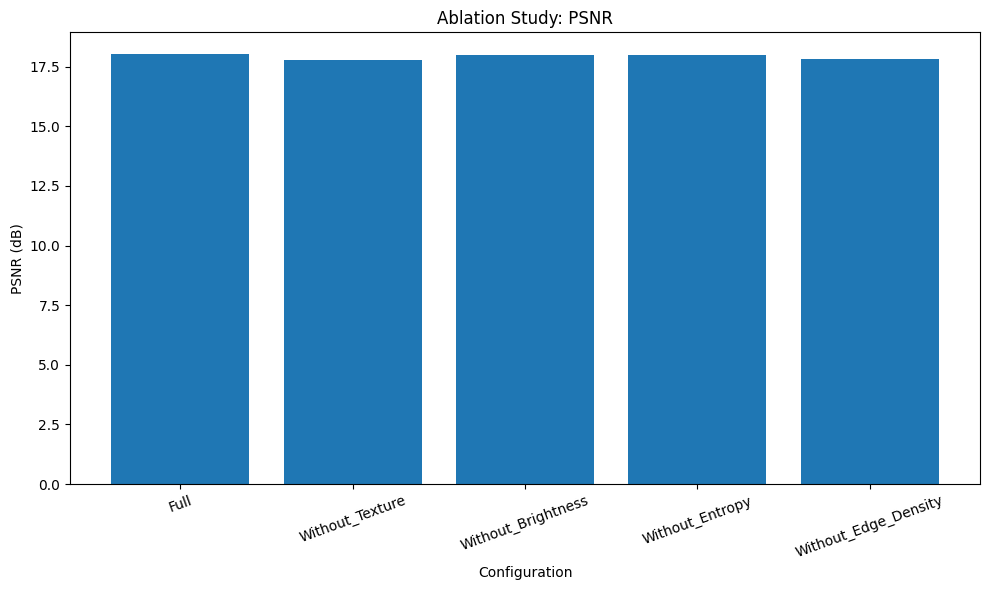

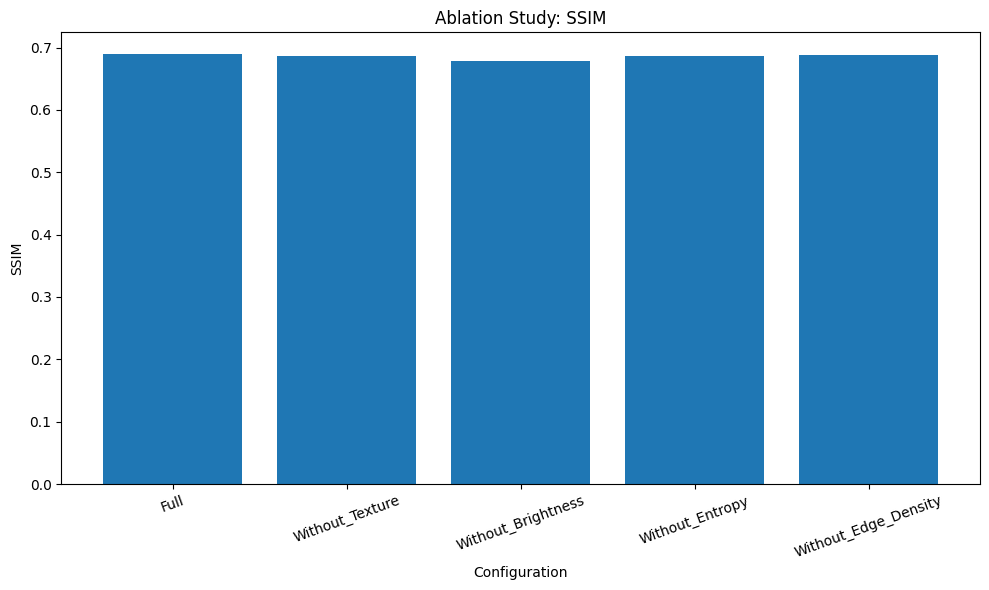

Saved:
/content/gdrive/MyDrive/Adaptive_LowLight_Research/08_Ablation/graphs/ablation_psnr.png
/content/gdrive/MyDrive/Adaptive_LowLight_Research/08_Ablation/graphs/ablation_ssim.png


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

GRAPH_DIR = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/08_Ablation/graphs"
)

os.makedirs(GRAPH_DIR, exist_ok=True)

# Keep logical order
method_order = [
    "Full",
    "Without_Texture",
    "Without_Brightness",
    "Without_Entropy",
    "Without_Edge_Density"
]

plot_df = (
    ablation_summary
    .set_index("Method")
    .loc[method_order]
    .reset_index()
)

# --------------------------------------------------
# PSNR
# --------------------------------------------------
plt.figure(figsize=(10, 6))

plt.bar(
    plot_df["Method"],
    plot_df["PSNR_mean"]
)

plt.ylabel("PSNR (dB)")
plt.xlabel("Configuration")
plt.title("Ablation Study: PSNR")
plt.xticks(rotation=20)
plt.tight_layout()

psnr_path = os.path.join(
    GRAPH_DIR,
    "ablation_psnr.png"
)

plt.savefig(
    psnr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# SSIM
# --------------------------------------------------
plt.figure(figsize=(10, 6))

plt.bar(
    plot_df["Method"],
    plot_df["SSIM_mean"]
)

plt.ylabel("SSIM")
plt.xlabel("Configuration")
plt.title("Ablation Study: SSIM")
plt.xticks(rotation=20)
plt.tight_layout()

ssim_path = os.path.join(
    GRAPH_DIR,
    "ablation_ssim.png"
)

plt.savefig(
    ssim_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(psnr_path)
print(ssim_path)

In [ ]:
print("PSNR graph exists:", os.path.exists(psnr_path))
print("SSIM graph exists:", os.path.exists(ssim_path))

PSNR graph exists: True
SSIM graph exists: True


In [ ]:
# Take a snapshot first so globals() cannot change during iteration
all_vars = list(globals().items())

print("Possible PSNR/SSIM dataframes:")
print()

found = False

for name, obj in all_vars:

    if isinstance(obj, pd.DataFrame):

        cols = [str(c).lower() for c in obj.columns]

        if "psnr" in cols and "ssim" in cols:

            print(
                f"Variable: {name}"
            )
            print(
                f"Shape: {obj.shape}"
            )
            print(
                f"Columns: {list(obj.columns)}"
            )
            print()

            found = True

if not found:
    print("No PSNR/SSIM dataframe found.")

Possible PSNR/SSIM dataframes:

Variable: candidate_results_df
Shape: (100, 6)
Columns: ['enhancement_strength', 'contrast', 'denoise_strength', 'psnr', 'ssim', 'score']

Variable: first_pseudo_df
Shape: (1, 11)
Columns: ['id', 'texture', 'brightness', 'entropy', 'edge_density', 'enhancement_strength', 'contrast', 'denoise_strength', 'psnr', 'ssim', 'score']

Variable: pseudo_df
Shape: (689, 15)
Columns: ['id', 'texture', 'brightness', 'entropy', 'edge_density', 'enhancement_strength', 'contrast', 'denoise_strength', 'psnr', 'ssim', 'score', 'zerodce_inference_time', 'strength_class', 'contrast_class', 'denoise_class']

Variable: duplicates
Shape: (3, 12)
Columns: ['id', 'texture', 'brightness', 'entropy', 'edge_density', 'enhancement_strength', 'contrast', 'denoise_strength', 'psnr', 'ssim', 'score', 'zerodce_inference_time']

Variable: final_df
Shape: (691, 12)
Columns: ['id', 'texture', 'brightness', 'entropy', 'edge_density', 'enhancement_strength', 'contrast', 'denoise_strength', 

In [ ]:
final_comparison = pd.DataFrame({
    "Method": [
        "Original Low-Light",
        "Standard Zero-DCE++",
        "Adaptive Zero-DCE++"
    ],

    "PSNR": [
        np.nan,
        np.nan,
        np.nan
    ],

    "SSIM": [
        np.nan,
        np.nan,
        np.nan
    ],

    "NIQE": [
        6.7912,
        8.0455,
        6.2424
    ],

    "BRISQUE": [
        15.8528,
        34.2771,
        20.6660
    ],

    "mAP@50": [
        0.501035,
        0.472880,
        0.465732
    ],

    "mAP@50:95": [
        0.269996,
        0.256832,
        0.254501
    ]
})

print(final_comparison.to_string(index=False))

             Method  PSNR  SSIM   NIQE  BRISQUE   mAP@50  mAP@50:95
 Original Low-Light   NaN   NaN 6.7912  15.8528 0.501035   0.269996
Standard Zero-DCE++   NaN   NaN 8.0455  34.2771 0.472880   0.256832
Adaptive Zero-DCE++   NaN   NaN 6.2424  20.6660 0.465732   0.254501


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# --------------------------------------------------
# Paths
# --------------------------------------------------

BASE = "/content/gdrive/MyDrive/Adaptive_LowLight_Research"

LOW_DIR = os.path.join(
    BASE,
    "01_Datasets/LOL_v2/Real_captured/Test/Low"
)

GT_DIR = os.path.join(
    BASE,
    "01_Datasets/LOL_v2/Real_captured/Test/Normal"
)

ADAPTIVE_DIR = os.path.join(
    BASE,
    "05_Validation/LOL/enhanced_images/Adaptive"
)

STANDARD_DIR = os.path.join(
    BASE,
    "05_Validation/LOL/enhanced_images/Standard_ZeroDCE"
)

print("Checking directories...")

for name, path in {
    "Low": LOW_DIR,
    "GT": GT_DIR,
    "Adaptive": ADAPTIVE_DIR,
    "Standard": STANDARD_DIR
}.items():
    print(f"{name:10s}: {os.path.exists(path)}")

Checking directories...
Low       : False
GT        : False
Adaptive  : False
Standard  : False


In [ ]:
import os

print("gdrive exists:",
      os.path.exists("/content/gdrive"))

print("MyDrive exists:",
      os.path.exists("/content/gdrive/MyDrive"))

if os.path.exists("/content/gdrive/MyDrive"):
    print("\nProject folders:")
    print(os.listdir("/content/gdrive/MyDrive")[:30])

gdrive exists: True
MyDrive exists: True

Project folders:
['Colab Notebooks', 'Getting started.pdf', 'Untitled spreadsheet (1).gsheet', 'Untitled spreadsheet.gsheet', 'inbound3176565082998256999.jpg', 'inbound3099604401441615836.jpg', 'Azom 5.ai', '20210222_194341 (1).jpg', 'IMG-20210227-WA0000.jpg', '20210222_194341.jpg', 'PicsArt_07-10-02.08.17.jpg', 'sakil ok.jpg', 'COVID-19 REPORT.pdf', 'Assainment-5th (2).pdf', '233699945_158514733025810_4532560450987129372_n.mp4', 'Assignment 7.pdf', 'IMG-20220313-WA0026-01.jpeg', 'PTT-20220625-WA0020.opus', 'IMG-20220625-WA0021.jpg', 'PTT-20220625-WA0022.opus', 'PTT-20220625-WA0023.opus', 'PTT-20220625-WA0028.opus', 'IMG-20220604-WA0027.jpg', 'PTT-20220625-WA0030.opus', 'PTT-20220625-WA0031.opus', 'PTT-20220625-WA0032.opus', 'PTT-20220625-WA0034.opus', 'PTT-20220625-WA0035.opus', 'IMG-20220625-WA0036.jpg', 'IMG-20220625-WA0037.jpg']


In [ ]:
import os

SEARCH_ROOT = "/content/gdrive/MyDrive/Adaptive_LowLight_Research"

matches = []

for root, dirs, files in os.walk(SEARCH_ROOT):

    if root.endswith("/Test/Low"):
        matches.append(root)

print("Found Test/Low directories:")

for path in matches:
    print(path)

Found Test/Low directories:
/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/LOL_v2/Synthetic/Test/Low
/content/gdrive/MyDrive/Adaptive_LowLight_Research/01_Datasets/LOL_v2/Real_captured/Test/Low


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

BASE = "/content/gdrive/MyDrive/Adaptive_LowLight_Research"

LOW_DIR = os.path.join(
    BASE,
    "01_Datasets/LOL_v2/Real_captured/Test/Low"
)

GT_DIR = os.path.join(
    BASE,
    "01_Datasets/LOL_v2/Real_captured/Test/Normal"
)

ADAPTIVE_DIR = os.path.join(
    BASE,
    "05_Validation/LOL/enhanced_images/Adaptive"
)

STANDARD_DIR = os.path.join(
    BASE,
    "05_Validation/LOL/enhanced_images/Standard_ZeroDCE"
)

print("Low:", os.path.exists(LOW_DIR))
print("GT:", os.path.exists(GT_DIR))
print("Adaptive:", os.path.exists(ADAPTIVE_DIR))
print("Standard:", os.path.exists(STANDARD_DIR))

Low: True
GT: True
Adaptive: True
Standard: True


In [ ]:
print("Low examples:")
print(sorted(os.listdir(LOW_DIR))[:5])

print("\nGT examples:")
print(sorted(os.listdir(GT_DIR))[:5])

print("\nAdaptive examples:")
print(sorted(os.listdir(ADAPTIVE_DIR))[:5])

print("\nStandard examples:")
print(sorted(os.listdir(STANDARD_DIR))[:5])

Low examples:
['low00690.png', 'low00691.png', 'low00692.png', 'low00693.png', 'low00694.png']

GT examples:
['normal00690.png', 'normal00691.png', 'normal00692.png', 'normal00693.png', 'normal00694.png']

Adaptive examples:
['00690.png', '00691.png', '00692.png', '00693.png', '00694.png']

Standard examples:
['00690.png', '00691.png', '00692.png', '00693.png', '00694.png']


In [ ]:
results = []

low_files = sorted([
    f for f in os.listdir(LOW_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

print("Low-light test images:", len(low_files))

for filename in low_files:

    # Example: low00690.png -> 00690
    image_id = os.path.splitext(filename)[0].replace("low", "")

    gt_path = os.path.join(
        GT_DIR,
        f"normal{image_id}.png"
    )

    adaptive_path = os.path.join(
        ADAPTIVE_DIR,
        f"{image_id}.png"
    )

    standard_path = os.path.join(
        STANDARD_DIR,
        f"{image_id}.png"
    )

    if not all([
        os.path.exists(gt_path),
        os.path.exists(adaptive_path),
        os.path.exists(standard_path)
    ]):
        print(f"Skipping {image_id}: missing file")
        continue

    # Read images
    gt = cv2.imread(gt_path)
    adaptive = cv2.imread(adaptive_path)
    standard = cv2.imread(standard_path)
    low = cv2.imread(
        os.path.join(LOW_DIR, filename)
    )

    if any(x is None for x in [gt, adaptive, standard, low]):
        print(f"Skipping {image_id}: read error")
        continue

    # BGR -> RGB
    gt = cv2.cvtColor(gt, cv2.COLOR_BGR2RGB)
    adaptive = cv2.cvtColor(adaptive, cv2.COLOR_BGR2RGB)
    standard = cv2.cvtColor(standard, cv2.COLOR_BGR2RGB)
    low = cv2.cvtColor(low, cv2.COLOR_BGR2RGB)

    # Match dimensions
    h = min(
        gt.shape[0],
        adaptive.shape[0],
        standard.shape[0],
        low.shape[0]
    )

    w = min(
        gt.shape[1],
        adaptive.shape[1],
        standard.shape[1],
        low.shape[1]
    )

    gt = gt[:h, :w]
    adaptive = adaptive[:h, :w]
    standard = standard[:h, :w]
    low = low[:h, :w]

    # -------------------------
    # Original
    # -------------------------
    original_psnr = peak_signal_noise_ratio(
        gt,
        low,
        data_range=255
    )

    original_ssim = structural_similarity(
        gt,
        low,
        channel_axis=2,
        data_range=255
    )

    # -------------------------
    # Standard Zero-DCE++
    # -------------------------
    standard_psnr = peak_signal_noise_ratio(
        gt,
        standard,
        data_range=255
    )

    standard_ssim = structural_similarity(
        gt,
        standard,
        channel_axis=2,
        data_range=255
    )

    # -------------------------
    # Adaptive Zero-DCE++
    # -------------------------
    adaptive_psnr = peak_signal_noise_ratio(
        gt,
        adaptive,
        data_range=255
    )

    adaptive_ssim = structural_similarity(
        gt,
        adaptive,
        channel_axis=2,
        data_range=255
    )

    results.append({
        "id": image_id,

        "Original_PSNR": original_psnr,
        "Original_SSIM": original_ssim,

        "Standard_PSNR": standard_psnr,
        "Standard_SSIM": standard_ssim,

        "Adaptive_PSNR": adaptive_psnr,
        "Adaptive_SSIM": adaptive_ssim
    })


psnr_ssim_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("RECONSTRUCTION COMPLETE")
print("=" * 70)

print("Number of evaluated images:", len(psnr_ssim_df))

print("\nFirst 5 results:")
print(psnr_ssim_df.head())

Low-light test images: 100

RECONSTRUCTION COMPLETE
Number of evaluated images: 100

First 5 results:
      id  Original_PSNR  Original_SSIM  Standard_PSNR  Standard_SSIM  \
0  00690       8.061480       0.160695      15.806470       0.549467   
1  00691       8.058351       0.156887      15.720434       0.513309   
2  00692       7.769077       0.105684      14.124666       0.571889   
3  00693       7.791677       0.109672      14.359996       0.596138   
4  00694       7.232841       0.115878      13.891985       0.570005   

   Adaptive_PSNR  Adaptive_SSIM  
0      14.549548       0.675186  
1      14.501890       0.649839  
2      13.090002       0.635452  
3      13.269253       0.653511  
4      12.799119       0.633127  


In [ ]:
psnr_ssim_summary = pd.DataFrame({
    "Method": [
        "Original Low-Light",
        "Standard Zero-DCE++",
        "Adaptive Zero-DCE++"
    ],

    "PSNR": [
        psnr_ssim_df["Original_PSNR"].mean(),
        psnr_ssim_df["Standard_PSNR"].mean(),
        psnr_ssim_df["Adaptive_PSNR"].mean()
    ],

    "SSIM": [
        psnr_ssim_df["Original_SSIM"].mean(),
        psnr_ssim_df["Standard_SSIM"].mean(),
        psnr_ssim_df["Adaptive_SSIM"].mean()
    ]
})

print(
    psnr_ssim_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

             Method    PSNR   SSIM
 Original Low-Light  9.7132 0.1959
Standard Zero-DCE++ 18.4425 0.5866
Adaptive Zero-DCE++ 18.0439 0.6900


In [ ]:
final_comparison = pd.DataFrame({
    "Method": [
        "Original Low-Light",
        "Standard Zero-DCE++",
        "Adaptive Zero-DCE++"
    ],

    "PSNR": [
        9.7132,
        18.4425,
        18.0439
    ],

    "SSIM": [
        0.1959,
        0.5866,
        0.6900
    ],

    "NIQE": [
        6.7912,
        8.0455,
        6.2424
    ],

    "BRISQUE": [
        15.8528,
        34.2771,
        20.6660
    ],

    "mAP@50": [
        0.501035,
        0.472880,
        0.465732
    ],

    "mAP@50:95": [
        0.269996,
        0.256832,
        0.254501
    ]
})

print("=" * 100)
print("FINAL COMPARISON")
print("=" * 100)

print(
    final_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

FINAL COMPARISON
             Method    PSNR   SSIM   NIQE  BRISQUE  mAP@50  mAP@50:95
 Original Low-Light  9.7132 0.1959 6.7912  15.8528  0.5010     0.2700
Standard Zero-DCE++ 18.4425 0.5866 8.0455  34.2771  0.4729     0.2568
Adaptive Zero-DCE++ 18.0439 0.6900 6.2424  20.6660  0.4657     0.2545


In [ ]:
FINAL_DIR = (
    "/content/gdrive/MyDrive/"
    "Adaptive_LowLight_Research/10_Final_Results"
)

os.makedirs(
    os.path.join(FINAL_DIR, "tables"),
    exist_ok=True
)

final_table_path = os.path.join(
    FINAL_DIR,
    "tables",
    "final_comparison.csv"
)

final_comparison.to_csv(
    final_table_path,
    index=False
)

print("Saved:", final_table_path)

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/tables/final_comparison.csv


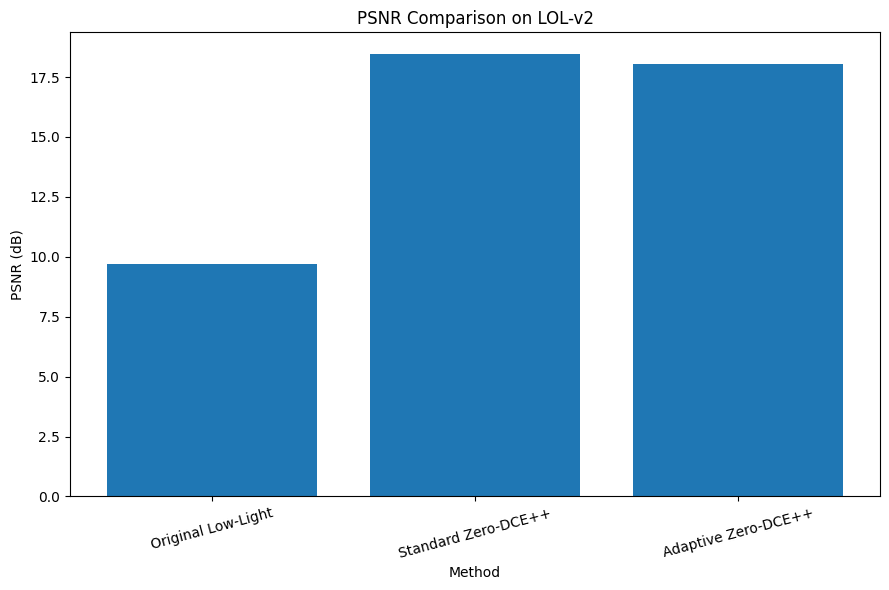

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/final_psnr_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import os

FIG_DIR = os.path.join(
    FINAL_DIR,
    "figures"
)

os.makedirs(FIG_DIR, exist_ok=True)

methods = final_comparison["Method"]
psnr_values = final_comparison["PSNR"]

plt.figure(figsize=(9, 6))

plt.bar(methods, psnr_values)

plt.ylabel("PSNR (dB)")
plt.xlabel("Method")
plt.title("PSNR Comparison on LOL-v2")

plt.xticks(rotation=15)
plt.tight_layout()

path = os.path.join(
    FIG_DIR,
    "final_psnr_comparison.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", path)

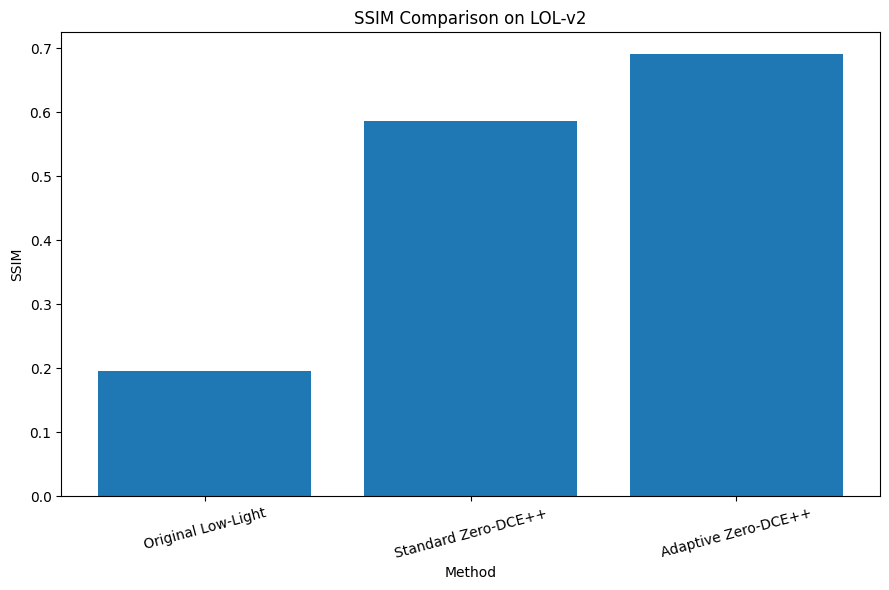

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/final_ssim_comparison.png


In [ ]:
ssim_values = final_comparison["SSIM"]

plt.figure(figsize=(9, 6))

plt.bar(methods, ssim_values)

plt.ylabel("SSIM")
plt.xlabel("Method")
plt.title("SSIM Comparison on LOL-v2")

plt.xticks(rotation=15)
plt.tight_layout()

path = os.path.join(
    FIG_DIR,
    "final_ssim_comparison.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", path)

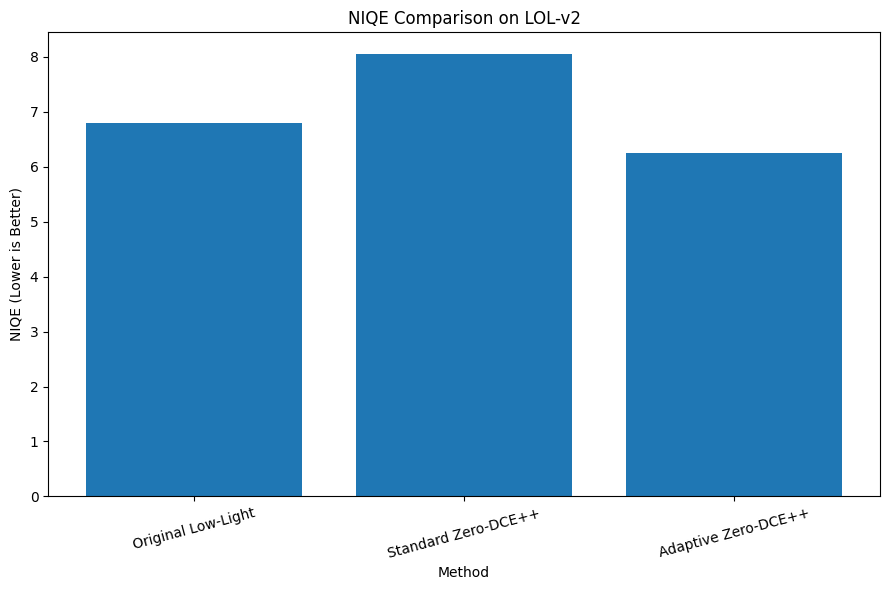

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/final_niqe_comparison.png


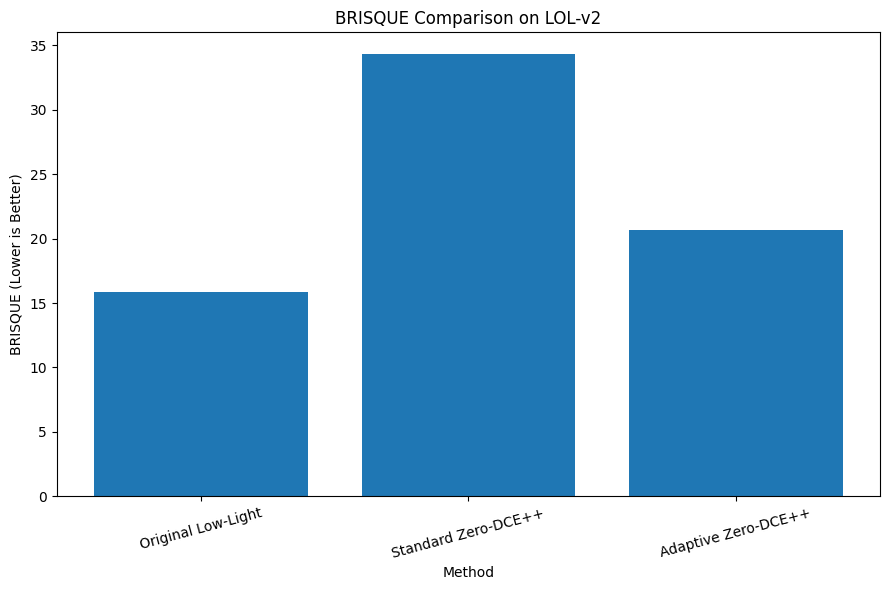

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/final_brisque_comparison.png


In [ ]:
figures = [
    ("NIQE", "NIQE Comparison on LOL-v2", "final_niqe_comparison.png"),
    ("BRISQUE", "BRISQUE Comparison on LOL-v2", "final_brisque_comparison.png")
]

for metric, title, filename in figures:

    plt.figure(figsize=(9, 6))

    plt.bar(
        final_comparison["Method"],
        final_comparison[metric]
    )

    plt.ylabel(metric + " (Lower is Better)")
    plt.xlabel("Method")
    plt.title(title)

    plt.xticks(rotation=15)
    plt.tight_layout()

    path = os.path.join(FIG_DIR, filename)

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", path)

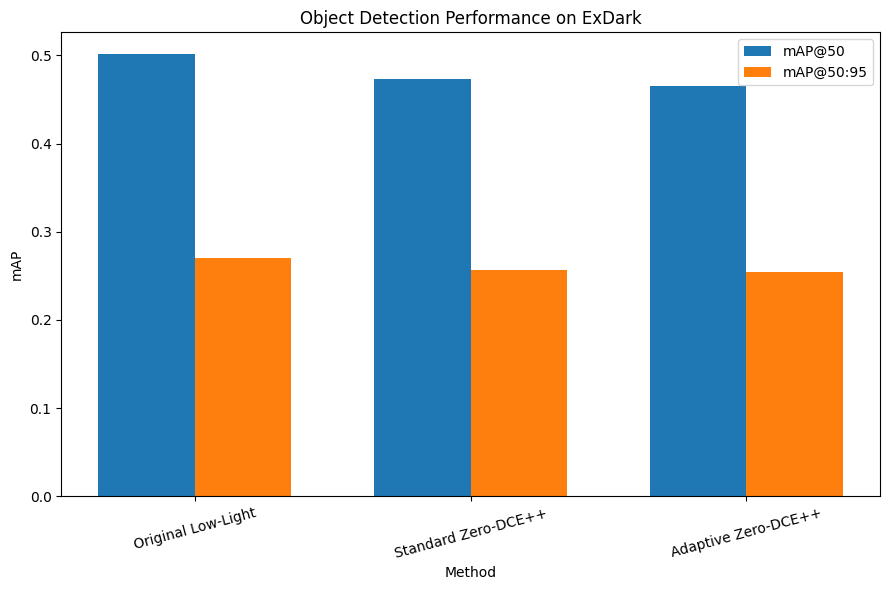

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/final_detection_comparison.png


In [ ]:
x = np.arange(len(final_comparison))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width/2,
    final_comparison["mAP@50"],
    width,
    label="mAP@50"
)

plt.bar(
    x + width/2,
    final_comparison["mAP@50:95"],
    width,
    label="mAP@50:95"
)

plt.xticks(
    x,
    final_comparison["Method"],
    rotation=15
)

plt.ylabel("mAP")
plt.xlabel("Method")
plt.title("Object Detection Performance on ExDark")

plt.legend()
plt.tight_layout()

path = os.path.join(
    FIG_DIR,
    "final_detection_comparison.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", path)

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

QUAL_DIR = os.path.join(
    FINAL_DIR,
    "figures"
)

os.makedirs(QUAL_DIR, exist_ok=True)

# Representative images
selected_ids = [
    "00690",
    "00726",
    "00729",
    "00763",
    "00779"
]

print("Selected images:")
for image_id in selected_ids:
    print(image_id)

Selected images:
00690
00726
00729
00763
00779


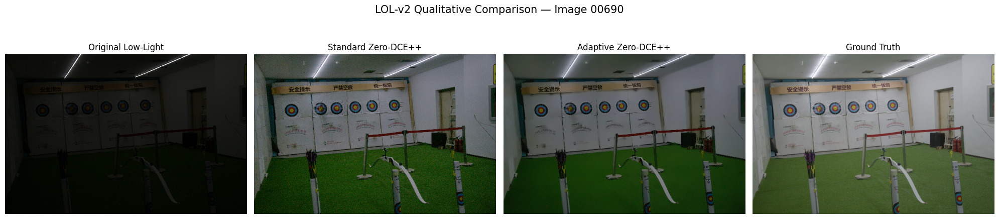

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/qualitative_00690.png


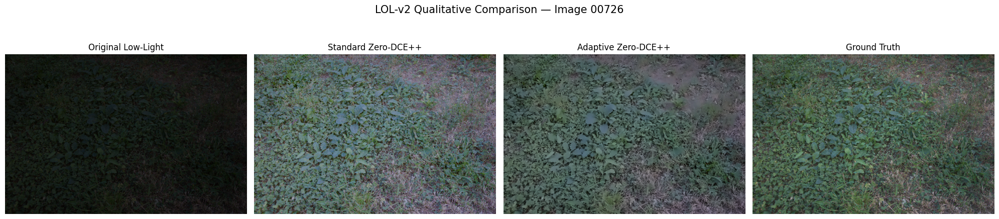

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/qualitative_00726.png


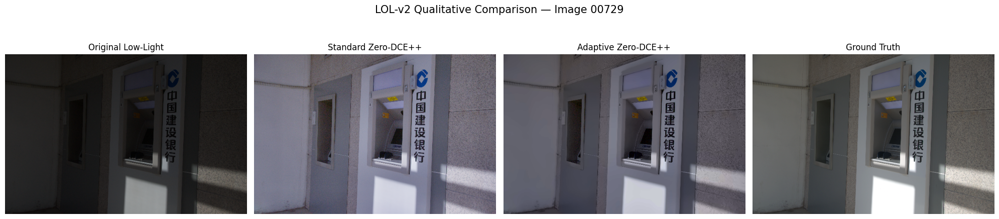

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/qualitative_00729.png


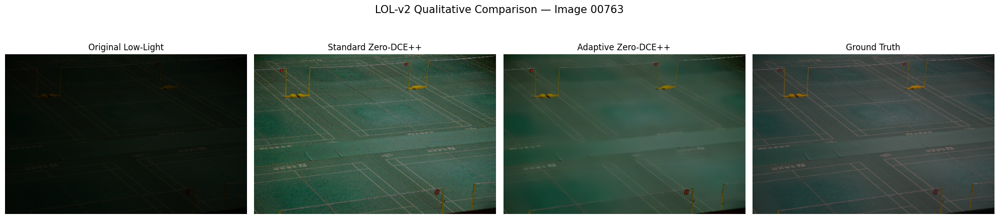

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/qualitative_00763.png


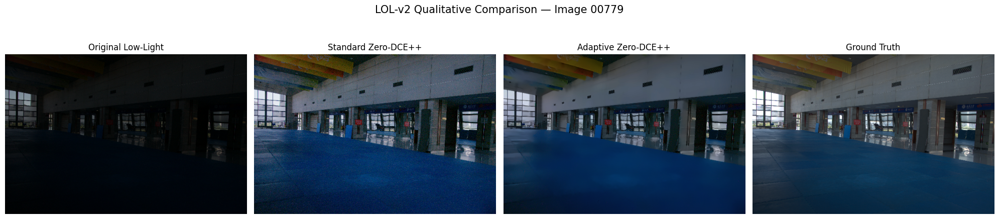

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/qualitative_00779.png


In [ ]:
for image_id in selected_ids:

    low_path = os.path.join(
        LOW_DIR,
        f"low{image_id}.png"
    )

    gt_path = os.path.join(
        GT_DIR,
        f"normal{image_id}.png"
    )

    standard_path = os.path.join(
        STANDARD_DIR,
        f"{image_id}.png"
    )

    adaptive_path = os.path.join(
        ADAPTIVE_DIR,
        f"{image_id}.png"
    )

    # Read
    low = cv2.imread(low_path)
    gt = cv2.imread(gt_path)
    standard = cv2.imread(standard_path)
    adaptive = cv2.imread(adaptive_path)

    # BGR -> RGB
    low = cv2.cvtColor(low, cv2.COLOR_BGR2RGB)
    gt = cv2.cvtColor(gt, cv2.COLOR_BGR2RGB)
    standard = cv2.cvtColor(standard, cv2.COLOR_BGR2RGB)
    adaptive = cv2.cvtColor(adaptive, cv2.COLOR_BGR2RGB)

    # Match dimensions
    h = min(
        low.shape[0],
        gt.shape[0],
        standard.shape[0],
        adaptive.shape[0]
    )

    w = min(
        low.shape[1],
        gt.shape[1],
        standard.shape[1],
        adaptive.shape[1]
    )

    low = low[:h, :w]
    gt = gt[:h, :w]
    standard = standard[:h, :w]
    adaptive = adaptive[:h, :w]

    # Create figure
    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5)
    )

    images = [
        low,
        standard,
        adaptive,
        gt
    ]

    titles = [
        "Original Low-Light",
        "Standard Zero-DCE++",
        "Adaptive Zero-DCE++",
        "Ground Truth"
    ]

    for ax, image, title in zip(
        axes,
        images,
        titles
    ):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(
        f"LOL-v2 Qualitative Comparison — Image {image_id}",
        fontsize=15
    )

    plt.tight_layout()

    output_path = os.path.join(
        QUAL_DIR,
        f"qualitative_{image_id}.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Saved:", output_path)

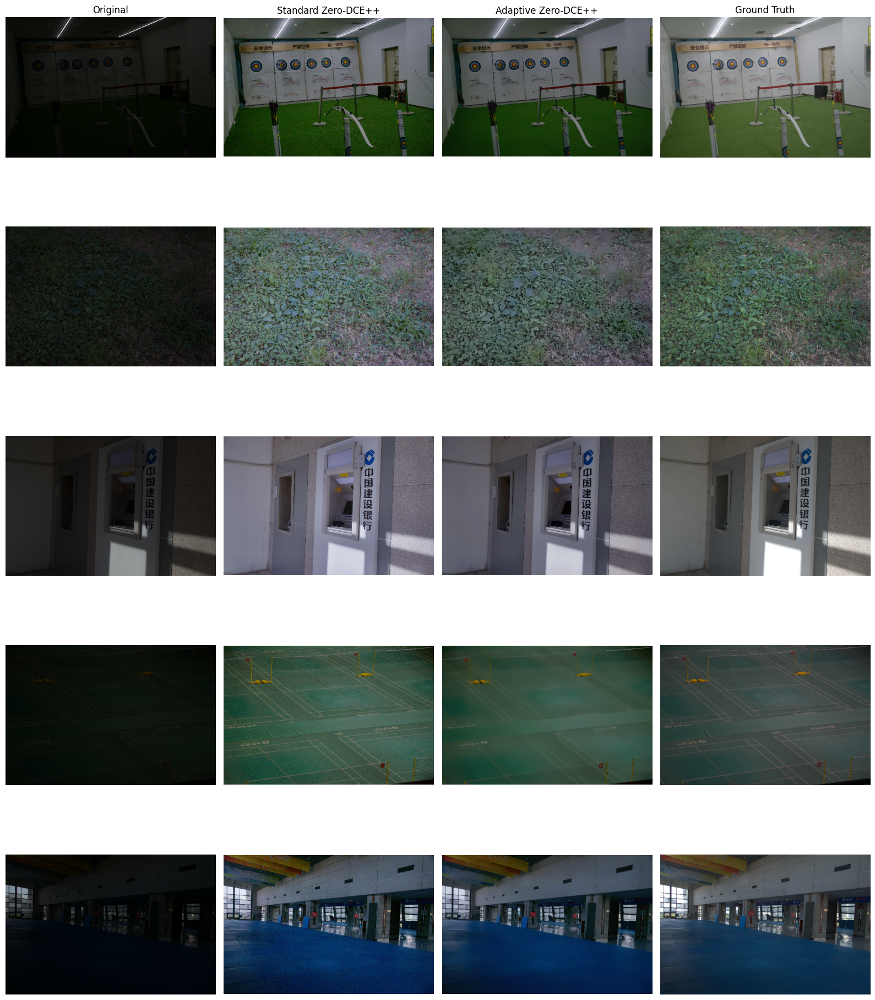

Saved: /content/gdrive/MyDrive/Adaptive_LowLight_Research/10_Final_Results/figures/qualitative_comparison_all.png


In [ ]:
fig, axes = plt.subplots(
    len(selected_ids),
    4,
    figsize=(16, 20)
)

for row_idx, image_id in enumerate(selected_ids):

    paths = [
        os.path.join(LOW_DIR, f"low{image_id}.png"),
        os.path.join(STANDARD_DIR, f"{image_id}.png"),
        os.path.join(ADAPTIVE_DIR, f"{image_id}.png"),
        os.path.join(GT_DIR, f"normal{image_id}.png")
    ]

    titles = [
        "Original",
        "Standard Zero-DCE++",
        "Adaptive Zero-DCE++",
        "Ground Truth"
    ]

    for col_idx, path in enumerate(paths):

        image = cv2.imread(path)
        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        axes[row_idx, col_idx].imshow(image)
        axes[row_idx, col_idx].axis("off")

        if row_idx == 0:
            axes[row_idx, col_idx].set_title(
                titles[col_idx],
                fontsize=12
            )

    axes[row_idx, 0].set_ylabel(
        f"Image {image_id}",
        fontsize=11
    )

plt.tight_layout()

combined_path = os.path.join(
    QUAL_DIR,
    "qualitative_comparison_all.png"
)

plt.savefig(
    combined_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved:", combined_path)

In [ ]:
print("=" * 110)
print("FINAL EXPERIMENTAL RESULTS")
print("=" * 110)

print(
    final_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

FINAL EXPERIMENTAL RESULTS
             Method    PSNR   SSIM   NIQE  BRISQUE  mAP@50  mAP@50:95
 Original Low-Light  9.7132 0.1959 6.7912  15.8528  0.5010     0.2700
Standard Zero-DCE++ 18.4425 0.5866 8.0455  34.2771  0.4729     0.2568
Adaptive Zero-DCE++ 18.0439 0.6900 6.2424  20.6660  0.4657     0.2545


In [ ]:
standard = final_comparison[
    final_comparison["Method"] == "Standard Zero-DCE++"
].iloc[0]

adaptive = final_comparison[
    final_comparison["Method"] == "Adaptive Zero-DCE++"
].iloc[0]

print("=" * 80)
print("ADAPTIVE vs STANDARD")
print("=" * 80)

metrics = [
    ("PSNR", True),
    ("SSIM", True),
    ("NIQE", False),
    ("BRISQUE", False),
    ("mAP@50", True),
    ("mAP@50:95", True)
]

for metric, higher_better in metrics:

    absolute_change = (
        adaptive[metric] - standard[metric]
    )

    percentage_change = (
        absolute_change / standard[metric]
    ) * 100

    print(
        f"{metric:12s}: "
        f"change = {absolute_change:+.4f}, "
        f"percentage = {percentage_change:+.2f}%"
    )

ADAPTIVE vs STANDARD
PSNR        : change = -0.3986, percentage = -2.16%
SSIM        : change = +0.1034, percentage = +17.63%
NIQE        : change = -1.8031, percentage = -22.41%
BRISQUE     : change = -13.6111, percentage = -39.71%
mAP@50      : change = -0.0071, percentage = -1.51%
mAP@50:95   : change = -0.0023, percentage = -0.91%
